# iPSC-EC CRT QQ export: full covariates + biological replicate effect correlation

This notebook runs the d0–d3 iPSC-EC CRT QQ export using the requested covariates:

- `pct_counts_mt`
- `biological_sample`
- `total_counts`
- `guides_per_cell`
- `guide_umi_counts`
- `n_genes_by_counts`

`biological_sample` is one-hot encoded with one reference level dropped for the full-day CRT. The count-like covariates are `log1p` transformed. The notebook writes the backend script into the current directory, runs it, validates the covariates recorded in each day's config, and saves Illustrator-editable QQ plots as PDF/SVG/EPS files.

The last section reruns the CRT within each `biological_sample` to export one beta-effect matrix per biological replicate, then makes biological replicate correlation scatterplots of DE program effects. Each scatterplot point is one real `target_name × program_name` beta effect compared across two biological samples from the same day.


In [1]:
from pathlib import Path
import json
import os
import shlex
import subprocess
import sys

# Set thread-count defaults before NumPy/SciPy get imported by the backend.
for variable in [
    "OMP_NUM_THREADS",
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "BLIS_NUM_THREADS",
    "NUMEXPR_NUM_THREADS",
]:
    os.environ.setdefault(variable, "1")

PROGRAMDE_ROOT = "/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE"
DATA_DIR = "/oak/stanford/groups/engreitz/Users/opushkar/cc_perturb/2.preprocessing_tonys_pipeline/2.normalized_data/normalized_data"
CNMF_DIR = "/oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all"
GUIDE_LONG_TEMPLATE = "/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/{day}_sceptre_transfer/{day}_grna_assignments_long.csv"
GUIDE_METADATA_TSV = "./300genes_guide_metadata_v43.tsv"

OUT_DIR = "results/ipsc_ec_qq_exports_full_covariates"
DAYS = ["d0", "d1", "d2", "d3"]
K = 50
DENSITY_THRESHOLD = "0_2"
B = 10000
N_JOBS = int(os.environ.get("SLURM_CPUS_PER_TASK", "4"))
NTC_LABELS = ["SAFE", "non-targeting", "NTC"]

# Rerun controls. Keep OVERWRITE=True when changing covariates.
REQUIRE_COVARIATES = True
OVERWRITE = True
NO_BACKEND_PLOTS = True   # plotnine Illustrator files are made in later cells
NO_SKEW = False           # set True only if you want empirical p-values only

MODEL_ROOT = Path(OUT_DIR) / f"k_{K}.dt_{DENSITY_THRESHOLD}"
print("Output root:", MODEL_ROOT)
print("N_JOBS:", N_JOBS)


Output root: results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2
N_JOBS: 8


## Write the backend script

Run this cell once before the dry run or full run. It overwrites `iPSC_EC_QQ_export_all_days.py` in the current working directory with the full-covariate version.

In [2]:
%%writefile iPSC_EC_QQ_export_all_days.py
#!/usr/bin/env python
"""
Export iPSC-EC CRT QQ-plot p-value points for d0, d1, d2, and d3.

This version uses the full requested covariate adjustment set:
pct_counts_mt, biological_sample, total_counts, guides_per_cell,
guide_umi_counts, and n_genes_by_counts.

This script adapts the simple QQ export pattern from the IP/GV K30 dt2
bundle to the iPSC-EC notebooks.  It uses the source paths and setup used in
qq_sweep_test.ipynb and ipsc_ec_qq.ipynb:

  * H5MU source files: {day}_normalized_gex_and_guide.h5mu
  * cNMF usage files: *.usages.k_{K}.dt_{density_threshold}.consensus.txt
  * guide assignment long tables: {day}_grna_assignments_long.csv

The main exported files are per-day CSVs containing the exact p-values and the
ranked expected/observed -log10(p) coordinates needed to replot the QQ plots.
"""

from __future__ import annotations

# Set thread-count defaults before importing NumPy/SciPy.
import os

for _variable in [
    "OMP_NUM_THREADS",
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "BLIS_NUM_THREADS",
    "NUMEXPR_NUM_THREADS",
]:
    os.environ.setdefault(_variable, "1")

import argparse
import inspect
import json
import re
import sys
import time
import warnings
from dataclasses import asdict, dataclass
from pathlib import Path
from types import SimpleNamespace
from typing import Any, Iterable

import numpy as np
import pandas as pd


DEFAULT_PROGRAMDE_ROOT = "/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE"
DEFAULT_DATA_DIR = (
    "/oak/stanford/groups/engreitz/Users/opushkar/cc_perturb/"
    "2.preprocessing_tonys_pipeline/2.normalized_data/normalized_data"
)
DEFAULT_CNMF_DIR = (
    "/oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/"
    "012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7/"
    "012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all"
)
DEFAULT_GUIDE_LONG_TEMPLATE = (
    "/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/"
    "{day}_sceptre_transfer/{day}_grna_assignments_long.csv"
)
DEFAULT_DAYS = ["d0", "d1", "d2", "d3"]
DEFAULT_NTC_LABELS = ["SAFE", "non-targeting", "NTC"]


@dataclass
class DayRunSummary:
    day: str
    status: str
    output_dir: str
    h5mu_path: str | None = None
    usage_path: str | None = None
    guide_long_csv: str | None = None
    n_cells: int | None = None
    n_programs: int | None = None
    n_guides: int | None = None
    n_covariates: int | None = None
    matched_usage_cells: int | None = None
    n_observed_target_empirical_points: int | None = None
    n_ntc_pseudotarget_empirical_points: int | None = None
    n_observed_target_skew_points: int | None = None
    n_ntc_pseudotarget_skew_points: int | None = None
    message: str | None = None


def safe_name(value: object) -> str:
    """Return a filesystem-safe label."""
    return re.sub(r"[^A-Za-z0-9_.-]+", "_", str(value)).strip("_") or "value"


def normalize_density_token(value: object) -> str:
    """Normalize density threshold labels to the dt token used by cNMF filenames."""
    text = str(value).strip()
    text = re.sub(r"^dt[_-]?", "", text, flags=re.IGNORECASE)
    text = text.replace(".", "_").replace("-", "_")
    text = re.sub(r"_+", "_", text).strip("_")
    if not text:
        raise ValueError("Density threshold token is empty.")
    return text


def model_tag(k: int, density_token: str) -> str:
    return f"k_{k}.dt_{density_token}"


def read_table_auto(path: Path) -> pd.DataFrame:
    """Read TSV/CSV files with a conservative delimiter guess."""
    suffix = path.suffix.lower()
    if suffix in {".tsv", ".txt"}:
        return pd.read_csv(path, sep="\t")
    if suffix == ".csv":
        return pd.read_csv(path)
    return pd.read_csv(path, sep=None, engine="python")


def load_programde(programde_root: str | None) -> SimpleNamespace:
    """Import programDE functions after adding the requested repository path."""
    if programde_root:
        root = str(Path(programde_root).expanduser())
        if root not in sys.path:
            sys.path.insert(0, root)

    from src.sceptre import (  # type: ignore
        build_ntc_group_inputs,
        crt_pvals_for_ntc_groups_ensemble,
        crt_pvals_for_ntc_groups_ensemble_skew,
        make_ntc_groups_ensemble,
        prepare_crt_inputs,
        run_all_genes_union_crt,
    )

    try:
        from src.sceptre import compute_ntc_group_null_pvals_parallel  # type: ignore
    except (ImportError, AttributeError):
        compute_ntc_group_null_pvals_parallel = None

    try:
        from src.sceptre import limit_threading  # type: ignore

        limit_threading()
    except (ImportError, AttributeError):
        pass

    try:
        from src.visualization import qq_plot_ntc_pvals  # type: ignore
    except (ImportError, AttributeError):
        qq_plot_ntc_pvals = None

    return SimpleNamespace(
        build_ntc_group_inputs=build_ntc_group_inputs,
        crt_pvals_for_ntc_groups_ensemble=crt_pvals_for_ntc_groups_ensemble,
        crt_pvals_for_ntc_groups_ensemble_skew=crt_pvals_for_ntc_groups_ensemble_skew,
        make_ntc_groups_ensemble=make_ntc_groups_ensemble,
        prepare_crt_inputs=prepare_crt_inputs,
        run_all_genes_union_crt=run_all_genes_union_crt,
        compute_ntc_group_null_pvals_parallel=compute_ntc_group_null_pvals_parallel,
        qq_plot_ntc_pvals=qq_plot_ntc_pvals,
    )


def resolve_modality(mdata: Any, preferred: str | None, fallbacks: list[str], label: str) -> str:
    """Resolve a modality name in a MuData object."""
    modalities = list(mdata.mod.keys())
    candidates = []
    if preferred:
        candidates.append(preferred)
    candidates.extend(fallbacks)

    for candidate in candidates:
        if candidate in mdata.mod:
            return candidate

    lowered = {name.lower(): name for name in modalities}
    for candidate in candidates:
        if candidate and candidate.lower() in lowered:
            return lowered[candidate.lower()]

    raise KeyError(
        f"Could not find {label} modality. Tried {candidates}; available modalities: {modalities}"
    )


def infer_guide2gene_from_names(
    guide_names: Iterable[str],
    ntc_labels: list[str],
) -> dict[str, str]:
    """Infer guide-to-target names using the ipsc_ec_qq.ipynb split rule."""
    labels_lower = {label.lower(): label for label in ntc_labels}
    mapping: dict[str, str] = {}
    for guide in map(str, guide_names):
        cleaned = guide.strip()
        lowered = cleaned.lower()
        matched_control = None
        for label_lower, label in labels_lower.items():
            if (
                lowered == label_lower
                or lowered.startswith(label_lower + "_")
                or lowered.startswith(label_lower + "-")
                or lowered.startswith(label_lower + ".")
            ):
                matched_control = label
                break
        mapping[guide] = matched_control if matched_control is not None else cleaned.split("_", 1)[0]
    return mapping


def load_guide2gene_metadata(
    path: Path,
    guide_names: list[str],
    guide_col: str | None,
    target_col: str | None,
) -> dict[str, str]:
    """Optionally load guide-to-target mapping from a metadata table."""
    table = read_table_auto(path)
    normalized_columns = {column.lower().replace(" ", "_"): column for column in table.columns}

    guide_candidates = [
        guide_col,
        "guide_name",
        "guide_id",
        "guide",
        "grna",
        "grna_name",
        "grna_id",
        "sgrna",
        "protospacer",
    ]
    target_candidates = [
        target_col,
        "target_name",
        "target",
        "gene",
        "gene_symbol",
        "symbol",
        "grna_target",
    ]

    resolved_guide_col = None
    for candidate in guide_candidates:
        if not candidate:
            continue
        key = candidate.lower().replace(" ", "_")
        if key in normalized_columns:
            resolved_guide_col = normalized_columns[key]
            break

    resolved_target_col = None
    for candidate in target_candidates:
        if not candidate:
            continue
        key = candidate.lower().replace(" ", "_")
        if key in normalized_columns and normalized_columns[key] != resolved_guide_col:
            resolved_target_col = normalized_columns[key]
            break

    if resolved_guide_col is None or resolved_target_col is None:
        raise KeyError(
            "Could not infer guide/target columns in guide metadata. "
            f"Columns were: {list(table.columns)}. "
            "Use --guide-metadata-guide-col and --guide-metadata-target-col."
        )

    raw_mapping = dict(
        zip(
            table[resolved_guide_col].astype(str),
            table[resolved_target_col].astype(str),
        )
    )
    return {guide: raw_mapping[guide] for guide in guide_names if guide in raw_mapping}


def build_guide2gene(
    guide_names: list[str],
    ntc_labels: list[str],
    metadata_tsv: str | None,
    guide_col: str | None,
    target_col: str | None,
) -> dict[str, str]:
    """Build guide-to-target mapping, defaulting to guide_name.split('_', 1)[0]."""
    mapping = infer_guide2gene_from_names(guide_names, ntc_labels)

    if metadata_tsv:
        metadata_path = Path(metadata_tsv).expanduser()
        if metadata_path.exists():
            try:
                metadata_mapping = load_guide2gene_metadata(
                    metadata_path,
                    guide_names,
                    guide_col,
                    target_col,
                )
                mapping.update(metadata_mapping)
                print(
                    f"guide metadata: mapped {len(metadata_mapping):,}/{len(guide_names):,} guides "
                    f"from {metadata_path}"
                )
            except Exception as exc:  # keep fallback mapping usable
                warnings.warn(
                    f"Guide metadata {metadata_path} could not be used ({exc}). "
                    "Falling back to guide_name.split('_', 1)[0]."
                )
        else:
            warnings.warn(
                f"Guide metadata file {metadata_path} was not found. "
                "Falling back to guide_name.split('_', 1)[0]."
            )
    return mapping


def h5mu_path_for_day(data_dir: Path, day: str) -> Path:
    return data_dir / f"{day}_normalized_gex_and_guide.h5mu"


def guide_long_path_for_day(template: str, day: str) -> Path:
    return Path(template.format(day=day)).expanduser()


def usage_candidates_from_args(args: argparse.Namespace, day: str, density_token: str) -> list[Path]:
    """Resolve or discover cNMF usage-file candidates."""
    if args.cnmf_file:
        return [Path(args.cnmf_file).expanduser()]

    if args.usage_file_template:
        return [
            Path(
                args.usage_file_template.format(
                    day=day,
                    k=args.k,
                    K=args.k,
                    dt=density_token,
                    density_threshold=density_token,
                    density=density_token,
                )
            ).expanduser()
        ]

    cnmf_dir = Path(args.cnmf_dir).expanduser()
    if cnmf_dir.is_file():
        return [cnmf_dir]

    exact_patterns = [
        f"**/*.usages.k_{args.k}.dt_{density_token}.consensus.txt",
        f"**/*usages*k_{args.k}*dt_{density_token}*consensus*.txt",
        f"**/*k_{args.k}*dt_{density_token}*usage*.txt",
        f"**/*k_{args.k}*dt_{density_token}*.txt",
    ]
    candidates: list[Path] = []
    for pattern in exact_patterns:
        candidates.extend(cnmf_dir.glob(pattern))

    # De-duplicate while preserving order.
    seen = set()
    unique = []
    for path in candidates:
        resolved = path.resolve()
        if resolved not in seen:
            unique.append(path)
            seen.add(resolved)
    return unique


def score_usage_file(path: Path, obs_names: pd.Index) -> tuple[int, int]:
    """Score a usage file by overlap with the day-specific cells."""
    first_column = pd.read_csv(path, sep="\t", usecols=[0], dtype=str).iloc[:, 0]
    usage_index = pd.Index(first_column.astype(str))
    overlap = int(usage_index.intersection(obs_names.astype(str)).size)
    size_penalty = -abs(len(usage_index) - len(obs_names))
    return overlap, size_penalty


def choose_usage_file(candidates: list[Path], obs_names: pd.Index, day: str) -> tuple[Path, int]:
    """Choose the usage file with the best cell-overlap score."""
    existing = [path for path in candidates if path.exists()]
    if not existing:
        raise FileNotFoundError(
            f"No cNMF usage file exists for {day}. Candidate paths were: {candidates}"
        )

    scores = []
    for path in existing:
        try:
            overlap, size_penalty = score_usage_file(path, obs_names)
        except Exception as exc:
            warnings.warn(f"Could not score usage file {path}: {exc}")
            overlap, size_penalty = -1, -10**12
        scores.append((overlap, size_penalty, path))

    scores.sort(key=lambda item: (item[0], item[1], str(item[2])), reverse=True)
    best_overlap, _, best_path = scores[0]
    if best_overlap <= 0:
        raise ValueError(
            f"Best usage file for {day} had no overlap with the H5MU cells: {best_path}"
        )
    if len(scores) > 1:
        print("usage candidates scored for", day)
        for overlap, _, path in scores[:5]:
            print(f"  overlap={overlap:,}  {path}")
        print(f"selected usage file for {day}: {best_path}")
    return best_path, best_overlap


def floor_and_normalize_usage(usage: pd.DataFrame) -> pd.DataFrame:
    """Apply the cNMF zero flooring and row normalization used in ipsc_ec_qq.ipynb."""
    values = usage.to_numpy(dtype=float, copy=True)
    if values.ndim != 2 or values.shape[0] == 0 or values.shape[1] == 0:
        raise ValueError(f"Invalid usage matrix shape: {values.shape}")

    positive = values[values > 0]
    eps = max(1e-8, float(np.quantile(positive, 0.01)) * 0.1) if positive.size else 1e-8
    values = np.where(values > 0, values, eps)
    row_sums = values.sum(axis=1, keepdims=True)
    if np.any(row_sums <= 0) or not np.isfinite(row_sums).all():
        raise ValueError("Usage matrix has invalid row sums after flooring.")
    values = values / row_sums
    return pd.DataFrame(values, index=usage.index, columns=usage.columns)


def load_and_attach_usage(
    adata: Any,
    usage_path: Path,
) -> tuple[pd.DataFrame, int]:
    """Load, align, floor, normalize, and attach cNMF usage to adata.obsm."""
    usage_raw = pd.read_csv(usage_path, sep="\t", index_col=0)
    usage_raw.index = usage_raw.index.astype(str)
    usage_raw.columns = usage_raw.columns.astype(str)

    obs_names = pd.Index(adata.obs_names.astype(str))
    matched = int(usage_raw.index.intersection(obs_names).size)
    usage_aligned = usage_raw.reindex(obs_names).fillna(0.0)
    usage_aligned.index = adata.obs_names
    usage_aligned = floor_and_normalize_usage(usage_aligned)

    adata.obsm["cnmf_usage"] = usage_aligned
    adata.uns["program_names"] = list(usage_aligned.columns)
    return usage_aligned, matched


def load_and_attach_guides(
    adata: Any,
    mdata: Any,
    guide_modality: str,
    guide_long_csv: Path,
    ntc_labels: list[str],
    metadata_tsv: str | None,
    metadata_guide_col: str | None,
    metadata_target_col: str | None,
) -> tuple[list[str], dict[str, str]]:
    """Load guide assignments from the day-specific long CSV and attach them."""
    guide_names = list(map(str, mdata[guide_modality].var_names))
    adata.uns["guide_names"] = guide_names

    if guide_long_csv.exists():
        guide_long = pd.read_csv(guide_long_csv)
        required = {"cell_id", "grna_target", "value"}
        missing = required.difference(guide_long.columns)
        if missing:
            raise KeyError(
                f"Guide long CSV {guide_long_csv} is missing columns {sorted(missing)}; "
                f"observed columns were {list(guide_long.columns)}"
            )

        guide_dense = guide_long.pivot_table(
            index="cell_id",
            columns="grna_target",
            values="value",
            fill_value=0,
            aggfunc="max",
        )
        guide_dense.index = guide_dense.index.astype(str)
        guide_dense.columns = guide_dense.columns.astype(str)

        extra_columns = sorted(set(guide_dense.columns) - set(guide_names))
        if extra_columns:
            warnings.warn(
                f"{len(extra_columns):,} guide columns in {guide_long_csv} were not in "
                "mdata['guide'].var_names and will be ignored. First few: "
                f"{extra_columns[:5]}"
            )

        guide_aligned = guide_dense.reindex(
            index=adata.obs_names.astype(str),
            columns=guide_names,
            fill_value=0,
        )
        guide_aligned.index = adata.obs_names
        guide_aligned = (guide_aligned > 0).astype(np.int8)
        adata.obsm["guide_assignment"] = guide_aligned
    elif "guide_assignment" in adata.obsm:
        warnings.warn(
            f"Guide long CSV {guide_long_csv} was not found; using existing adata.obsm['guide_assignment']."
        )
    elif "guide_assignments" in adata.obsm:
        warnings.warn(
            f"Guide long CSV {guide_long_csv} was not found; using existing adata.obsm['guide_assignments']."
        )
        adata.obsm["guide_assignment"] = adata.obsm["guide_assignments"]
    else:
        raise FileNotFoundError(
            f"Guide long CSV {guide_long_csv} was not found and no guide assignment matrix exists in GEX.obsm."
        )

    guide2gene = build_guide2gene(
        guide_names,
        ntc_labels,
        metadata_tsv,
        metadata_guide_col,
        metadata_target_col,
    )
    adata.uns["guide2gene"] = guide2gene
    return guide_names, guide2gene


def attach_covariates(adata: Any, require_covariates: bool = False) -> pd.DataFrame:
    """Attach the full requested iPSC-EC CRT covariate set.

    Source columns in adata.obs:
      * pct_counts_mt: percent mitochondrial counts, kept on its original scale
      * biological_sample: biological sample, one-hot encoded with one reference level dropped
      * total_counts: total RNA UMI counts, log1p transformed
      * guides_per_cell: guide count burden, log1p transformed
      * guide_umi_counts: guide UMI burden, log1p transformed
      * n_genes_by_counts: detected genes per cell, log1p transformed

    The CRT backend receives only numeric covariate columns.  This avoids relying
    on downstream categorical handling and makes the exact model matrix explicit
    in each day's run_config.json.
    """
    numeric_definitions = [
        ("pct_counts_mt", "pct_counts_mt", "identity"),
        ("log1p_total_counts", "total_counts", "log1p"),
        ("log1p_guides_per_cell", "guides_per_cell", "log1p"),
        ("log1p_guide_umi_counts", "guide_umi_counts", "log1p"),
        ("log1p_n_genes_by_counts", "n_genes_by_counts", "log1p"),
    ]
    categorical_definitions = [
        ("biological_sample", "biological_sample"),
    ]

    covar = pd.DataFrame(index=adata.obs_names)
    missing_keys: list[str] = []
    covariate_sources: dict[str, dict[str, str]] = {}

    for output_name, obs_key, transform in numeric_definitions:
        if obs_key not in adata.obs:
            missing_keys.append(obs_key)
            continue

        values = pd.to_numeric(adata.obs[obs_key], errors="coerce")
        if values.isna().any():
            bad_count = int(values.isna().sum())
            raise ValueError(
                f"Covariate source {obs_key!r} has {bad_count:,} missing/non-numeric values."
            )

        numeric = values.to_numpy(dtype=float)
        if transform == "log1p":
            if np.any(numeric < 0):
                raise ValueError(f"Covariate source {obs_key!r} contains negative values.")
            numeric = np.log1p(numeric)
        elif transform != "identity":
            raise ValueError(f"Unknown transform {transform!r} for covariate {obs_key!r}.")

        if not np.isfinite(numeric).all():
            raise ValueError(f"Covariate {output_name!r} contains non-finite values.")

        covar[output_name] = numeric
        covariate_sources[output_name] = {"obs_key": obs_key, "transform": transform}

    for prefix, obs_key in categorical_definitions:
        if obs_key not in adata.obs:
            missing_keys.append(obs_key)
            continue

        values = pd.Series(adata.obs[obs_key], index=adata.obs_names)
        if values.isna().any():
            bad_count = int(values.isna().sum())
            raise ValueError(
                f"Categorical covariate source {obs_key!r} has {bad_count:,} missing values."
            )

        values = values.astype(str)
        n_levels = int(values.nunique(dropna=False))
        if n_levels <= 1:
            warnings.warn(
                f"Categorical covariate {obs_key!r} has only one level in this day; "
                "no dummy columns will be added."
            )
            continue

        dummies = pd.get_dummies(values, prefix=prefix, drop_first=True, dtype=float)
        dummies.index = adata.obs_names

        # Make dummy names file/model safe and unique after sanitization.
        sanitized = [safe_name(column) for column in dummies.columns]
        seen: dict[str, int] = {}
        unique_columns: list[str] = []
        for column in sanitized:
            count = seen.get(column, 0)
            seen[column] = count + 1
            unique_columns.append(column if count == 0 else f"{column}_{count + 1}")
        dummies.columns = unique_columns

        for column in dummies.columns:
            covariate_sources[column] = {
                "obs_key": obs_key,
                "transform": "one_hot_drop_first",
            }
        covar = pd.concat([covar, dummies], axis=1)

    if missing_keys and require_covariates:
        raise KeyError(f"Missing required covariate columns in adata.obs: {missing_keys}")
    if missing_keys:
        warnings.warn(
            f"Skipping missing covariate columns: {missing_keys}. "
            "Use --require-covariates to make this an error."
        )

    keep = [column for column in covar.columns if covar[column].nunique(dropna=False) > 1]
    dropped = [column for column in covar.columns if column not in keep]
    if dropped:
        warnings.warn(f"Dropping constant covariate columns for this day: {dropped}")

    covar = covar[keep]
    if covar.empty:
        raise ValueError("No non-constant covariate columns remain after filtering.")

    adata.obsm["covar"] = covar
    adata.uns["covariate_sources"] = {
        column: covariate_sources.get(column, {})
        for column in covar.columns
    }
    return covar
def prepare_inputs(programde: SimpleNamespace, adata: Any) -> Any:
    """Call prepare_crt_inputs with the numeric covariate handling used in the IP/GV notebook."""
    kwargs = dict(
        adata=adata,
        usage_key="cnmf_usage",
        covar_key="covar",
        guide_assignment_key="guide_assignment",
        guide2gene_key="guide2gene",
    )
    signature = inspect.signature(programde.prepare_crt_inputs)
    if "numeric_as_category_threshold" in signature.parameters:
        kwargs["numeric_as_category_threshold"] = None
    return programde.prepare_crt_inputs(**kwargs)


def pvalue_frame_to_long(
    frame: pd.DataFrame,
    *,
    day: str,
    pvalue_type: str,
    source: str,
) -> pd.DataFrame:
    """Convert a target x program p-value matrix to long format."""
    current = frame.copy()
    current.index = current.index.astype(str)
    current.columns = current.columns.astype(str)
    current.index.name = "target_name"
    long = current.reset_index().melt(
        id_vars="target_name",
        var_name="program_name",
        value_name="pvalue",
    )
    long["pvalue"] = pd.to_numeric(long["pvalue"], errors="coerce")
    long = long.loc[np.isfinite(long["pvalue"].to_numpy(dtype=float))].copy()
    long["pvalue"] = long["pvalue"].clip(1e-300, 1.0)
    long.insert(0, "source", source)
    long.insert(0, "pvalue_type", pvalue_type)
    long.insert(0, "day", day)
    return long


def add_qq_columns(frame: pd.DataFrame) -> pd.DataFrame:
    """Add QQ rank and expected/observed -log10 p-value columns."""
    if frame.empty:
        for column in [
            "rank",
            "n_points",
            "expected_pvalue",
            "expected_neglog10_p",
            "observed_neglog10_p",
        ]:
            frame[column] = []
        return frame

    current = frame.sort_values("pvalue", kind="mergesort").reset_index(drop=True)
    n = len(current)
    current["rank"] = np.arange(1, n + 1)
    current["n_points"] = n
    current["expected_pvalue"] = (current["rank"] - 0.5) / n
    current["expected_neglog10_p"] = -np.log10(current["expected_pvalue"])
    current["observed_neglog10_p"] = -np.log10(current["pvalue"])
    return current


def observed_target_qq_points(
    pvalue_frame: pd.DataFrame,
    *,
    day: str,
    pvalue_type: str,
    ntc_labels: list[str],
    source: str,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Return real-target QQ points and observed NTC-label row points from a p-value matrix."""
    long = pvalue_frame_to_long(
        pvalue_frame,
        day=day,
        pvalue_type=pvalue_type,
        source=source,
    )
    control_keys = {label.strip().lower() for label in ntc_labels}
    is_control = long["target_name"].astype(str).str.strip().str.lower().isin(control_keys)

    real = long.loc[~is_control].copy()
    real.insert(2, "series_type", "observed_target")
    real.insert(2, "series", "Observed target p-values")
    real = add_qq_columns(real)

    control = long.loc[is_control].copy()
    control.insert(2, "series_type", "observed_control_label")
    control.insert(2, "series", "Observed NTC-label row p-values")
    control = add_qq_columns(control)
    return real, control


def ntc_frames_to_long(
    frames: dict[Any, pd.DataFrame],
    *,
    day: str,
    pvalue_type: str,
    source: str,
) -> pd.DataFrame:
    """Convert NTC pseudo-target ensemble frames to long format."""
    rows = []
    for ensemble, frame in frames.items():
        current = frame.copy()
        current.index = current.index.astype(str)
        current.columns = current.columns.astype(str)
        current.index.name = "group_id"
        long = current.reset_index().melt(
            id_vars="group_id",
            var_name="program_name",
            value_name="pvalue",
        )
        long.insert(0, "ensemble", ensemble)
        rows.append(long)

    if not rows:
        return pd.DataFrame(
            columns=[
                "day",
                "pvalue_type",
                "series",
                "series_type",
                "source",
                "ensemble",
                "group_id",
                "program_name",
                "pvalue",
                "rank",
                "n_points",
                "expected_pvalue",
                "expected_neglog10_p",
                "observed_neglog10_p",
            ]
        )

    long = pd.concat(rows, ignore_index=True, sort=False)
    long["pvalue"] = pd.to_numeric(long["pvalue"], errors="coerce")
    long = long.loc[np.isfinite(long["pvalue"].to_numpy(dtype=float))].copy()
    long["pvalue"] = long["pvalue"].clip(1e-300, 1.0)
    long.insert(0, "source", source)
    long.insert(0, "series_type", "ntc_pseudotarget")
    long.insert(0, "series", "Non-targeting pseudo-target p-values")
    long.insert(0, "pvalue_type", pvalue_type)
    long.insert(0, "day", day)
    return add_qq_columns(long)


def array_to_qq_points(
    values: np.ndarray,
    *,
    day: str,
    pvalue_type: str,
    series: str,
    series_type: str,
    source: str,
) -> pd.DataFrame:
    """Convert a flat p-value array to QQ points."""
    vector = np.asarray(values, dtype=float).ravel()
    finite = np.isfinite(vector)
    frame = pd.DataFrame({"source_index": np.flatnonzero(finite), "pvalue": vector[finite]})
    frame["pvalue"] = frame["pvalue"].clip(1e-300, 1.0)
    frame.insert(0, "source", source)
    frame.insert(0, "series_type", series_type)
    frame.insert(0, "series", series)
    frame.insert(0, "pvalue_type", pvalue_type)
    frame.insert(0, "day", day)
    return add_qq_columns(frame)


def save_ntc_frames_wide(frames: dict[Any, pd.DataFrame], path: Path) -> None:
    """Save NTC pseudo-target p-values with one row per ensemble/group."""
    rows = []
    for ensemble, frame in frames.items():
        current = frame.copy()
        current.index = current.index.astype(str)
        current.columns = current.columns.astype(str)
        current.index.name = "group_id"
        current = current.reset_index()
        current.insert(0, "ensemble", ensemble)
        rows.append(current)
    if rows:
        pd.concat(rows, ignore_index=True, sort=False).to_csv(path, sep="\t", index=False)


def save_simple_qq_plot(
    points: pd.DataFrame,
    output_stem: Path,
    *,
    day: str,
    k: int,
    density_token: str,
    pvalue_type: str = "empirical",
) -> None:
    """Save a point-only QQ plot for the empirical p-value points."""
    if points.empty:
        return

    import matplotlib.pyplot as plt

    current = points.loc[points["pvalue_type"] == pvalue_type].copy()
    current = current.loc[current["series_type"].isin(["observed_target", "ntc_pseudotarget"])]
    if current.empty:
        return

    output_stem.parent.mkdir(parents=True, exist_ok=True)
    figure, axis = plt.subplots(figsize=(6.4, 6.0))
    maxima = [1.0]
    styles = [
        ("ntc_pseudotarget", "Non-targeting pseudo-targets", "#4D4D4D", 0.55, 15),
        ("observed_target", "Observed targets", "#17365D", 0.78, 18),
    ]
    for series_type, label, color, alpha, size in styles:
        subset = current.loc[current["series_type"] == series_type]
        if subset.empty:
            continue
        axis.scatter(
            subset["expected_neglog10_p"],
            subset["observed_neglog10_p"],
            s=size,
            color=color,
            alpha=alpha,
            linewidths=0,
            label=label,
            rasterized=False,
        )
        maxima.extend(
            [
                float(subset["expected_neglog10_p"].max()),
                float(subset["observed_neglog10_p"].max()),
            ]
        )

    limit = max(maxima) * 1.03
    axis.plot(
        [0, limit],
        [0, limit],
        linestyle="--",
        linewidth=1.0,
        color="#A6A6A6",
        label="Expected under null",
        zorder=0,
    )
    axis.set_xlim(0, limit)
    axis.set_ylim(0, limit)
    axis.set_aspect("equal", adjustable="box")
    axis.set_xlabel("Expected -log10(p)")
    axis.set_ylabel("Observed -log10(p)")
    axis.set_title(f"iPSC-EC {day}: K={k}, dt={density_token}, {pvalue_type} CRT QQ")
    axis.legend(frameon=False, loc="upper left")
    figure.tight_layout()
    figure.savefig(Path(f"{output_stem}.pdf"), bbox_inches="tight")
    figure.savefig(Path(f"{output_stem}.png"), dpi=220, bbox_inches="tight")
    plt.close(figure)


def save_original_programde_qq_plot(
    programde: SimpleNamespace,
    *,
    out: dict[str, Any],
    adata: Any,
    ntc_labels: list[str],
    ntc_empirical: dict[Any, pd.DataFrame],
    ntc_skew: dict[Any, pd.DataFrame] | None,
    null_pvals: np.ndarray | None,
    output_path: Path,
    title: str,
) -> None:
    """Optionally save a qq_plot_ntc_pvals version similar to ipsc_ec_qq.ipynb."""
    if programde.qq_plot_ntc_pvals is None:
        warnings.warn("src.visualization.qq_plot_ntc_pvals is unavailable; skipping original QQ plot.")
        return

    import matplotlib.pyplot as plt

    skew_frame = out.get("pvals_df")
    if skew_frame is None:
        skew_frame = out.get("pvals_skew_df")

    ax = programde.qq_plot_ntc_pvals(
        pvals_raw_df=out["pvals_raw_df"],
        guide2gene=adata.uns["guide2gene"],
        ntc_genes=ntc_labels,
        pvals_skew_df=skew_frame,
        null_pvals=null_pvals,
        ntc_group_pvals_ens=ntc_empirical,
        ntc_group_pvals_skew_ens=ntc_skew,
        show_ntc_ensemble_band=True,
        show_all_pvals=True,
        title=title,
    )
    ax.figure.tight_layout()
    ax.figure.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.close(ax.figure)


def save_wide_frame(frame: pd.DataFrame, path: Path) -> None:
    current = frame.copy()
    current.index = current.index.astype(str)
    current.columns = current.columns.astype(str)
    current.index.name = "target_name"
    current.to_csv(path, sep="\t")


def save_long_frame(frame: pd.DataFrame, path: Path) -> None:
    frame.to_csv(path, sep="\t", index=False)


def run_day(
    args: argparse.Namespace,
    programde: SimpleNamespace,
    day: str,
    density_token: str,
    model_output_root: Path,
) -> DayRunSummary:
    """Run or skip one day and export all QQ point files."""
    day_output_dir = model_output_root / day
    day_output_dir.mkdir(parents=True, exist_ok=True)
    combined_points_path = day_output_dir / f"{day}_QQ_points.csv"

    if args.skip_if_exists and not args.overwrite and combined_points_path.exists():
        return DayRunSummary(
            day=day,
            status="skipped_existing",
            output_dir=str(day_output_dir),
            message=f"{combined_points_path} already exists",
        )

    h5mu_path = h5mu_path_for_day(Path(args.data_dir).expanduser(), day)
    guide_csv = guide_long_path_for_day(args.guide_long_csv_template, day)

    if args.dry_run:
        # We cannot select a usage file without loading H5MU obs_names, so report candidates only.
        candidates = usage_candidates_from_args(args, day, density_token)
        return DayRunSummary(
            day=day,
            status="dry_run",
            output_dir=str(day_output_dir),
            h5mu_path=str(h5mu_path),
            usage_path=";".join(str(path) for path in candidates[:10]),
            guide_long_csv=str(guide_csv),
            message="dry run only; no files written",
        )

    import muon as mu

    print(f"\n=== {day}: K={args.k}, dt={density_token} ===")
    if not h5mu_path.exists():
        raise FileNotFoundError(f"Missing H5MU for {day}: {h5mu_path}")
    mdata = mu.read(h5mu_path)
    gex_modality = resolve_modality(mdata, args.gex_modality, ["GEX", "gex", "rna", "RNA"], "GEX/RNA")
    guide_modality = resolve_modality(mdata, args.guide_modality, ["guide", "Guide", "gRNA", "grna"], "guide")
    adata = mdata[gex_modality].copy()

    usage_candidates = usage_candidates_from_args(args, day, density_token)
    usage_path, matched_usage_cells = choose_usage_file(usage_candidates, pd.Index(adata.obs_names), day)
    usage, matched_usage_cells = load_and_attach_usage(adata, usage_path)

    guide_names, _ = load_and_attach_guides(
        adata,
        mdata,
        guide_modality,
        guide_csv,
        args.ntc_label,
        args.guide_metadata_tsv,
        args.guide_metadata_guide_col,
        args.guide_metadata_target_col,
    )
    covariates = attach_covariates(adata, require_covariates=args.require_covariates)
    inputs = prepare_inputs(programde, adata)

    print(
        f"cells={adata.n_obs:,}; programs={usage.shape[1]:,}; guides={len(guide_names):,}; "
        f"usage_matched={matched_usage_cells:,}; covariates={list(covariates.columns)}"
    )

    run_started = time.time()
    out = programde.run_all_genes_union_crt(
        inputs=inputs,
        B=args.B,
        n_jobs=args.n_jobs,
        calibrate_skew_normal=not args.no_skew,
        return_raw_pvals=True,
        return_skew_normal=not args.no_skew,
    )

    pvals_empirical = out["pvals_raw_df"]
    pvals_skew = out.get("pvals_df")
    if pvals_skew is None:
        pvals_skew = out.get("pvals_skew_df")
    betas = out.get("betas_df")

    save_wide_frame(pvals_empirical, day_output_dir / f"{day}_target_pvalues_empirical_wide.tsv")
    save_long_frame(
        pvalue_frame_to_long(
            pvals_empirical,
            day=day,
            pvalue_type="empirical",
            source="run_all_genes_union_crt pvals_raw_df",
        ),
        day_output_dir / f"{day}_target_pvalues_empirical_long.tsv",
    )
    if pvals_skew is not None:
        save_wide_frame(pvals_skew, day_output_dir / f"{day}_target_pvalues_skew_wide.tsv")
        save_long_frame(
            pvalue_frame_to_long(
                pvals_skew,
                day=day,
                pvalue_type="skew",
                source="run_all_genes_union_crt pvals_df/pvals_skew_df",
            ),
            day_output_dir / f"{day}_target_pvalues_skew_long.tsv",
        )
    if betas is not None:
        save_wide_frame(betas, day_output_dir / f"{day}_target_betas_wide.tsv")

    ntc_guides, guide_freq, guide_to_bin, real_sigs = programde.build_ntc_group_inputs(
        inputs=inputs,
        ntc_label=args.ntc_label,
        group_size=args.ntc_group_size,
        n_bins=args.ntc_bins,
    )
    groups = programde.make_ntc_groups_ensemble(
        ntc_guides=ntc_guides,
        ntc_freq=guide_freq,
        real_gene_bin_sigs=real_sigs,
        guide_to_bin=guide_to_bin,
        n_ensemble=args.ntc_ensembles,
        seed0=args.ntc_group_seed,
        group_size=args.ntc_group_size,
        max_groups=args.ntc_max_groups,
    )
    ntc_empirical = programde.crt_pvals_for_ntc_groups_ensemble(
        inputs=inputs,
        ntc_groups_ens=groups,
        B=args.B,
        seed0=args.ntc_crt_seed,
    )
    save_ntc_frames_wide(ntc_empirical, day_output_dir / f"{day}_ntc_pseudotarget_pvalues_empirical_wide.tsv")
    np.save(
        day_output_dir / f"{day}_ntc_pseudotarget_pvalues_empirical.npy",
        np.concatenate([
            frame.to_numpy(dtype=float, copy=False).ravel()
            for frame in ntc_empirical.values()
        ]) if ntc_empirical else np.empty(0, dtype=float),
    )

    ntc_skew = None
    if not args.no_skew:
        ntc_skew = programde.crt_pvals_for_ntc_groups_ensemble_skew(
            inputs=inputs,
            ntc_groups_ens=groups,
            B=args.B,
            seed0=args.ntc_crt_seed,
        )
        save_ntc_frames_wide(ntc_skew, day_output_dir / f"{day}_ntc_pseudotarget_pvalues_skew_wide.tsv")
        np.save(
            day_output_dir / f"{day}_ntc_pseudotarget_pvalues_skew.npy",
            np.concatenate([
                frame.to_numpy(dtype=float, copy=False).ravel()
                for frame in ntc_skew.values()
            ]) if ntc_skew else np.empty(0, dtype=float),
        )

    null_pvals = None
    if args.compute_null:
        if programde.compute_ntc_group_null_pvals_parallel is None:
            warnings.warn("compute_ntc_group_null_pvals_parallel unavailable; skipping CRT-null export.")
        else:
            null_pvals = programde.compute_ntc_group_null_pvals_parallel(
                inputs=inputs,
                ntc_groups_ens=groups,
                B=args.B,
                n_jobs=args.n_jobs,
                backend=args.null_backend,
            )
            null_pvals = np.asarray(null_pvals, dtype=float).ravel()
            np.save(day_output_dir / f"{day}_crt_null_pvalues.npy", null_pvals)

    real_empirical, control_empirical = observed_target_qq_points(
        pvals_empirical,
        day=day,
        pvalue_type="empirical",
        ntc_labels=args.ntc_label,
        source="observed target rows from pvals_raw_df",
    )
    ntc_empirical_points = ntc_frames_to_long(
        ntc_empirical,
        day=day,
        pvalue_type="empirical",
        source="grouped non-targeting pseudo-target CRT p-values",
    )

    point_frames = [real_empirical, ntc_empirical_points]
    if not control_empirical.empty:
        point_frames.append(control_empirical)

    real_skew = pd.DataFrame()
    ntc_skew_points = pd.DataFrame()
    control_skew = pd.DataFrame()
    if pvals_skew is not None:
        real_skew, control_skew = observed_target_qq_points(
            pvals_skew,
            day=day,
            pvalue_type="skew",
            ntc_labels=args.ntc_label,
            source="observed target rows from pvals_df/pvals_skew_df",
        )
        point_frames.append(real_skew)
        if not control_skew.empty:
            point_frames.append(control_skew)
    if ntc_skew is not None:
        ntc_skew_points = ntc_frames_to_long(
            ntc_skew,
            day=day,
            pvalue_type="skew",
            source="grouped non-targeting pseudo-target skew-calibrated CRT p-values",
        )
        point_frames.append(ntc_skew_points)

    if null_pvals is not None:
        point_frames.append(
            array_to_qq_points(
                null_pvals,
                day=day,
                pvalue_type="crt_null",
                series="CRT null p-values",
                series_type="crt_null",
                source="compute_ntc_group_null_pvals_parallel",
            )
        )

    real_empirical.to_csv(day_output_dir / f"{day}_observed_target_QQ_points.csv", index=False)
    ntc_empirical_points.to_csv(day_output_dir / f"{day}_nontargeting_pseudotarget_QQ_points.csv", index=False)
    if not control_empirical.empty:
        control_empirical.to_csv(day_output_dir / f"{day}_observed_ntc_label_row_QQ_points.csv", index=False)
    if not real_skew.empty:
        real_skew.to_csv(day_output_dir / f"{day}_observed_target_skew_QQ_points.csv", index=False)
    if not ntc_skew_points.empty:
        ntc_skew_points.to_csv(day_output_dir / f"{day}_nontargeting_pseudotarget_skew_QQ_points.csv", index=False)

    combined_points = pd.concat(point_frames, ignore_index=True, sort=False)
    combined_points.to_csv(combined_points_path, index=False)

    if not args.no_plot:
        save_simple_qq_plot(
            combined_points,
            day_output_dir / f"{day}_QQ_empirical_simple",
            day=day,
            k=args.k,
            density_token=density_token,
            pvalue_type="empirical",
        )
        if not args.no_skew:
            save_simple_qq_plot(
                combined_points,
                day_output_dir / f"{day}_QQ_skew_simple",
                day=day,
                k=args.k,
                density_token=density_token,
                pvalue_type="skew",
            )

    if args.save_original_qq:
        if null_pvals is None and args.compute_null is False:
            warnings.warn(
                "--save-original-qq works best with --compute-null. Saving without CRT-null p-values."
            )
        save_original_programde_qq_plot(
            programde,
            out=out,
            adata=adata,
            ntc_labels=args.ntc_label,
            ntc_empirical=ntc_empirical,
            ntc_skew=ntc_skew,
            null_pvals=null_pvals,
            output_path=day_output_dir / f"{day}_programDE_original_QQ.png",
            title=f"iPSC-EC {day}: K={args.k}, dt={density_token} CRT QQ",
        )

    config = {
        "day": day,
        "k": args.k,
        "density_threshold_token": density_token,
        "B": args.B,
        "n_jobs": args.n_jobs,
        "h5mu_path": str(h5mu_path),
        "gex_modality": gex_modality,
        "guide_modality": guide_modality,
        "usage_path": str(usage_path),
        "guide_long_csv": str(guide_csv),
        "ntc_labels": args.ntc_label,
        "ntc_group_size": args.ntc_group_size,
        "ntc_ensembles": args.ntc_ensembles,
        "ntc_bins": args.ntc_bins,
        "ntc_max_groups": args.ntc_max_groups,
        "ntc_group_seed": args.ntc_group_seed,
        "ntc_crt_seed": args.ntc_crt_seed,
        "covariate_columns": list(covariates.columns),
        "covariate_sources": adata.uns.get("covariate_sources", {}),
        "pvalue_outputs": {
            "observed_target_QQ_points": f"{day}_observed_target_QQ_points.csv",
            "nontargeting_pseudotarget_QQ_points": f"{day}_nontargeting_pseudotarget_QQ_points.csv",
            "combined_QQ_points": f"{day}_QQ_points.csv",
            "target_empirical_wide": f"{day}_target_pvalues_empirical_wide.tsv",
            "target_skew_wide": f"{day}_target_pvalues_skew_wide.tsv" if pvals_skew is not None else None,
            "ntc_empirical_wide": f"{day}_ntc_pseudotarget_pvalues_empirical_wide.tsv",
            "ntc_skew_wide": f"{day}_ntc_pseudotarget_pvalues_skew_wide.tsv" if ntc_skew is not None else None,
        },
        "elapsed_minutes": round((time.time() - run_started) / 60, 3),
    }
    (day_output_dir / f"{day}_run_config.json").write_text(json.dumps(config, indent=2) + "\n")

    print(
        f"saved {day}: observed target empirical points={len(real_empirical):,}; "
        f"NTC empirical points={len(ntc_empirical_points):,}; output={combined_points_path}"
    )

    return DayRunSummary(
        day=day,
        status="completed",
        output_dir=str(day_output_dir),
        h5mu_path=str(h5mu_path),
        usage_path=str(usage_path),
        guide_long_csv=str(guide_csv),
        n_cells=int(adata.n_obs),
        n_programs=int(usage.shape[1]),
        n_guides=int(len(guide_names)),
        n_covariates=int(covariates.shape[1]),
        matched_usage_cells=int(matched_usage_cells),
        n_observed_target_empirical_points=int(len(real_empirical)),
        n_ntc_pseudotarget_empirical_points=int(len(ntc_empirical_points)),
        n_observed_target_skew_points=int(len(real_skew)) if not real_skew.empty else 0,
        n_ntc_pseudotarget_skew_points=int(len(ntc_skew_points)) if not ntc_skew_points.empty else 0,
    )


def consolidate_outputs(model_output_root: Path, summaries: list[DayRunSummary]) -> None:
    """Create combined all-day QQ CSV and manifest."""
    point_tables = []
    manifest_rows = []
    for summary in summaries:
        row = asdict(summary)
        day_dir = Path(summary.output_dir)
        points_path = day_dir / f"{summary.day}_QQ_points.csv"
        row["qq_points_csv"] = str(points_path) if points_path.exists() else None
        if points_path.exists():
            points = pd.read_csv(points_path)
            points.insert(0, "source_csv", str(points_path.relative_to(model_output_root)))
            point_tables.append(points)
            row["qq_points_rows"] = int(len(points))
        else:
            row["qq_points_rows"] = 0
        manifest_rows.append(row)

    manifest = pd.DataFrame(manifest_rows)
    manifest.to_csv(model_output_root / "QQ_export_manifest.csv", index=False)

    if point_tables:
        combined = pd.concat(point_tables, ignore_index=True, sort=False)
        combined.to_csv(model_output_root / "all_days_QQ_points.csv", index=False)


def parse_args(argv: list[str] | None = None) -> argparse.Namespace:
    parser = argparse.ArgumentParser(
        description="Run iPSC-EC CRT for d0-d3 and export observed-target and non-targeting QQ points."
    )
    parser.add_argument("--programde-root", default=DEFAULT_PROGRAMDE_ROOT)
    parser.add_argument("--data-dir", default=DEFAULT_DATA_DIR)
    parser.add_argument("--cnmf-dir", default=DEFAULT_CNMF_DIR)
    parser.add_argument("--cnmf-file", default=None, help="Use one exact cNMF usage file for all days.")
    parser.add_argument(
        "--usage-file-template",
        default=None,
        help=(
            "Optional template for usage files. Available fields: {day}, {k}, {K}, {dt}, "
            "{density_threshold}. If unset, files are discovered under --cnmf-dir."
        ),
    )
    parser.add_argument("--guide-long-csv-template", default=DEFAULT_GUIDE_LONG_TEMPLATE)
    parser.add_argument(
        "--guide-metadata-tsv",
        default="./300genes_guide_metadata_v43.tsv",
        help="Optional guide metadata table. If absent, guide names are mapped with split('_', 1)[0].",
    )
    parser.add_argument("--guide-metadata-guide-col", default=None)
    parser.add_argument("--guide-metadata-target-col", default=None)
    parser.add_argument("--out-dir", default="results/ipsc_ec_qq_exports")
    parser.add_argument("--days", nargs="+", default=DEFAULT_DAYS)
    parser.add_argument("--k", type=int, default=50)
    parser.add_argument(
        "--density-threshold",
        default="0_2",
        help="cNMF density threshold token or number, e.g. 0_2, 0.2, 2_0, or 2.0.",
    )
    parser.add_argument("--gex-modality", default=None)
    parser.add_argument("--guide-modality", default=None)
    parser.add_argument("--B", type=int, default=10000)
    parser.add_argument(
        "--n-jobs",
        type=int,
        default=int(os.environ.get("SLURM_CPUS_PER_TASK", "1")),
    )
    parser.add_argument("--ntc-label", action="append", default=None)
    parser.add_argument("--ntc-group-size", type=int, default=6)
    parser.add_argument("--ntc-ensembles", type=int, default=10)
    parser.add_argument("--ntc-bins", type=int, default=10)
    parser.add_argument("--ntc-max-groups", type=int, default=None)
    parser.add_argument("--ntc-group-seed", type=int, default=7)
    parser.add_argument("--ntc-crt-seed", type=int, default=23)
    parser.add_argument("--no-skew", action="store_true", help="Do not compute skew-calibrated p-values.")
    parser.add_argument("--compute-null", action="store_true", help="Also compute CRT-null p-values for NTC groups.")
    parser.add_argument("--null-backend", default="threading")
    parser.add_argument("--require-covariates", action="store_true")
    parser.add_argument("--skip-if-exists", action="store_true")
    parser.add_argument("--overwrite", action="store_true")
    parser.add_argument("--no-plot", action="store_true")
    parser.add_argument("--save-original-qq", action="store_true")
    parser.add_argument("--dry-run", action="store_true")
    args = parser.parse_args(argv)

    if args.ntc_label is None:
        args.ntc_label = DEFAULT_NTC_LABELS.copy()
    if args.B < 1:
        raise ValueError("--B must be >= 1")
    if args.n_jobs < 1:
        raise ValueError("--n-jobs must be >= 1")
    return args


def main(argv: list[str] | None = None) -> int:
    args = parse_args(argv)
    density_token = normalize_density_token(args.density_threshold)
    output_root = Path(args.out_dir).expanduser()
    model_output_root = output_root / model_tag(args.k, density_token)
    model_output_root.mkdir(parents=True, exist_ok=True)

    print("iPSC-EC QQ export")
    print("days:", args.days)
    print("model:", model_tag(args.k, density_token))
    print("data_dir:", args.data_dir)
    print("cnmf_dir:", args.cnmf_dir)
    print("out_dir:", model_output_root)
    print("B:", args.B, "n_jobs:", args.n_jobs)

    programde = None if args.dry_run else load_programde(args.programde_root)

    summaries: list[DayRunSummary] = []
    for day in args.days:
        try:
            summary = run_day(args, programde, day, density_token, model_output_root)  # type: ignore[arg-type]
        except Exception as exc:
            if args.dry_run:
                raise
            summary = DayRunSummary(
                day=day,
                status="failed",
                output_dir=str(model_output_root / day),
                message=repr(exc),
            )
            summaries.append(summary)
            consolidate_outputs(model_output_root, summaries)
            raise
        summaries.append(summary)

    consolidate_outputs(model_output_root, summaries)
    print("\nCombined outputs:")
    print("  manifest:", model_output_root / "QQ_export_manifest.csv")
    if (model_output_root / "all_days_QQ_points.csv").exists():
        print("  all days QQ points:", model_output_root / "all_days_QQ_points.csv")
    return 0


if __name__ == "__main__":
    raise SystemExit(main())


Overwriting iPSC_EC_QQ_export_all_days.py


## Build the command

The same command builder is used for dry run and full run.

In [3]:
def build_export_cmd(*, dry_run=False):
    cmd = [
        sys.executable,
        "iPSC_EC_QQ_export_all_days.py",
        "--programde-root", PROGRAMDE_ROOT,
        "--data-dir", DATA_DIR,
        "--cnmf-dir", CNMF_DIR,
        "--guide-long-csv-template", GUIDE_LONG_TEMPLATE,
        "--guide-metadata-tsv", GUIDE_METADATA_TSV,
        "--out-dir", OUT_DIR,
        "--days", *DAYS,
        "--k", str(K),
        "--density-threshold", DENSITY_THRESHOLD,
        "--B", str(B),
        "--n-jobs", str(N_JOBS),
    ]

    for label in NTC_LABELS:
        cmd.extend(["--ntc-label", label])

    if REQUIRE_COVARIATES:
        cmd.append("--require-covariates")
    if OVERWRITE:
        cmd.append("--overwrite")
    else:
        cmd.append("--skip-if-exists")
    if NO_BACKEND_PLOTS:
        cmd.append("--no-plot")
    if NO_SKEW:
        cmd.append("--no-skew")
    if dry_run:
        cmd.append("--dry-run")

    return cmd

def print_cmd(cmd):
    print(" ".join(shlex.quote(str(part)) for part in cmd))


## Optional dry run

This checks the expected H5MU, guide-assignment, and cNMF usage-file candidates without running CRT.

In [4]:
cmd = build_export_cmd(dry_run=True)
print_cmd(cmd)
subprocess.run(cmd, check=True)


/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/bin/python iPSC_EC_QQ_export_all_days.py --programde-root /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE --data-dir /oak/stanford/groups/engreitz/Users/opushkar/cc_perturb/2.preprocessing_tonys_pipeline/2.normalized_data/normalized_data --cnmf-dir /oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all --guide-long-csv-template '/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/{day}_sceptre_transfer/{day}_grna_assignments_long.csv' --guide-metadata-tsv ./300genes_guide_metadata_v43.tsv --out-dir results/ipsc_ec_qq_exports_full_covariates --days d0 d1 d2 d3 --k 50 --density-threshold 0_2 --B 10000 --n-jobs 8 --ntc-label SAFE --ntc-label non-targeting --ntc-label NTC --require-covariates --overwrite --no-plot --dry-run
iPSC-EC QQ export
days: ['d0', 'd1', 'd2', 'd3']
model: k_50.dt_0_2

CompletedProcess(args=['/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/bin/python', 'iPSC_EC_QQ_export_all_days.py', '--programde-root', '/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE', '--data-dir', '/oak/stanford/groups/engreitz/Users/opushkar/cc_perturb/2.preprocessing_tonys_pipeline/2.normalized_data/normalized_data', '--cnmf-dir', '/oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all', '--guide-long-csv-template', '/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/{day}_sceptre_transfer/{day}_grna_assignments_long.csv', '--guide-metadata-tsv', './300genes_guide_metadata_v43.tsv', '--out-dir', 'results/ipsc_ec_qq_exports_full_covariates', '--days', 'd0', 'd1', 'd2', 'd3', '--k', '50', '--density-threshold', '0_2', '--B', '10000', '--n-jobs', '8', '--ntc-label', 'SAFE', '--ntc-label', 'non-targeting', '--ntc-label', 'NTC', 

## Run the full export

This runs the CRT for all four days and writes the p-value tables plus QQ-point CSVs. Because `OVERWRITE=True`, existing files in `OUT_DIR` will be regenerated.

In [5]:
cmd = build_export_cmd(dry_run=False)
print_cmd(cmd)
subprocess.run(cmd, check=True)


/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/bin/python iPSC_EC_QQ_export_all_days.py --programde-root /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE --data-dir /oak/stanford/groups/engreitz/Users/opushkar/cc_perturb/2.preprocessing_tonys_pipeline/2.normalized_data/normalized_data --cnmf-dir /oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all --guide-long-csv-template '/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/{day}_sceptre_transfer/{day}_grna_assignments_long.csv' --guide-metadata-tsv ./300genes_guide_metadata_v43.tsv --out-dir results/ipsc_ec_qq_exports_full_covariates --days d0 d1 d2 d3 --k 50 --density-threshold 0_2 --B 10000 --n-jobs 8 --ntc-label SAFE --ntc-label non-targeting --ntc-label NTC --require-covariates --overwrite --no-plot
iPSC-EC QQ export
days: ['d0', 'd1', 'd2', 'd3']
model: k_50.dt_0_2
data_dir:

Matplotlib is building the font cache; this may take a moment.
/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/lib/python3.11/site-packages/muon/_core/preproc.py:31: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  if Version(scanpy.__version__) < Version("1.10"):



=== d0: K=50, dt=0_2 ===


/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/lib/python3.11/site-packages/mudata/_core/mudata.py:1598: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("var", axis=0, join_common=join_common)
/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/lib/python3.11/site-packages/mudata/_core/mudata.py:1461: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("obs", axis=1, join_common=join_common)


usage candidates scored for d0
  overlap=38,609  /oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all.usages.k_50.dt_0_2.consensus.txt
  overlap=0  /oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all.starcat_spectra.k_50.dt_0_2.txt
  overlap=0  /oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all.spectra.k_50.dt_0_2.consensus.txt
  overlap=0  /oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/012726_100k_cells_20iter_allHVG_to

...

/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/lib/python3.11/site-packages/mudata/_core/mudata.py:1598: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("var", axis=0, join_common=join_common)
/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/lib/python3.11/site-packages/mudata/_core/mudata.py:1461: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("obs", axis=1, join_common=join_common)


usage candidates scored for d3
  overlap=44,102  /oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all.usages.k_50.dt_0_2.consensus.txt
  overlap=0  /oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all.starcat_spectra.k_50.dt_0_2.txt
  overlap=0  /oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all.spectra.k_50.dt_0_2.consensus.txt
  overlap=0  /oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/012726_100k_cells_20iter_allHVG_to

/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/iPSC_EC_QQ_full_covariates_with_replicate_correlation_bundle/iPSC_EC_QQ_export_all_days.py:306: UserWarning: Guide metadata file 300genes_guide_metadata_v43.tsv was not found. Falling back to guide_name.split('_', 1)[0].
  warnings.warn(


cells=44,102; programs=50; guides=1,926; usage_matched=44,102; covariates=['pct_counts_mt', 'log1p_total_counts', 'log1p_guides_per_cell', 'log1p_guide_umi_counts', 'log1p_n_genes_by_counts', 'biological_sample_d3_rep2']
saved d3: observed target empirical points=14,900; NTC empirical points=7,750; output=results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/d3/d3_QQ_points.csv

Combined outputs:
  manifest: results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/QQ_export_manifest.csv
  all days QQ points: results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/all_days_QQ_points.csv


CompletedProcess(args=['/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/bin/python', 'iPSC_EC_QQ_export_all_days.py', '--programde-root', '/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE', '--data-dir', '/oak/stanford/groups/engreitz/Users/opushkar/cc_perturb/2.preprocessing_tonys_pipeline/2.normalized_data/normalized_data', '--cnmf-dir', '/oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all', '--guide-long-csv-template', '/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/{day}_sceptre_transfer/{day}_grna_assignments_long.csv', '--guide-metadata-tsv', './300genes_guide_metadata_v43.tsv', '--out-dir', 'results/ipsc_ec_qq_exports_full_covariates', '--days', 'd0', 'd1', 'd2', 'd3', '--k', '50', '--density-threshold', '0_2', '--B', '10000', '--n-jobs', '8', '--ntc-label', 'SAFE', '--ntc-label', 'non-targeting', '--ntc-label', 'NTC', 

## Validate outputs and covariates

This cell confirms the exact covariate columns used for each day and loads the combined QQ-point table.

In [6]:
import pandas as pd
from IPython.display import display

manifest_path = MODEL_ROOT / "QQ_export_manifest.csv"
points_path = MODEL_ROOT / "all_days_QQ_points.csv"

manifest = pd.read_csv(manifest_path)
points = pd.read_csv(points_path)

print("Manifest:", manifest_path)
display(manifest)

print("Combined QQ points:", points_path)
display(
    points.groupby(["day", "pvalue_type", "series_type"], dropna=False)
    .size()
    .reset_index(name="n_points")
)

for day in DAYS:
    cfg_path = MODEL_ROOT / day / f"{day}_run_config.json"
    cfg = json.loads(cfg_path.read_text())
    print(f"\n{day} covariates ({len(cfg['covariate_columns'])}):")
    for column in cfg["covariate_columns"]:
        source = cfg.get("covariate_sources", {}).get(column, {})
        print(f"  {column}  <-  {source}")


Manifest: results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/QQ_export_manifest.csv


/tmp/ipykernel_3118/482024110.py:8: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
  points = pd.read_csv(points_path)


,day,status,output_dir,h5mu_path,usage_path,guide_long_csv,n_cells,n_programs,n_guides,n_covariates,matched_usage_cells,n_observed_target_empirical_points,n_ntc_pseudotarget_empirical_points,n_observed_target_skew_points,n_ntc_pseudotarget_skew_points,message,qq_points_csv,qq_points_rows
0,d0,completed,results/ipsc_ec_qq_exports_full_covariates/k_5...,/oak/stanford/groups/engreitz/Users/opushkar/c...,/oak/stanford/groups/engreitz/Users/ymo/IGVF_c...,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,38609,50,1926,6,38609,14900,6100,14900,6100,NaN,results/ipsc_ec_qq_exports_full_covariates/k_5...,42200
1,d1,completed,results/ipsc_ec_qq_exports_full_covariates/k_5...,/oak/stanford/groups/engreitz/Users/opushkar/c...,/oak/stanford/groups/engreitz/Users/ymo/IGVF_c...,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,16925,50,1926,6,16925,14900,4650,14900,4650,NaN,results/ipsc_ec_qq_exports_full_covariates/k_5...,39300
2,d2,completed,results/ipsc_ec_qq_exports_full_covariates/k_5...,/oak/stanford/groups/engreitz/Users/opushkar/c...,/oak/stanford/groups/engreitz/Users/ymo/IGVF_c...,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,21980,50,1926,6,21980,14900,6350,14900,6350,NaN,results/ipsc_ec_qq_exports_full_covariates/k_5...,42700
3,d3,completed,results/ipsc_ec_qq_exports_full_covariates/k_5...,/oak/stanford/groups/engreitz/Users/opushkar/c...,/oak/stanford/groups/engreitz/Users/ymo/IGVF_c...,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,44102,50,1926,6,44102,14900,7750,14900,7750,NaN,results/ipsc_ec_qq_exports_full_covariates/k_5...,45500


Combined QQ points: results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/all_days_QQ_points.csv


,day,pvalue_type,series_type,n_points
0,d0,empirical,ntc_pseudotarget,6100
1,d0,empirical,observed_control_label,100
2,d0,empirical,observed_target,14900
3,d0,skew,ntc_pseudotarget,6100
4,d0,skew,observed_control_label,100
5,d0,skew,observed_target,14900
6,d1,empirical,ntc_pseudotarget,4650
7,d1,empirical,observed_control_label,100
8,d1,empirical,observed_target,14900
9,d1,skew,ntc_pseudotarget,4650



d0 covariates (6):
  pct_counts_mt  <-  {'obs_key': 'pct_counts_mt', 'transform': 'identity'}
  log1p_total_counts  <-  {'obs_key': 'total_counts', 'transform': 'log1p'}
  log1p_guides_per_cell  <-  {'obs_key': 'guides_per_cell', 'transform': 'log1p'}
  log1p_guide_umi_counts  <-  {'obs_key': 'guide_umi_counts', 'transform': 'log1p'}
  log1p_n_genes_by_counts  <-  {'obs_key': 'n_genes_by_counts', 'transform': 'log1p'}
  biological_sample_d0_rep2  <-  {'obs_key': 'biological_sample', 'transform': 'one_hot_drop_first'}

d1 covariates (6):
  pct_counts_mt  <-  {'obs_key': 'pct_counts_mt', 'transform': 'identity'}
  log1p_total_counts  <-  {'obs_key': 'total_counts', 'transform': 'log1p'}
  log1p_guides_per_cell  <-  {'obs_key': 'guides_per_cell', 'transform': 'log1p'}
  log1p_guide_umi_counts  <-  {'obs_key': 'guide_umi_counts', 'transform': 'log1p'}
  log1p_n_genes_by_counts  <-  {'obs_key': 'n_genes_by_counts', 'transform': 'log1p'}
  biological_sample_d1_rep2  <-  {'obs_key': 'biologi

## Plotnine QQ plotting and Illustrator-editable exports

The legend is placed above the panel so it does not cover points. Each day is saved as PDF, SVG, EPS, and PNG. PDF/SVG are the recommended Illustrator inputs.

In [7]:
from pathlib import Path

import matplotlib as mpl
import numpy as np
import pandas as pd
from IPython.display import display
from plotnine import (
    ggplot, aes, geom_abline, geom_point,
    scale_color_manual, scale_x_continuous, scale_y_continuous,
    coord_equal, labs, guides, guide_legend,
    theme_bw, theme,
    element_text, element_line, element_rect, element_blank,
)

# Keep text editable in Illustrator when possible.
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42
mpl.rcParams["svg.fonttype"] = "none"

QQ_REAL_COLOR = "#17365D"
QQ_NTC_COLOR = "#B22222"
QQ_DIAGONAL_COLOR = "#AEB7C2"
QQ_GRID_COLOR = "#E8EDF3"
QQ_BORDER_COLOR = "#182635"


def _qq_columns_for_one_series(d: pd.DataFrame) -> pd.DataFrame:
    """Use only if input has raw p-values but not precomputed QQ x/y columns."""
    d = d.copy()
    d["pvalue"] = pd.to_numeric(d["pvalue"], errors="coerce")
    d = d[np.isfinite(d["pvalue"])].copy()
    d["pvalue"] = d["pvalue"].clip(1e-300, 1.0)

    d = d.sort_values("pvalue", kind="mergesort").reset_index(drop=True)
    n = len(d)
    d["rank"] = np.arange(1, n + 1)
    d["expected_pvalue"] = (d["rank"] - 0.5) / n
    d["expected_neglog10_p"] = -np.log10(d["expected_pvalue"])
    d["observed_neglog10_p"] = -np.log10(d["pvalue"])
    return d


def plot_ipsc_ec_qq(
    points,
    *,
    day=None,
    pvalue_type="empirical",
    title=None,
    subtitle="RNA QC, guide count and guide UMI burden",
    output_stem=None,
    limit=None,
    width=4.6,
    height=4.9,
    dpi=300,
    formats=("pdf", "svg", "eps", "png"),
):
    """Plot exported iPSC-EC QQ points with an above-panel legend."""
    df = pd.read_csv(points) if isinstance(points, (str, Path)) else points.copy()

    if day is not None and "day" in df.columns:
        df = df[df["day"].astype(str).eq(str(day))].copy()

    if pvalue_type is not None and "pvalue_type" in df.columns:
        df = df[df["pvalue_type"].astype(str).eq(str(pvalue_type))].copy()

    series_map = {
        "observed_target": "Real targets",
        "ntc_pseudotarget": "NTC pseudo-targets",
    }

    if "series_type" not in df.columns:
        raise ValueError("Expected a 'series_type' column in the QQ points table.")

    df = df[df["series_type"].isin(series_map)].copy()
    df["qq_series"] = df["series_type"].map(series_map)

    if not {"expected_neglog10_p", "observed_neglog10_p"}.issubset(df.columns):
        if "pvalue" not in df.columns:
            raise ValueError("Need either QQ coordinate columns or a raw 'pvalue' column.")
        df = pd.concat(
            [_qq_columns_for_one_series(g) for _, g in df.groupby("qq_series", sort=False)],
            ignore_index=True,
            sort=False,
        )

    df = df[
        np.isfinite(df["expected_neglog10_p"])
        & np.isfinite(df["observed_neglog10_p"])
    ].copy()

    if df.empty:
        raise ValueError("No points to plot after filtering.")

    ntc_df = df[df["qq_series"].eq("NTC pseudo-targets")].copy()
    real_df = df[df["qq_series"].eq("Real targets")].copy()

    if limit is None:
        limit = float(
            np.nanmax(
                [
                    df["expected_neglog10_p"].max(),
                    df["observed_neglog10_p"].max(),
                    4.0,
                ]
            )
        )
        limit = np.ceil(limit * 10) / 10

    breaks = np.arange(0, np.floor(limit) + 1, 1)

    if title is None:
        title = "Real target and NTC empirical p-values"
        if day is not None:
            title = f"{day}: {title}"

    p = (
        ggplot()
        + geom_abline(
            intercept=0,
            slope=1,
            linetype="dashed",
            color=QQ_DIAGONAL_COLOR,
            size=0.95,
        )
        + geom_point(
            data=ntc_df,
            mapping=aes(
                "expected_neglog10_p",
                "observed_neglog10_p",
                color='"NTC pseudo-targets"',
            ),
            size=1.55,
            alpha=0.78,
            stroke=0,
        )
        + geom_point(
            data=real_df,
            mapping=aes(
                "expected_neglog10_p",
                "observed_neglog10_p",
                color='"Real targets"',
            ),
            size=2.05,
            alpha=0.96,
            stroke=0,
        )
        + scale_color_manual(
            values={
                "Real targets": QQ_REAL_COLOR,
                "NTC pseudo-targets": QQ_NTC_COLOR,
            },
            breaks=["Real targets", "NTC pseudo-targets"],
            name="",
        )
        + scale_x_continuous(
            limits=(0, limit),
            breaks=breaks,
            expand=(0.01, 0.01),
        )
        + scale_y_continuous(
            limits=(0, limit),
            breaks=breaks,
            expand=(0.01, 0.01),
        )
        + coord_equal()
        + labs(
            x="Expected -log10(p)",
            y="Observed -log10(p)",
            title=title,
            subtitle=subtitle,
        )
        + guides(
            color=guide_legend(
                nrow=1,
                override_aes={"size": 3.8, "alpha": 1},
            )
        )
        + theme_bw(base_size=10)
        + theme(
            figure_size=(width, height),
            plot_title=element_text(size=12, weight="bold", ha="center"),
            plot_subtitle=element_text(size=8.5, weight="bold", ha="center"),
            axis_title=element_text(size=10),
            axis_text=element_text(size=9),
            panel_grid_major=element_line(color=QQ_GRID_COLOR, size=0.55),
            panel_grid_minor=element_blank(),
            panel_border=element_rect(color=QQ_BORDER_COLOR, size=0.8),
            legend_position="top",
            legend_direction="horizontal",
            legend_background=element_blank(),
            legend_key=element_blank(),
            legend_title=element_blank(),
            legend_text=element_text(size=9),
        )
    )

    saved = {}
    if output_stem is not None:
        output_stem = Path(output_stem)
        output_stem.parent.mkdir(parents=True, exist_ok=True)

        for fmt in formats:
            out = output_stem.with_suffix(f".{fmt}")
            kwargs = dict(width=width, height=height, units="in", verbose=False)
            if fmt.lower() == "png":
                kwargs["dpi"] = dpi
            p.save(out, **kwargs)
            saved[fmt] = out

    return p, saved


## Save one QQ panel per day

The vector outputs are written under `illustrator_editable_full_covariates/`.

/tmp/ipykernel_3118/622847858.py:58: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


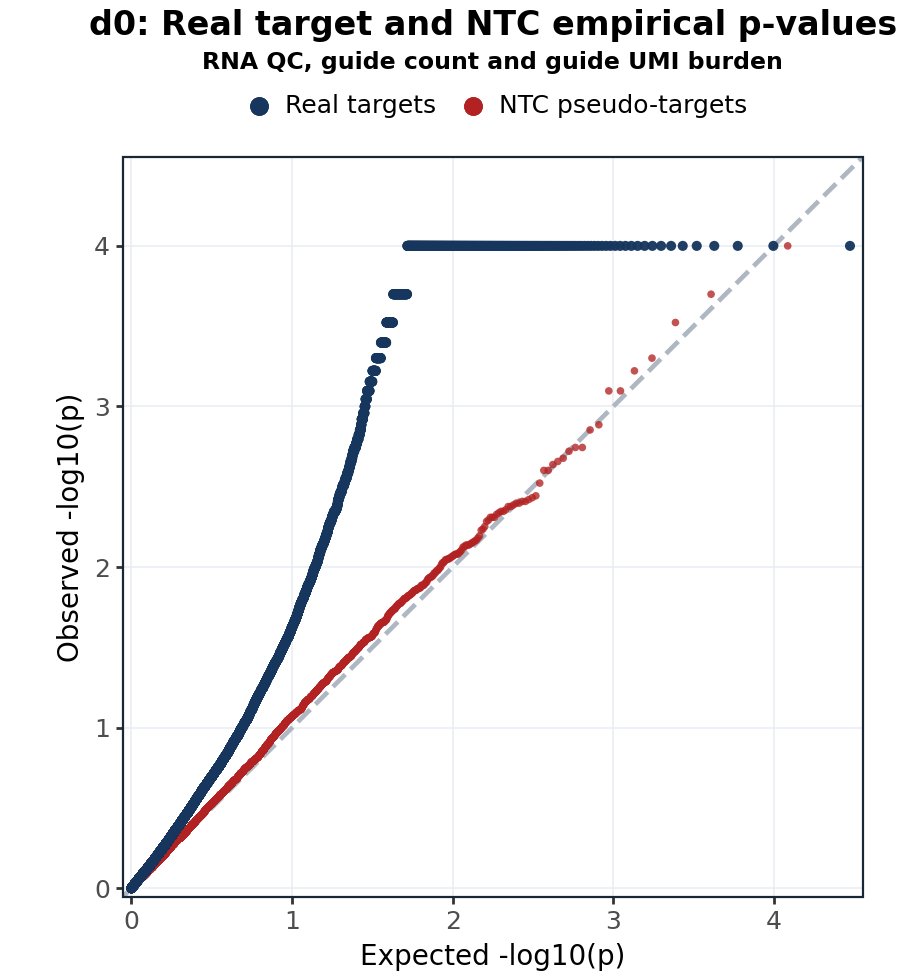

/tmp/ipykernel_3118/622847858.py:58: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


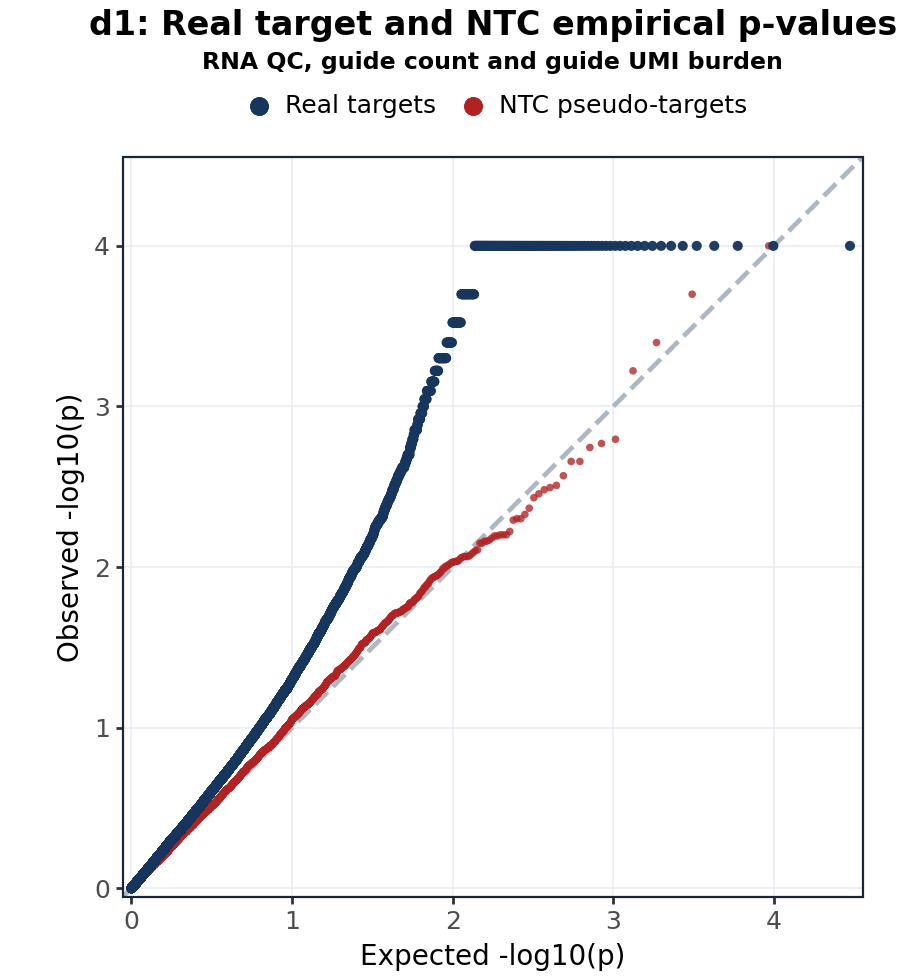

/tmp/ipykernel_3118/622847858.py:58: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


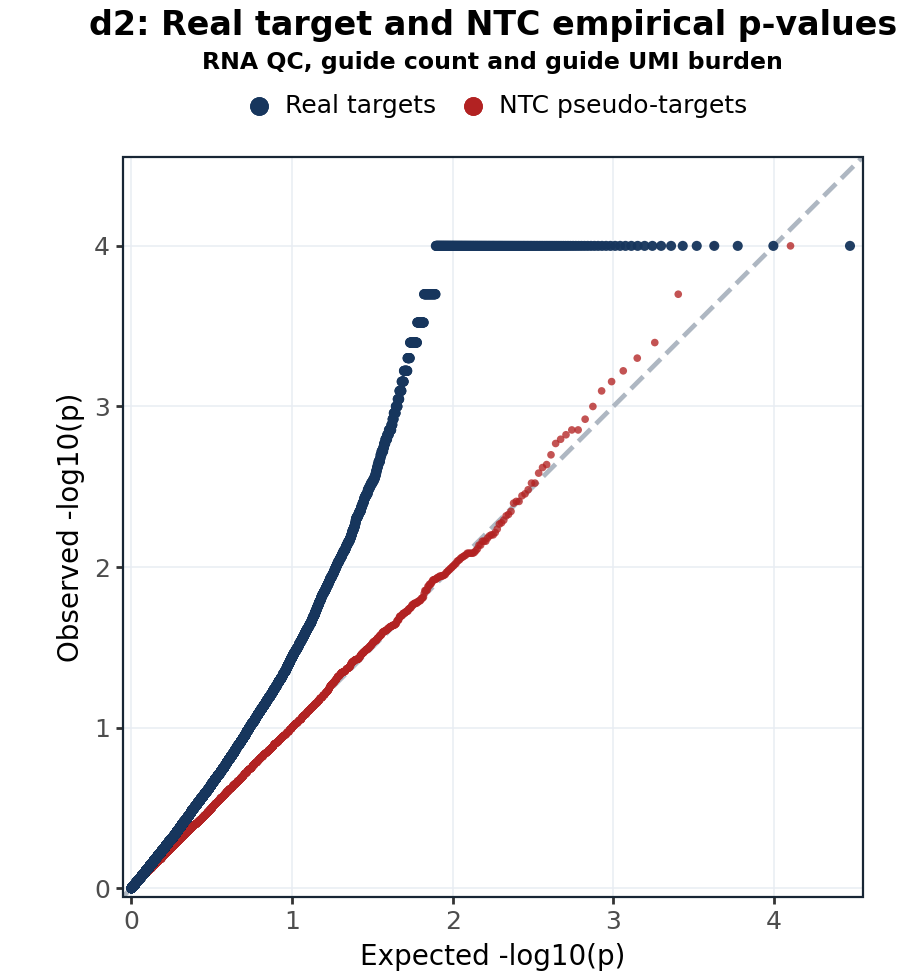

/tmp/ipykernel_3118/622847858.py:58: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


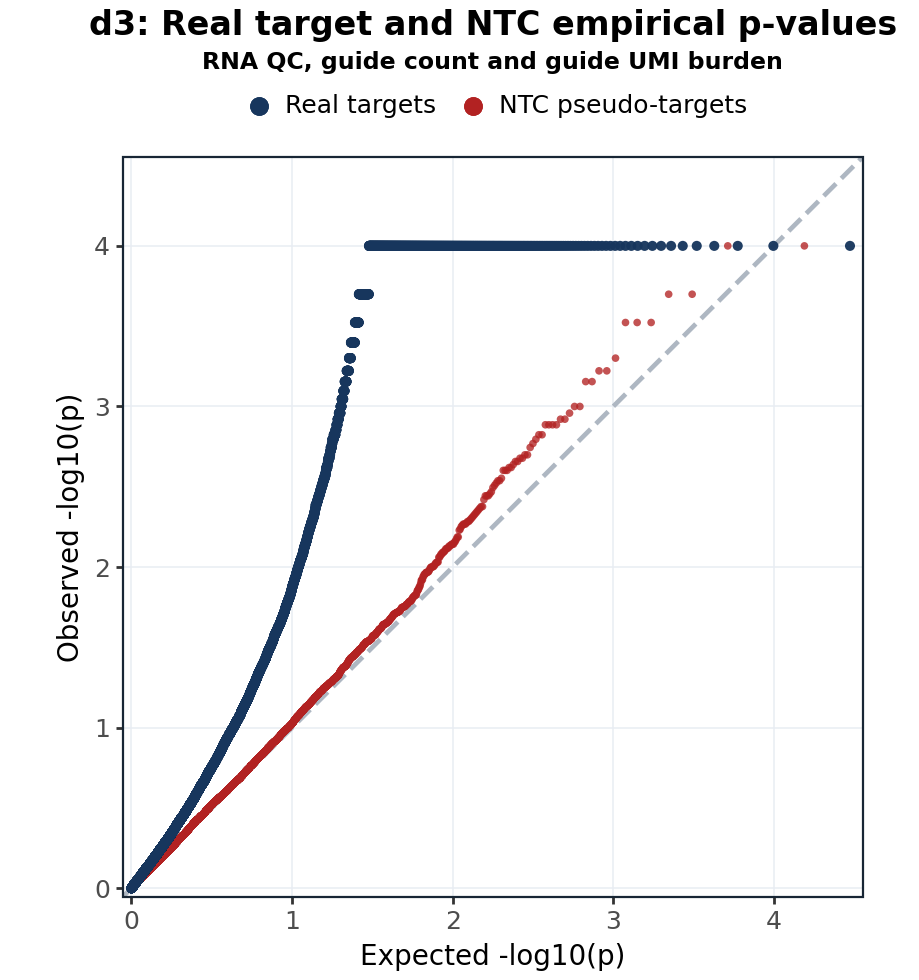

Saved files:

d0
  PDF: results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/illustrator_editable_full_covariates/d0_QQ_full_covariates.pdf
  SVG: results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/illustrator_editable_full_covariates/d0_QQ_full_covariates.svg
  EPS: results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/illustrator_editable_full_covariates/d0_QQ_full_covariates.eps
  PNG: results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/illustrator_editable_full_covariates/d0_QQ_full_covariates.png

d1
  PDF: results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/illustrator_editable_full_covariates/d1_QQ_full_covariates.pdf
  SVG: results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/illustrator_editable_full_covariates/d1_QQ_full_covariates.svg
  EPS: results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/illustrator_editable_full_covariates/d1_QQ_full_covariates.eps
  PNG: results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/illustrator_editable_full_covariates/d1_QQ

In [8]:
qq_csv = MODEL_ROOT / "all_days_QQ_points.csv"
illustrator_out_dir = MODEL_ROOT / "illustrator_editable_full_covariates"

all_saved_files = {}

for day in DAYS:
    p, saved = plot_ipsc_ec_qq(
        qq_csv,
        day=day,
        pvalue_type="empirical",
        title=f"{day}: Real target and NTC empirical p-values",
        subtitle="RNA QC, guide count and guide UMI burden",
        output_stem=illustrator_out_dir / f"{day}_QQ_full_covariates",
        formats=("pdf", "svg", "eps", "png"),
    )
    all_saved_files[day] = saved
    display(p)

print("Saved files:")
for day, files in all_saved_files.items():
    print(f"\n{day}")
    for fmt, path in files.items():
        print(f"  {fmt.upper()}: {path}")


## Biological replicate correlation of DE program effects

This section uses **beta effect sizes**, not p-values. It reruns `run_all_genes_union_crt(...)` within each `biological_sample`, saves one wide beta matrix per biological replicate, and then compares beta estimates for matched `target_name × program_name` pairs between biological samples from the same day.

Within a single biological sample, `biological_sample` is constant, so the backend drops that dummy covariate automatically. The remaining covariates are still used: `pct_counts_mt`, `log1p_total_counts`, `log1p_guides_per_cell`, `log1p_guide_umi_counts`, and `log1p_n_genes_by_counts`.


In [9]:
from pathlib import Path
import importlib

import muon as mu
import pandas as pd
from IPython.display import display

import iPSC_EC_QQ_export_all_days as qqb
qqb = importlib.reload(qqb)

# Preview the biological samples available for each day before launching the replicate-level CRT.
preview_rows = []

for day in DAYS:
    h5mu_path = qqb.h5mu_path_for_day(Path(DATA_DIR), day)
    mdata = mu.read(h5mu_path)

    gex_modality = qqb.resolve_modality(
        mdata,
        None,
        ["GEX", "gex", "rna", "RNA"],
        "GEX/RNA",
    )
    adata_preview = mdata[gex_modality]

    if "biological_sample" not in adata_preview.obs:
        raise KeyError(f"{day}: adata.obs does not contain 'biological_sample'.")

    counts = adata_preview.obs["biological_sample"].astype(str).value_counts().sort_index()
    for biological_sample, n_cells in counts.items():
        preview_rows.append({
            "day": day,
            "biological_sample": biological_sample,
            "n_cells": int(n_cells),
        })

replicate_preview = pd.DataFrame(preview_rows)
display(replicate_preview)


/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/lib/python3.11/site-packages/muon/_core/preproc.py:31: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/lib/python3.11/site-packages/mudata/_core/mudata.py:1598: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/lib/python3.11/site-packages/mudata/_core/mudata.py:1461: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibil

,day,biological_sample,n_cells
0,d0,d0_rep1,17488
1,d0,d0_rep2,21121
2,d1,d1_rep1,5856
3,d1,d1_rep2,11069
4,d2,d2_rep1,10895
5,d2,d2_rep2,11085
6,d3,d3_rep1,21377
7,d3,d3_rep2,22725


### Run replicate-specific CRT beta effects

`B_REP` is set low because this section only uses `betas_df`. Increase it only if you also want final replicate-level permutation p-values. Set `SKIP_EXISTING_REP_BETAS=False` if you want to force regeneration of already-written beta matrices.


In [16]:
import shutil

shutil.rmtree(
    MODEL_ROOT / "biological_replicate_effects" / "betas_by_replicate",
    ignore_errors=True,
)

In [17]:
from pathlib import Path
from types import SimpleNamespace
import gc
import importlib
import json
import time

import muon as mu
import numpy as np
import pandas as pd
from IPython.display import display

import iPSC_EC_QQ_export_all_days as qqb
qqb = importlib.reload(qqb)

# For the replicate-correlation plot, beta estimates are the relevant output.
# Keep B_REP small for a QC run; use a larger value only if you also need replicate p-values.
B_REP = 127
MIN_CELLS_PER_REPLICATE = 200
SKIP_EXISTING_REP_BETAS = False

# Output paths.
density_token = qqb.normalize_density_token(DENSITY_THRESHOLD)
MODEL_ROOT = Path(OUT_DIR) / qqb.model_tag(K, density_token)
REPL_ROOT = MODEL_ROOT / "biological_replicate_effects"
REPL_BETA_DIR = REPL_ROOT / "betas_by_replicate"
REPL_BETA_DIR.mkdir(parents=True, exist_ok=True)

programde = qqb.load_programde(PROGRAMDE_ROOT)

args_for_helpers = SimpleNamespace(
    cnmf_file=None,
    usage_file_template=None,
    cnmf_dir=CNMF_DIR,
    k=K,
    gex_modality=None,
    guide_modality=None,
    ntc_label=NTC_LABELS,
    guide_metadata_tsv=GUIDE_METADATA_TSV,
    guide_metadata_guide_col=None,
    guide_metadata_target_col=None,
    require_covariates=True,
)

replicate_rows = []

for day in DAYS:
    print(f"\n=== {day}: loading full day object ===")

    h5mu_path = qqb.h5mu_path_for_day(Path(DATA_DIR), day)
    guide_csv = qqb.guide_long_path_for_day(GUIDE_LONG_TEMPLATE, day)

    mdata = mu.read(h5mu_path)

    gex_modality = qqb.resolve_modality(
        mdata,
        args_for_helpers.gex_modality,
        ["GEX", "gex", "rna", "RNA"],
        "GEX/RNA",
    )
    guide_modality = qqb.resolve_modality(
        mdata,
        args_for_helpers.guide_modality,
        ["guide", "Guide", "gRNA", "grna"],
        "guide",
    )

    adata = mdata[gex_modality].copy()

    usage_candidates = qqb.usage_candidates_from_args(
        args_for_helpers,
        day,
        density_token,
    )
    usage_path, matched_usage_cells = qqb.choose_usage_file(
        usage_candidates,
        pd.Index(adata.obs_names),
        day,
    )

    qqb.load_and_attach_usage(adata, usage_path)

    guide_names, guide2gene = qqb.load_and_attach_guides(
        adata,
        mdata,
        guide_modality,
        guide_csv,
        NTC_LABELS,
        args_for_helpers.guide_metadata_tsv,
        args_for_helpers.guide_metadata_guide_col,
        args_for_helpers.guide_metadata_target_col,
    )

    if "biological_sample" not in adata.obs:
        raise KeyError(f"{day}: adata.obs does not contain 'biological_sample'.")

    biological_samples = sorted(adata.obs["biological_sample"].astype(str).unique())
    print(f"{day}: biological samples = {biological_samples}")

    for biological_sample in biological_samples:
        sample_safe = qqb.safe_name(biological_sample)
        day_rep_dir = REPL_BETA_DIR / day
        day_rep_dir.mkdir(parents=True, exist_ok=True)

        beta_path = day_rep_dir / f"{day}__{sample_safe}__target_betas_wide.tsv"
        meta_path = day_rep_dir / f"{day}__{sample_safe}__run_metadata.json"

        if SKIP_EXISTING_REP_BETAS and beta_path.exists():
            print(f"  {day} / {biological_sample}: using existing {beta_path}")
            replicate_rows.append({
                "day": day,
                "biological_sample": biological_sample,
                "status": "existing",
                "n_cells": None,
                "beta_path": str(beta_path),
                "metadata_path": str(meta_path),
            })
            continue

        mask = adata.obs["biological_sample"].astype(str).eq(biological_sample).to_numpy()
        n_cells = int(mask.sum())

        if n_cells < MIN_CELLS_PER_REPLICATE:
            print(f"  {day} / {biological_sample}: skipped, only {n_cells:,} cells")
            replicate_rows.append({
                "day": day,
                "biological_sample": biological_sample,
                "status": "skipped_too_few_cells",
                "n_cells": n_cells,
                "beta_path": None,
                "metadata_path": None,
            })
            continue

        print(f"  {day} / {biological_sample}: running CRT on {n_cells:,} cells")

        adata_rep = adata[mask].copy()

        # biological_sample is constant within this subset and will be dropped by attach_covariates().
        covariates = qqb.attach_covariates(
            adata_rep,
            require_covariates=True,
        )

        inputs = qqb.prepare_inputs(programde, adata_rep)

        t0 = time.time()
        out = programde.run_all_genes_union_crt(
            inputs=inputs,
            B=B_REP,
            n_jobs=N_JOBS,
            calibrate_skew_normal=True,
            return_raw_pvals=True,
            return_skew_normal=True,
        )

        betas = out.get("betas_df")
        if betas is None:
            raise RuntimeError(f"{day} / {biological_sample}: no betas_df returned.")

        qqb.save_wide_frame(betas, beta_path)

        meta = {
            "day": day,
            "biological_sample": biological_sample,
            "n_cells": n_cells,
            "B_REP": B_REP,
            "usage_path": str(usage_path),
            "matched_usage_cells": int(matched_usage_cells),
            "h5mu_path": str(h5mu_path),
            "guide_csv": str(guide_csv),
            "n_guides": int(len(guide_names)),
            "n_targets": int(betas.shape[0]),
            "n_programs": int(betas.shape[1]),
            "covariate_columns": list(covariates.columns),
            "covariate_sources": adata_rep.uns.get("covariate_sources", {}),
            "runtime_seconds": round(time.time() - t0, 2),
            "beta_path": str(beta_path),
        }
        meta_path.write_text(json.dumps(meta, indent=2))

        replicate_rows.append({
            "day": day,
            "biological_sample": biological_sample,
            "status": "written",
            "n_cells": n_cells,
            "beta_path": str(beta_path),
            "metadata_path": str(meta_path),
        })

        del adata_rep, inputs, out, betas
        gc.collect()

    del mdata, adata
    gc.collect()

replicate_manifest = pd.DataFrame(replicate_rows)
replicate_manifest_path = REPL_ROOT / "replicate_beta_manifest.csv"
replicate_manifest.to_csv(replicate_manifest_path, index=False)

print("\nSaved manifest:", replicate_manifest_path)
display(replicate_manifest)



=== d0: loading full day object ===


/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/lib/python3.11/site-packages/mudata/_core/mudata.py:1598: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/lib/python3.11/site-packages/mudata/_core/mudata.py:1461: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.


usage candidates scored for d0
  overlap=38,609  /oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all.usages.k_50.dt_0_2.consensus.txt
  overlap=0  /oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all.starcat_spectra.k_50.dt_0_2.txt
  overlap=0  /oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all.spectra.k_50.dt_0_2.consensus.txt
  overlap=0  /oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/012726_100k_cells_20iter_allHVG_to

/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/iPSC_EC_QQ_full_covariates_with_replicate_correlation_bundle/iPSC_EC_QQ_export_all_days.py:306: UserWarning: Guide metadata file 300genes_guide_metadata_v43.tsv was not found. Falling back to guide_name.split('_', 1)[0].


d0: biological samples = ['d0_rep1', 'd0_rep2']
  d0 / d0_rep1: running CRT on 17,488 cells


...

/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/iPSC_EC_QQ_full_covariates_with_replicate_correlation_bundle/iPSC_EC_QQ_export_all_days.py:587: UserWarning: Categorical covariate 'biological_sample' has only one level in this day; no dummy columns will be added.


  d3 / d3_rep2: running CRT on 22,725 cells


/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/iPSC_EC_QQ_full_covariates_with_replicate_correlation_bundle/iPSC_EC_QQ_export_all_days.py:587: UserWarning: Categorical covariate 'biological_sample' has only one level in this day; no dummy columns will be added.



Saved manifest: results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/biological_replicate_effects/replicate_beta_manifest.csv


,day,biological_sample,status,n_cells,beta_path,metadata_path
0,d0,d0_rep1,written,17488,results/ipsc_ec_qq_exports_full_covariates/k_5...,results/ipsc_ec_qq_exports_full_covariates/k_5...
1,d0,d0_rep2,written,21121,results/ipsc_ec_qq_exports_full_covariates/k_5...,results/ipsc_ec_qq_exports_full_covariates/k_5...
2,d1,d1_rep1,written,5856,results/ipsc_ec_qq_exports_full_covariates/k_5...,results/ipsc_ec_qq_exports_full_covariates/k_5...
3,d1,d1_rep2,written,11069,results/ipsc_ec_qq_exports_full_covariates/k_5...,results/ipsc_ec_qq_exports_full_covariates/k_5...
4,d2,d2_rep1,written,10895,results/ipsc_ec_qq_exports_full_covariates/k_5...,results/ipsc_ec_qq_exports_full_covariates/k_5...
5,d2,d2_rep2,written,11085,results/ipsc_ec_qq_exports_full_covariates/k_5...,results/ipsc_ec_qq_exports_full_covariates/k_5...
6,d3,d3_rep1,written,21377,results/ipsc_ec_qq_exports_full_covariates/k_5...,results/ipsc_ec_qq_exports_full_covariates/k_5...
7,d3,d3_rep2,written,22725,results/ipsc_ec_qq_exports_full_covariates/k_5...,results/ipsc_ec_qq_exports_full_covariates/k_5...


### Plot biological replicate correlation scatterplots

This cell reads the per-replicate beta matrices, joins matched `target_name × program_name` effects between biological samples from the same day, computes Pearson and Spearman correlations, and saves Illustrator-editable vector files.

Outputs are written under:

```text
results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/biological_replicate_effects/plots/
```


,day,replicate_pair,n_target_program_pairs,pearson_r,spearman_r,facet_label
0,d0,d0_rep1 vs d0_rep2,14900,0.378138,0.256223,d0: d0_rep1 vs d0_rep2\nPearson r=0.38; Spearm...
1,d1,d1_rep1 vs d1_rep2,14900,0.223567,0.161376,d1: d1_rep1 vs d1_rep2\nPearson r=0.22; Spearm...
2,d2,d2_rep1 vs d2_rep2,14900,0.331152,0.197776,d2: d2_rep1 vs d2_rep2\nPearson r=0.33; Spearm...
3,d3,d3_rep1 vs d3_rep2,14900,0.578932,0.355881,d3: d3_rep1 vs d3_rep2\nPearson r=0.58; Spearm...


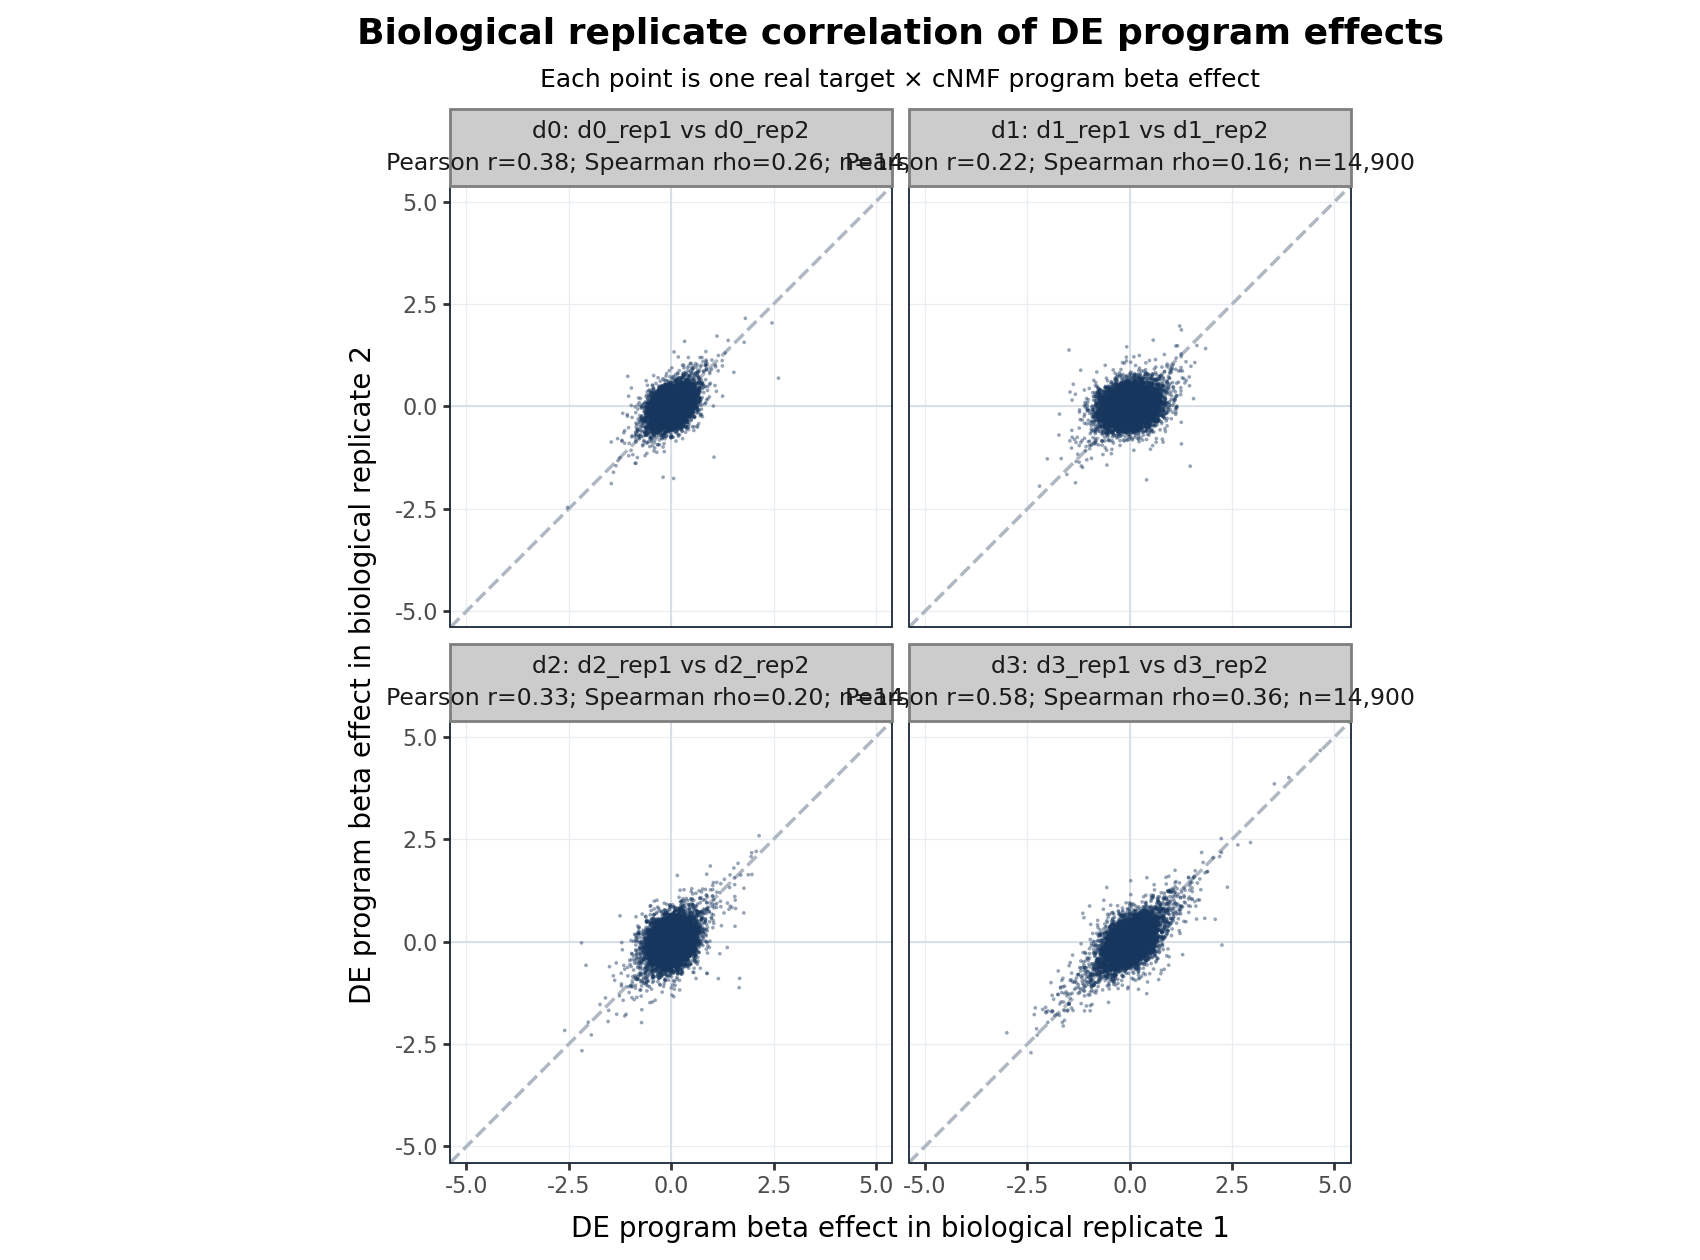

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


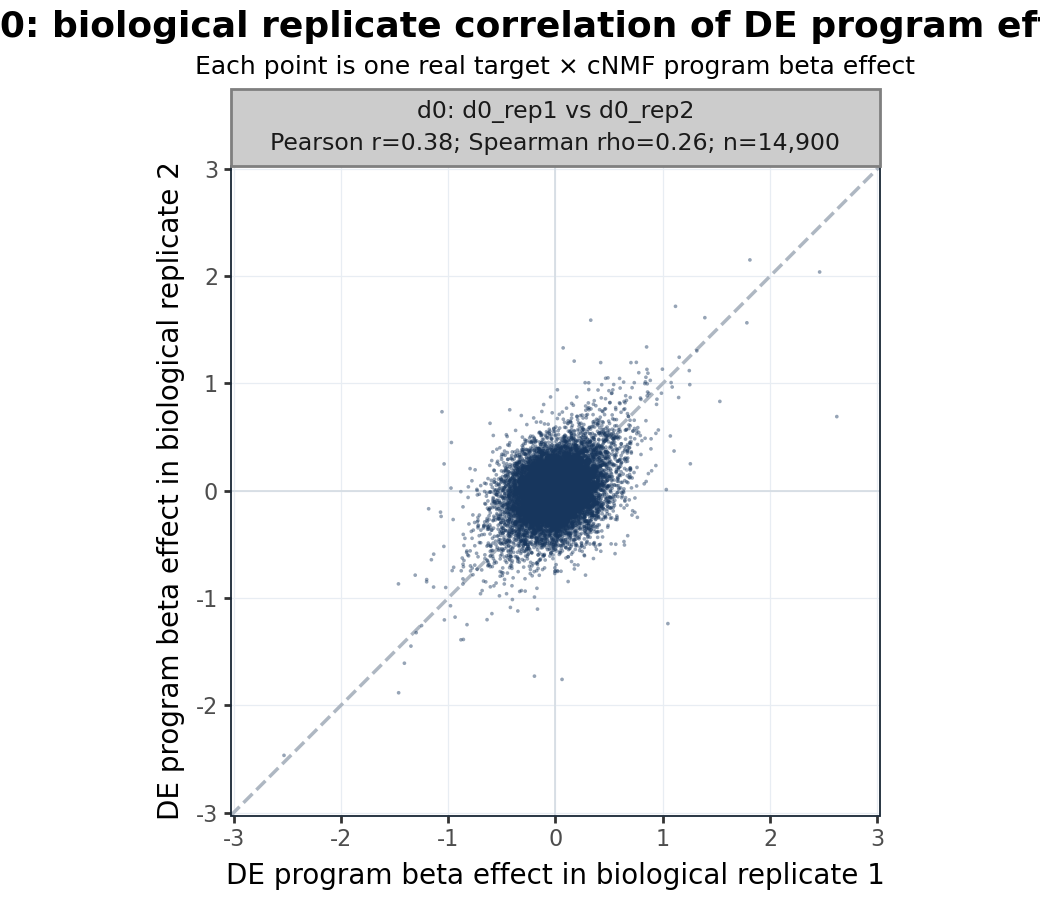

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


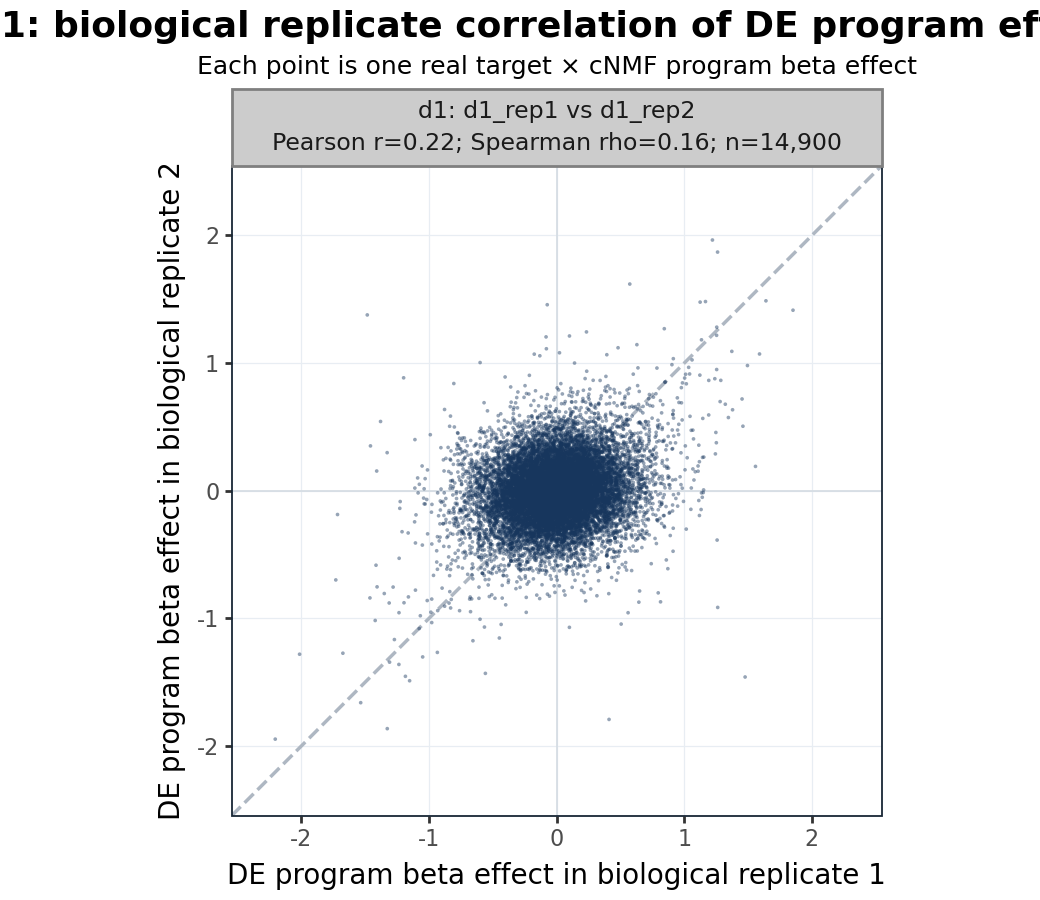

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


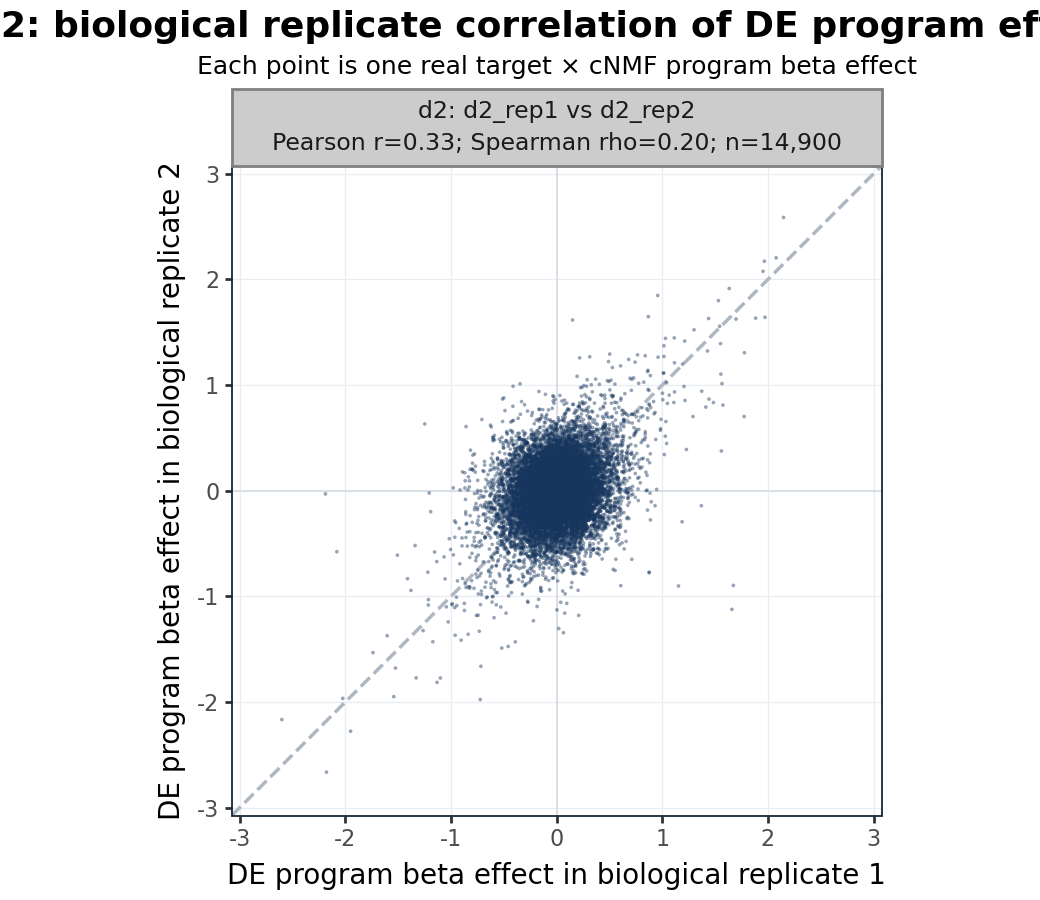

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


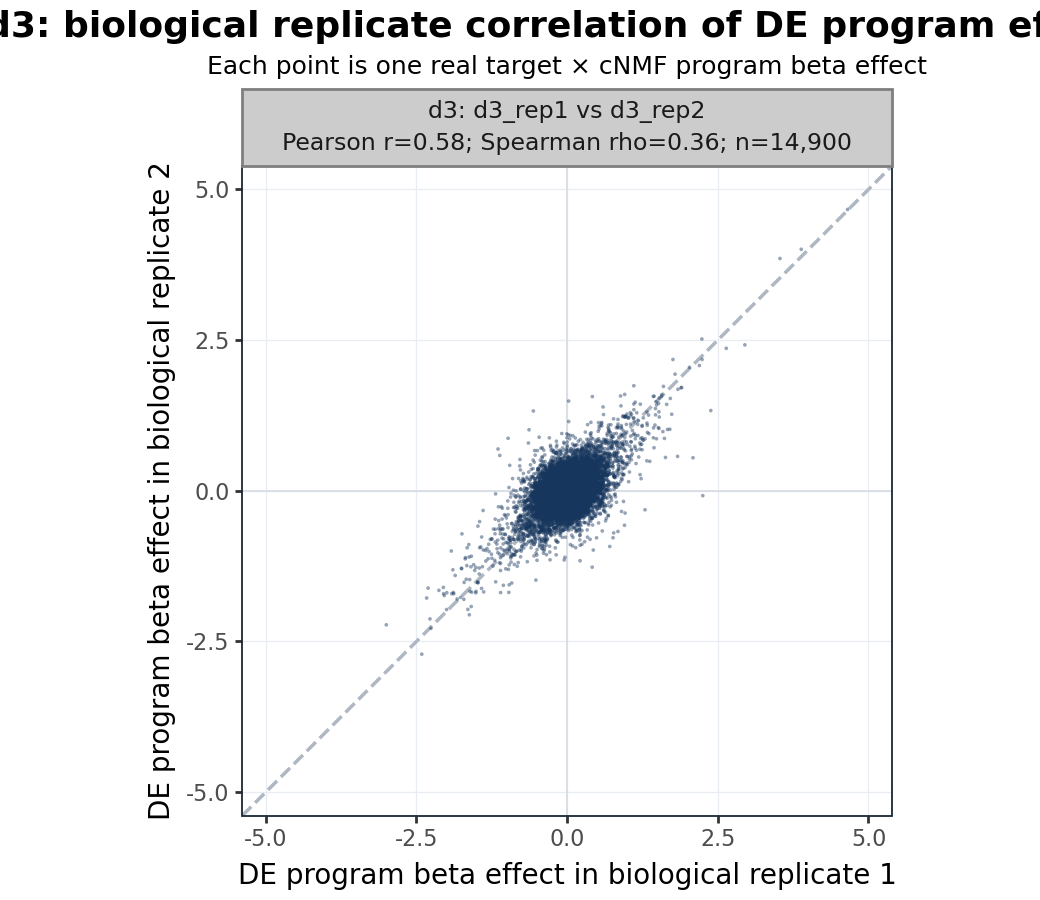

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


Saved data tables:
   results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/biological_replicate_effects/plots/biological_replicate_DE_program_effect_correlation_summary.csv
   results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/biological_replicate_effects/plots/biological_replicate_DE_program_effect_pairs.csv

Saved combined plot files:
  PDF: results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/biological_replicate_effects/plots/biological_replicate_DE_program_effect_correlation_all_days.pdf
  SVG: results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/biological_replicate_effects/plots/biological_replicate_DE_program_effect_correlation_all_days.svg
  EPS: results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/biological_replicate_effects/plots/biological_replicate_DE_program_effect_correlation_all_days.eps
  PNG: results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/biological_replicate_effects/plots/biological_replicate_DE_program_effect_correlation_all_days.png

Saved per-

In [18]:
from pathlib import Path
import itertools

import matplotlib as mpl
import numpy as np
import pandas as pd
from IPython.display import display
from plotnine import (
    ggplot, aes,
    geom_abline, geom_hline, geom_vline, geom_point,
    facet_wrap,
    scale_x_continuous, scale_y_continuous,
    coord_equal,
    labs,
    theme_bw, theme,
    element_text, element_line, element_rect, element_blank,
)

# Keep text editable in Illustrator vector exports.
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42
mpl.rcParams["svg.fonttype"] = "none"

REPL_ROOT = MODEL_ROOT / "biological_replicate_effects"
REPL_BETA_DIR = REPL_ROOT / "betas_by_replicate"
PLOT_OUT_DIR = REPL_ROOT / "plots"
PLOT_OUT_DIR.mkdir(parents=True, exist_ok=True)

NTC_KEY_SET = {str(x).strip().lower() for x in NTC_LABELS}


def read_beta_wide_as_long(beta_path, *, day, biological_sample):
    beta_wide = pd.read_csv(beta_path, sep="\t", index_col=0)
    beta_wide.index = beta_wide.index.astype(str)
    beta_wide.columns = beta_wide.columns.astype(str)
    beta_wide.index.name = "target_name"

    beta_long = (
        beta_wide
        .reset_index()
        .melt(
            id_vars="target_name",
            var_name="program_name",
            value_name="beta",
        )
    )

    beta_long["day"] = day
    beta_long["biological_sample"] = biological_sample
    beta_long["beta"] = pd.to_numeric(beta_long["beta"], errors="coerce")
    return beta_long


def format_correlation(value):
    if value is None or not np.isfinite(value):
        return "NA"
    return f"{value:.2f}"


def save_plotnine_formats(
    p,
    output_stem,
    *,
    width,
    height,
    dpi=300,
    formats=("pdf", "svg", "eps", "png"),
):
    output_stem = Path(output_stem)
    output_stem.parent.mkdir(parents=True, exist_ok=True)

    saved = {}
    for fmt in formats:
        out = output_stem.with_suffix(f".{fmt}")
        kwargs = dict(width=width, height=height, units="in", verbose=False)
        if fmt.lower() == "png":
            kwargs["dpi"] = dpi
        try:
            p.save(out, **kwargs)
            saved[fmt] = out
        except Exception as exc:
            print(f"Could not save {fmt.upper()} for {output_stem.name}: {exc}")
    return saved


def build_effect_pair_table(manifest):
    pair_frames = []

    for day, day_manifest in manifest.groupby("day", sort=False):
        records = day_manifest.to_dict("records")

        if len(records) < 2:
            print(f"{day}: fewer than 2 biological samples with beta files; skipping.")
            continue

        for rec_a, rec_b in itertools.combinations(records, 2):
            sample_a = str(rec_a["biological_sample"])
            sample_b = str(rec_b["biological_sample"])

            beta_a = read_beta_wide_as_long(
                rec_a["beta_path"],
                day=day,
                biological_sample=sample_a,
            ).rename(columns={"beta": "beta_x"})

            beta_b = read_beta_wide_as_long(
                rec_b["beta_path"],
                day=day,
                biological_sample=sample_b,
            ).rename(columns={"beta": "beta_y"})

            merged = beta_a[["target_name", "program_name", "beta_x"]].merge(
                beta_b[["target_name", "program_name", "beta_y"]],
                on=["target_name", "program_name"],
                how="inner",
            )

            # Remove NTC target rows; these are not real target effects.
            merged = merged[
                ~merged["target_name"].astype(str).str.strip().str.lower().isin(NTC_KEY_SET)
            ].copy()

            merged = merged[
                np.isfinite(merged["beta_x"])
                & np.isfinite(merged["beta_y"])
            ].copy()

            if merged.empty:
                print(f"{day}: {sample_a} vs {sample_b} produced no matched finite beta pairs.")
                continue

            merged["day"] = day
            merged["replicate_x"] = sample_a
            merged["replicate_y"] = sample_b
            merged["replicate_pair"] = f"{sample_a} vs {sample_b}"
            pair_frames.append(merged)

    if not pair_frames:
        raise ValueError("No replicate pairs available for plotting.")

    return pd.concat(pair_frames, ignore_index=True, sort=False)


def summarize_effect_pairs(effects):
    summary_rows = []
    for (day, pair), group in effects.groupby(["day", "replicate_pair"], sort=False):
        pearson_r = group["beta_x"].corr(group["beta_y"], method="pearson")
        spearman_r = group["beta_x"].corr(group["beta_y"], method="spearman")

        summary_rows.append({
            "day": day,
            "replicate_pair": pair,
            "n_target_program_pairs": int(len(group)),
            "pearson_r": pearson_r,
            "spearman_r": spearman_r,
        })

    summary = pd.DataFrame(summary_rows)
    summary["facet_label"] = summary.apply(
        lambda r: (
            f"{r['day']}: {r['replicate_pair']}\n"
            f"Pearson r={format_correlation(r['pearson_r'])}; "
            f"Spearman rho={format_correlation(r['spearman_r'])}; "
            f"n={int(r['n_target_program_pairs']):,}"
        ),
        axis=1,
    )
    return summary


def plot_effect_correlation(plot_df, *, title, subtitle, ncol=2):
    axis_limit = float(
        np.nanmax(np.abs(plot_df[["beta_x", "beta_y"]].to_numpy(dtype=float)))
    )
    axis_limit = axis_limit * 1.05 if axis_limit > 0 else 1.0

    n_facets = int(plot_df["facet_label"].nunique())
    height = max(4.5, 3.15 * np.ceil(n_facets / ncol))
    width = 8.5 if ncol == 2 else 5.2

    p = (
        ggplot(plot_df, aes("beta_x", "beta_y"))
        + geom_hline(yintercept=0, color="#D5DCE3", size=0.35)
        + geom_vline(xintercept=0, color="#D5DCE3", size=0.35)
        + geom_abline(
            intercept=0,
            slope=1,
            linetype="dashed",
            color="#AEB7C2",
            size=0.7,
        )
        + geom_point(
            size=0.75,
            alpha=0.45,
            color="#17365D",
            stroke=0,
        )
        + facet_wrap("~facet_label", ncol=ncol)
        + scale_x_continuous(limits=(-axis_limit, axis_limit))
        + scale_y_continuous(limits=(-axis_limit, axis_limit))
        + coord_equal()
        + labs(
            title=title,
            subtitle=subtitle,
            x="DE program beta effect in biological replicate 1",
            y="DE program beta effect in biological replicate 2",
        )
        + theme_bw(base_size=10)
        + theme(
            figure_size=(width, height),
            plot_title=element_text(size=13, weight="bold", ha="center"),
            plot_subtitle=element_text(size=9, ha="center"),
            strip_text=element_text(size=8.5),
            axis_title=element_text(size=10),
            axis_text=element_text(size=8),
            panel_grid_major=element_line(color="#E8EDF3", size=0.45),
            panel_grid_minor=element_blank(),
            panel_border=element_rect(color="#182635", size=0.65),
        )
    )
    return p, width, float(height)


manifest_path = REPL_ROOT / "replicate_beta_manifest.csv"
manifest = pd.read_csv(manifest_path)
manifest = manifest[
    manifest["status"].isin(["written", "existing"])
    & manifest["beta_path"].notna()
].copy()

if manifest.empty:
    raise ValueError(f"No usable beta files listed in {manifest_path}.")

# Build and save the matched effect table.
effects = build_effect_pair_table(manifest)
summary = summarize_effect_pairs(effects)
effects = effects.merge(
    summary[["day", "replicate_pair", "facet_label"]],
    on=["day", "replicate_pair"],
    how="left",
)

summary_path = PLOT_OUT_DIR / "biological_replicate_DE_program_effect_correlation_summary.csv"
effects_path = PLOT_OUT_DIR / "biological_replicate_DE_program_effect_pairs.csv"
summary.to_csv(summary_path, index=False)
effects.to_csv(effects_path, index=False)

display(summary)

# Combined plot across all days and all replicate pairs.
combined_plot, combined_width, combined_height = plot_effect_correlation(
    effects,
    title="Biological replicate correlation of DE program effects",
    subtitle="Each point is one real target × cNMF program beta effect",
    ncol=2,
)
display(combined_plot)

combined_stem = PLOT_OUT_DIR / "biological_replicate_DE_program_effect_correlation_all_days"
combined_saved = save_plotnine_formats(
    combined_plot,
    combined_stem,
    width=combined_width,
    height=combined_height,
)

# Also save one faceted plot per day.
per_day_saved = {}
for day in DAYS:
    day_effects = effects[effects["day"].astype(str).eq(str(day))].copy()
    if day_effects.empty:
        continue

    n_facets = int(day_effects["facet_label"].nunique())
    ncol = 1 if n_facets == 1 else 2
    day_plot, day_width, day_height = plot_effect_correlation(
        day_effects,
        title=f"{day}: biological replicate correlation of DE program effects",
        subtitle="Each point is one real target × cNMF program beta effect",
        ncol=ncol,
    )
    display(day_plot)

    day_stem = PLOT_OUT_DIR / f"{day}_biological_replicate_DE_program_effect_correlation"
    per_day_saved[day] = save_plotnine_formats(
        day_plot,
        day_stem,
        width=day_width,
        height=day_height,
    )

print("Saved data tables:")
print("  ", summary_path)
print("  ", effects_path)

print("\nSaved combined plot files:")
for fmt, path in combined_saved.items():
    print(f"  {fmt.upper()}: {path}")

print("\nSaved per-day plot files:")
for day, saved in per_day_saved.items():
    print(day)
    for fmt, path in saved.items():
        print(f"  {fmt.upper()}: {path}")


#### Validate results

In [20]:
from pathlib import Path
import json
import hashlib
import datetime as dt
import itertools
import numpy as np
import pandas as pd
from IPython.display import display

MODEL_ROOT = Path("results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2").resolve()
REPL_ROOT = MODEL_ROOT / "biological_replicate_effects"
BETA_DIR = REPL_ROOT / "betas_by_replicate"
PLOT_DIR = REPL_ROOT / "plots"

SUMMARY_CSV = PLOT_DIR / "biological_replicate_DE_program_effect_correlation_summary.csv"
EFFECTS_CSV = PLOT_DIR / "biological_replicate_DE_program_effect_pairs.csv"
MANIFEST_CSV = REPL_ROOT / "replicate_beta_manifest.csv"

NTC_LABELS_FOR_DIAG = ["SAFE", "non-targeting", "NTC"]
NTC_KEY_SET = {str(x).strip().lower() for x in NTC_LABELS_FOR_DIAG}


def mtime_iso(path):
    path = Path(path)
    if not path.exists():
        return None
    return dt.datetime.fromtimestamp(path.stat().st_mtime).isoformat(timespec="seconds")


def sha256_short(path, n_bytes=2_000_000):
    path = Path(path)
    h = hashlib.sha256()
    with path.open("rb") as fh:
        h.update(fh.read(n_bytes))
    return h.hexdigest()[:16]


def file_audit(paths):
    rows = []
    for path in paths:
        path = Path(path)
        rows.append({
            "path": str(path),
            "exists": path.exists(),
            "size_mb": round(path.stat().st_size / 1e6, 3) if path.exists() else np.nan,
            "mtime": mtime_iso(path),
            "sha256_first_2mb": sha256_short(path) if path.exists() and path.is_file() else None,
        })
    return pd.DataFrame(rows)


beta_files = sorted(BETA_DIR.glob("*/*__target_betas_wide.tsv"))
meta_files = sorted(BETA_DIR.glob("*/*__run_metadata.json"))
plot_files = sorted(PLOT_DIR.glob("*biological_replicate_DE_program_effect_correlation*.*"))

audit_paths = [SUMMARY_CSV, EFFECTS_CSV, MANIFEST_CSV] + beta_files + meta_files + plot_files

print("MODEL_ROOT:", MODEL_ROOT)
print("BETA_DIR:", BETA_DIR)
print("PLOT_DIR:", PLOT_DIR)
print(f"Found {len(beta_files)} beta files and {len(meta_files)} metadata files.")

audit = file_audit(audit_paths).sort_values("mtime", na_position="first")
display(audit)

summary = pd.read_csv(SUMMARY_CSV)
effects = pd.read_csv(EFFECTS_CSV)

print("\nSaved summary:")
display(summary)

print("\nSaved effect-pair table:")
print(effects.shape)
display(effects.head())

dup_n = effects.duplicated(
    ["day", "replicate_pair", "target_name", "program_name"]
).sum()
print(f"\nDuplicated day × replicate_pair × target_name × program_name rows: {dup_n:,}")

MODEL_ROOT: /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/iPSC_EC_QQ_full_covariates_with_replicate_correlation_bundle/results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2
BETA_DIR: /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/iPSC_EC_QQ_full_covariates_with_replicate_correlation_bundle/results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/biological_replicate_effects/betas_by_replicate
PLOT_DIR: /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/iPSC_EC_QQ_full_covariates_with_replicate_correlation_bundle/results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/biological_replicate_effects/plots
Found 8 beta files and 8 metadata files.


,path,exists,size_mb,mtime,sha256_first_2mb
3,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,True,0.307,2026-07-06T18:00:31,00121aafb2b631b1
11,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,True,0.002,2026-07-06T18:00:31,f3e67357bde67ad3
4,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,True,0.307,2026-07-06T18:01:16,16ecd21b962a73c0
12,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,True,0.002,2026-07-06T18:01:16,472bfd82f924101a
5,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,True,0.305,2026-07-06T18:02:33,f6318c330b5cc735
13,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,True,0.002,2026-07-06T18:02:33,8f4b2f23035175ff
14,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,True,0.002,2026-07-06T18:03:28,7a5485ed1104834c
6,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,True,0.307,2026-07-06T18:03:28,6147e884ecba5cfc
15,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,True,0.002,2026-07-06T18:04:29,06cd3174180b9b1c
7,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,True,0.306,2026-07-06T18:04:29,04add82e808335f2



Saved summary:


,day,replicate_pair,n_target_program_pairs,pearson_r,spearman_r,facet_label
0,d0,d0_rep1 vs d0_rep2,14900,0.378138,0.256223,d0: d0_rep1 vs d0_rep2\nPearson r=0.38; Spearm...
1,d1,d1_rep1 vs d1_rep2,14900,0.223567,0.161376,d1: d1_rep1 vs d1_rep2\nPearson r=0.22; Spearm...
2,d2,d2_rep1 vs d2_rep2,14900,0.331152,0.197776,d2: d2_rep1 vs d2_rep2\nPearson r=0.33; Spearm...
3,d3,d3_rep1 vs d3_rep2,14900,0.578932,0.355881,d3: d3_rep1 vs d3_rep2\nPearson r=0.58; Spearm...



Saved effect-pair table:
(59600, 9)


,target_name,program_name,beta_x,beta_y,day,replicate_x,replicate_y,replicate_pair,facet_label
0,ACAA1,1,-0.103272,0.024239,d0,d0_rep1,d0_rep2,d0_rep1 vs d0_rep2,d0: d0_rep1 vs d0_rep2\nPearson r=0.38; Spearm...
1,ACTL7B,1,-0.008223,-0.123024,d0,d0_rep1,d0_rep2,d0_rep1 vs d0_rep2,d0: d0_rep1 vs d0_rep2\nPearson r=0.38; Spearm...
2,ACVR1B,1,-0.030110,-0.269059,d0,d0_rep1,d0_rep2,d0_rep1 vs d0_rep2,d0: d0_rep1 vs d0_rep2\nPearson r=0.38; Spearm...
3,ACVR2A,1,-0.248604,0.009282,d0,d0_rep1,d0_rep2,d0_rep1 vs d0_rep2,d0: d0_rep1 vs d0_rep2\nPearson r=0.38; Spearm...
4,ACVR2B,1,0.092070,-0.067528,d0,d0_rep1,d0_rep2,d0_rep1 vs d0_rep2,d0: d0_rep1 vs d0_rep2\nPearson r=0.38; Spearm...



Duplicated day × replicate_pair × target_name × program_name rows: 0


In [21]:
required_replicate_covariates = {
    "pct_counts_mt",
    "log1p_total_counts",
    "log1p_guides_per_cell",
    "log1p_guide_umi_counts",
    "log1p_n_genes_by_counts",
}

manifest = pd.read_csv(MANIFEST_CSV) if MANIFEST_CSV.exists() else pd.DataFrame()
print("Replicate beta manifest:")
display(manifest)

if not manifest.empty and "status" in manifest.columns:
    print("\nManifest status counts:")
    display(manifest["status"].value_counts(dropna=False).rename_axis("status").reset_index(name="n"))

    if manifest["status"].astype(str).eq("existing").any():
        print(
            "\nWARNING: At least one replicate beta file was marked 'existing'. "
            "That means the notebook reused a previous beta file for that replicate."
        )

metadata_rows = []

for meta_path in meta_files:
    meta = json.loads(meta_path.read_text())

    covariates = list(meta.get("covariate_columns", []))
    beta_path = Path(meta.get("beta_path", ""))
    if not beta_path.exists():
        guessed = meta_path.with_name(meta_path.name.replace("__run_metadata.json", "__target_betas_wide.tsv"))
        beta_path = guessed if guessed.exists() else beta_path

    bio_covariates = [c for c in covariates if "biological_sample" in c]
    missing_required = sorted(required_replicate_covariates.difference(covariates))

    metadata_rows.append({
        "day": meta.get("day"),
        "biological_sample": meta.get("biological_sample"),
        "n_cells": meta.get("n_cells"),
        "B_REP": meta.get("B_REP"),
        "runtime_seconds": meta.get("runtime_seconds"),
        "n_covariates": len(covariates),
        "covariate_columns": ", ".join(covariates),
        "missing_required_replicate_covariates": ", ".join(missing_required),
        "n_biological_sample_covariates": len(bio_covariates),
        "biological_sample_covariates": ", ".join(bio_covariates),
        "metadata_path": str(meta_path),
        "metadata_mtime": mtime_iso(meta_path),
        "beta_path": str(beta_path),
        "beta_exists": beta_path.exists(),
        "beta_mtime": mtime_iso(beta_path) if beta_path.exists() else None,
        "beta_sha256_first_2mb": sha256_short(beta_path) if beta_path.exists() else None,
    })

metadata_df = pd.DataFrame(metadata_rows).sort_values(["day", "biological_sample"])
display(metadata_df)

bad_bio = metadata_df[metadata_df["n_biological_sample_covariates"] > 0]
bad_missing = metadata_df[metadata_df["missing_required_replicate_covariates"].astype(str).ne("")]

if bad_bio.empty:
    print("\nOK: biological_sample is not included as a covariate inside replicate-specific runs.")
else:
    print("\nWARNING: biological_sample appears in replicate-specific covariates:")
    display(bad_bio[["day", "biological_sample", "biological_sample_covariates"]])

if bad_missing.empty:
    print("OK: expected replicate covariates are present.")
else:
    print("\nWARNING: some expected replicate covariates are missing:")
    display(bad_missing[["day", "biological_sample", "missing_required_replicate_covariates", "covariate_columns"]])

Replicate beta manifest:


,day,biological_sample,status,n_cells,beta_path,metadata_path
0,d0,d0_rep1,written,17488,results/ipsc_ec_qq_exports_full_covariates/k_5...,results/ipsc_ec_qq_exports_full_covariates/k_5...
1,d0,d0_rep2,written,21121,results/ipsc_ec_qq_exports_full_covariates/k_5...,results/ipsc_ec_qq_exports_full_covariates/k_5...
2,d1,d1_rep1,written,5856,results/ipsc_ec_qq_exports_full_covariates/k_5...,results/ipsc_ec_qq_exports_full_covariates/k_5...
3,d1,d1_rep2,written,11069,results/ipsc_ec_qq_exports_full_covariates/k_5...,results/ipsc_ec_qq_exports_full_covariates/k_5...
4,d2,d2_rep1,written,10895,results/ipsc_ec_qq_exports_full_covariates/k_5...,results/ipsc_ec_qq_exports_full_covariates/k_5...
5,d2,d2_rep2,written,11085,results/ipsc_ec_qq_exports_full_covariates/k_5...,results/ipsc_ec_qq_exports_full_covariates/k_5...
6,d3,d3_rep1,written,21377,results/ipsc_ec_qq_exports_full_covariates/k_5...,results/ipsc_ec_qq_exports_full_covariates/k_5...
7,d3,d3_rep2,written,22725,results/ipsc_ec_qq_exports_full_covariates/k_5...,results/ipsc_ec_qq_exports_full_covariates/k_5...



Manifest status counts:


,status,n
0,written,8


,day,biological_sample,n_cells,B_REP,runtime_seconds,n_covariates,covariate_columns,missing_required_replicate_covariates,n_biological_sample_covariates,biological_sample_covariates,metadata_path,metadata_mtime,beta_path,beta_exists,beta_mtime,beta_sha256_first_2mb
0,d0,d0_rep1,17488,127,49.81,5,"pct_counts_mt, log1p_total_counts, log1p_guide...",,0,,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,2026-07-06T18:00:31,results/ipsc_ec_qq_exports_full_covariates/k_5...,True,2026-07-06T18:00:31,00121aafb2b631b1
1,d0,d0_rep2,21121,127,41.37,5,"pct_counts_mt, log1p_total_counts, log1p_guide...",,0,,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,2026-07-06T18:01:16,results/ipsc_ec_qq_exports_full_covariates/k_5...,True,2026-07-06T18:01:16,16ecd21b962a73c0
2,d1,d1_rep1,5856,127,51.97,5,"pct_counts_mt, log1p_total_counts, log1p_guide...",,0,,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,2026-07-06T18:02:33,results/ipsc_ec_qq_exports_full_covariates/k_5...,True,2026-07-06T18:02:33,f6318c330b5cc735
3,d1,d1_rep2,11069,127,51.94,5,"pct_counts_mt, log1p_total_counts, log1p_guide...",,0,,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,2026-07-06T18:03:28,results/ipsc_ec_qq_exports_full_covariates/k_5...,True,2026-07-06T18:03:28,6147e884ecba5cfc
4,d2,d2_rep1,10895,127,53.77,5,"pct_counts_mt, log1p_total_counts, log1p_guide...",,0,,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,2026-07-06T18:04:29,results/ipsc_ec_qq_exports_full_covariates/k_5...,True,2026-07-06T18:04:29,04add82e808335f2
5,d2,d2_rep2,11085,127,54.32,5,"pct_counts_mt, log1p_total_counts, log1p_guide...",,0,,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,2026-07-06T18:05:24,results/ipsc_ec_qq_exports_full_covariates/k_5...,True,2026-07-06T18:05:24,3c6e19b62c015acf
6,d3,d3_rep1,21377,127,43.81,5,"pct_counts_mt, log1p_total_counts, log1p_guide...",,0,,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,2026-07-06T18:06:20,results/ipsc_ec_qq_exports_full_covariates/k_5...,True,2026-07-06T18:06:20,5357616f230f3c07
7,d3,d3_rep2,22725,127,41.26,5,"pct_counts_mt, log1p_total_counts, log1p_guide...",,0,,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,2026-07-06T18:07:04,results/ipsc_ec_qq_exports_full_covariates/k_5...,True,2026-07-06T18:07:04,31ea75d1a8763fae



OK: biological_sample is not included as a covariate inside replicate-specific runs.
OK: expected replicate covariates are present.


In [22]:
def read_beta_wide_as_long(beta_path, *, day, biological_sample):
    beta_wide = pd.read_csv(beta_path, sep="\t", index_col=0)
    beta_wide.index = beta_wide.index.astype(str)
    beta_wide.columns = beta_wide.columns.astype(str)
    beta_wide.index.name = "target_name"

    beta_long = (
        beta_wide
        .reset_index()
        .melt(
            id_vars="target_name",
            var_name="program_name",
            value_name="beta",
        )
    )

    beta_long["day"] = str(day)
    beta_long["biological_sample"] = str(biological_sample)
    beta_long["beta"] = pd.to_numeric(beta_long["beta"], errors="coerce")

    return beta_long


def summarize_effect_pairs(df, label):
    rows = []

    for (day, pair), group in df.groupby(["day", "replicate_pair"], sort=False):
        rows.append({
            "source": label,
            "day": day,
            "replicate_pair": pair,
            "n_target_program_pairs": int(len(group)),
            "pearson_r": group["beta_x"].corr(group["beta_y"], method="pearson"),
            "spearman_r": group["beta_x"].corr(group["beta_y"], method="spearman"),
            "beta_x_sd": group["beta_x"].std(),
            "beta_y_sd": group["beta_y"].std(),
            "beta_x_abs_99pct": group["beta_x"].abs().quantile(0.99),
            "beta_y_abs_99pct": group["beta_y"].abs().quantile(0.99),
        })

    return pd.DataFrame(rows)


if not manifest.empty and {"day", "biological_sample", "beta_path"}.issubset(manifest.columns):
    records = manifest[
        manifest["beta_path"].notna()
    ][["day", "biological_sample", "beta_path"]].copy()
else:
    records = metadata_df[
        metadata_df["beta_exists"]
    ][["day", "biological_sample", "beta_path"]].copy()

records["day"] = records["day"].astype(str)
records["biological_sample"] = records["biological_sample"].astype(str)
records["beta_path"] = records["beta_path"].astype(str)

pair_frames = []

for day, day_records in records.groupby("day", sort=False):
    day_records = day_records.to_dict("records")

    for rec_a, rec_b in itertools.combinations(day_records, 2):
        sample_a = str(rec_a["biological_sample"])
        sample_b = str(rec_b["biological_sample"])

        beta_a = read_beta_wide_as_long(
            rec_a["beta_path"],
            day=day,
            biological_sample=sample_a,
        ).rename(columns={"beta": "beta_x"})

        beta_b = read_beta_wide_as_long(
            rec_b["beta_path"],
            day=day,
            biological_sample=sample_b,
        ).rename(columns={"beta": "beta_y"})

        merged = beta_a[["target_name", "program_name", "beta_x"]].merge(
            beta_b[["target_name", "program_name", "beta_y"]],
            on=["target_name", "program_name"],
            how="inner",
            validate="one_to_one",
        )

        merged = merged[
            ~merged["target_name"].str.strip().str.lower().isin(NTC_KEY_SET)
        ].copy()

        merged = merged[
            np.isfinite(merged["beta_x"])
            & np.isfinite(merged["beta_y"])
        ].copy()

        merged["day"] = day
        merged["replicate_x"] = sample_a
        merged["replicate_y"] = sample_b
        merged["replicate_pair"] = f"{sample_a} vs {sample_b}"

        pair_frames.append(merged)

recomputed_effects = pd.concat(pair_frames, ignore_index=True)
recomputed_summary = summarize_effect_pairs(recomputed_effects, "recomputed_from_current_beta_files")

print("Recomputed from current beta files:")
display(recomputed_summary)

saved_summary_small = summary.drop(columns=["facet_label"], errors="ignore").copy()
saved_summary_small["day"] = saved_summary_small["day"].astype(str)
saved_summary_small["replicate_pair"] = saved_summary_small["replicate_pair"].astype(str)

comparison = saved_summary_small.merge(
    recomputed_summary.drop(columns=["source"]),
    on=["day", "replicate_pair"],
    how="outer",
    suffixes=("_saved_csv", "_recomputed"),
)

comparison["pearson_delta"] = (
    comparison["pearson_r_recomputed"] - comparison["pearson_r_saved_csv"]
)
comparison["spearman_delta"] = (
    comparison["spearman_r_recomputed"] - comparison["spearman_r_saved_csv"]
)
comparison["n_delta"] = (
    comparison["n_target_program_pairs_recomputed"]
    - comparison["n_target_program_pairs_saved_csv"]
)

print("Saved CSV versus recomputed-from-beta comparison:")
display(comparison)

recomputed_effects_path = PLOT_DIR / "DIAGNOSTIC_recomputed_effect_pairs_from_current_beta_files.csv"
recomputed_summary_path = PLOT_DIR / "DIAGNOSTIC_recomputed_summary_from_current_beta_files.csv"

recomputed_effects.to_csv(recomputed_effects_path, index=False)
recomputed_summary.to_csv(recomputed_summary_path, index=False)

print("Saved diagnostics:")
print(" ", recomputed_effects_path)
print(" ", recomputed_summary_path)

Recomputed from current beta files:


,source,day,replicate_pair,n_target_program_pairs,pearson_r,spearman_r,beta_x_sd,beta_y_sd,beta_x_abs_99pct,beta_y_abs_99pct
0,recomputed_from_current_beta_files,d0,d0_rep1 vs d0_rep2,14900,0.378138,0.256223,0.240574,0.239629,0.713026,0.753941
1,recomputed_from_current_beta_files,d1,d1_rep1 vs d1_rep2,14900,0.223567,0.161376,0.322268,0.257967,0.933413,0.777009
2,recomputed_from_current_beta_files,d2,d2_rep1 vs d2_rep2,14900,0.331152,0.197776,0.274717,0.298029,0.856477,0.922817
3,recomputed_from_current_beta_files,d3,d3_rep1 vs d3_rep2,14900,0.578932,0.355881,0.334611,0.318902,1.187485,1.108581


Saved CSV versus recomputed-from-beta comparison:


,day,replicate_pair,n_target_program_pairs_saved_csv,pearson_r_saved_csv,spearman_r_saved_csv,n_target_program_pairs_recomputed,pearson_r_recomputed,spearman_r_recomputed,beta_x_sd,beta_y_sd,beta_x_abs_99pct,beta_y_abs_99pct,pearson_delta,spearman_delta,n_delta
0,d0,d0_rep1 vs d0_rep2,14900,0.378138,0.256223,14900,0.378138,0.256223,0.240574,0.239629,0.713026,0.753941,5.551115e-17,0.000000e+00,0
1,d1,d1_rep1 vs d1_rep2,14900,0.223567,0.161376,14900,0.223567,0.161376,0.322268,0.257967,0.933413,0.777009,2.775558e-17,5.551115e-17,0
2,d2,d2_rep1 vs d2_rep2,14900,0.331152,0.197776,14900,0.331152,0.197776,0.274717,0.298029,0.856477,0.922817,0.000000e+00,2.775558e-17,0
3,d3,d3_rep1 vs d3_rep2,14900,0.578932,0.355881,14900,0.578932,0.355881,0.334611,0.318902,1.187485,1.108581,0.000000e+00,5.551115e-17,0


Saved diagnostics:
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/iPSC_EC_QQ_full_covariates_with_replicate_correlation_bundle/results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/biological_replicate_effects/plots/DIAGNOSTIC_recomputed_effect_pairs_from_current_beta_files.csv
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/iPSC_EC_QQ_full_covariates_with_replicate_correlation_bundle/results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/biological_replicate_effects/plots/DIAGNOSTIC_recomputed_summary_from_current_beta_files.csv


In [23]:
effects_for_diag = recomputed_effects.copy()

effects_for_diag["abs_beta_x"] = effects_for_diag["beta_x"].abs()
effects_for_diag["abs_beta_y"] = effects_for_diag["beta_y"].abs()
effects_for_diag["abs_max_beta"] = effects_for_diag[["abs_beta_x", "abs_beta_y"]].max(axis=1)
effects_for_diag["abs_mean_beta"] = effects_for_diag[["abs_beta_x", "abs_beta_y"]].mean(axis=1)

def summarize_filtered(df, label):
    rows = []

    for (day, pair), group in df.groupby(["day", "replicate_pair"], sort=False):
        signable = group[
            (group["beta_x"] != 0)
            & (group["beta_y"] != 0)
            & np.isfinite(group["beta_x"])
            & np.isfinite(group["beta_y"])
        ]

        sign_agreement = np.nan
        if len(signable) > 0:
            sign_agreement = (
                np.sign(signable["beta_x"]).to_numpy()
                == np.sign(signable["beta_y"]).to_numpy()
            ).mean()

        rows.append({
            "filter": label,
            "day": day,
            "replicate_pair": pair,
            "n": int(len(group)),
            "pearson_r": group["beta_x"].corr(group["beta_y"], method="pearson"),
            "spearman_r": group["beta_x"].corr(group["beta_y"], method="spearman"),
            "sign_agreement": sign_agreement,
            "median_abs_max_beta": group["abs_max_beta"].median(),
            "min_abs_max_beta": group["abs_max_beta"].min(),
            "max_abs_max_beta": group["abs_max_beta"].max(),
        })

    return pd.DataFrame(rows)


filter_summaries = []

filter_summaries.append(
    summarize_filtered(effects_for_diag, "all target-program pairs")
)

for q in [0.50, 0.75, 0.90, 0.95, 0.99]:
    frames = []
    for (day, pair), group in effects_for_diag.groupby(["day", "replicate_pair"], sort=False):
        threshold = group["abs_max_beta"].quantile(q)
        tmp = group[group["abs_max_beta"] >= threshold].copy()
        frames.append(tmp)

    filtered = pd.concat(frames, ignore_index=True)
    filter_summaries.append(
        summarize_filtered(filtered, f"within day/pair abs_max_beta >= q{q}")
    )

for top_n in [100, 250, 500, 1000, 2000]:
    filtered = (
        effects_for_diag
        .sort_values(["day", "replicate_pair", "abs_max_beta"], ascending=[True, True, False])
        .groupby(["day", "replicate_pair"], sort=False)
        .head(top_n)
        .copy()
    )

    filter_summaries.append(
        summarize_filtered(filtered, f"top {top_n} abs_max_beta per day/pair")
    )

effect_size_filter_summary = pd.concat(filter_summaries, ignore_index=True)

display(effect_size_filter_summary)

effect_size_filter_summary_path = PLOT_DIR / "DIAGNOSTIC_correlation_by_effect_size_filter.csv"
effect_size_filter_summary.to_csv(effect_size_filter_summary_path, index=False)

print("Saved:", effect_size_filter_summary_path)

,filter,day,replicate_pair,n,pearson_r,spearman_r,sign_agreement,median_abs_max_beta,min_abs_max_beta,max_abs_max_beta
0,all target-program pairs,d0,d0_rep1 vs d0_rep2,14900,0.378138,0.256223,0.569732,0.209670,0.002108,2.621955
1,all target-program pairs,d1,d1_rep1 vs d1_rep2,14900,0.223567,0.161376,0.554295,0.272597,0.005206,2.203768
2,all target-program pairs,d2,d2_rep1 vs d2_rep2,14900,0.331152,0.197776,0.554295,0.247925,0.001536,2.662781
3,all target-program pairs,d3,d3_rep1 vs d3_rep2,14900,0.578932,0.355881,0.601745,0.243503,0.001043,4.668344
4,within day/pair abs_max_beta >= q0.5,d0,d0_rep1 vs d0_rep2,7450,0.418023,0.341121,0.632349,0.316595,0.209679,2.621955
5,within day/pair abs_max_beta >= q0.5,d1,d1_rep1 vs d1_rep2,7450,0.245914,0.199913,0.580940,0.405530,0.272608,2.203768
6,within day/pair abs_max_beta >= q0.5,d2,d2_rep1 vs d2_rep2,7450,0.365241,0.267640,0.597584,0.379427,0.247938,2.662781
7,within day/pair abs_max_beta >= q0.5,d3,d3_rep1 vs d3_rep2,7450,0.618021,0.473718,0.677181,0.376467,0.243506,4.668344
8,within day/pair abs_max_beta >= q0.75,d0,d0_rep1 vs d0_rep2,3725,0.484653,0.427898,0.680268,0.415172,0.316601,2.621955
9,within day/pair abs_max_beta >= q0.75,d1,d1_rep1 vs d1_rep2,3725,0.293062,0.252211,0.607517,0.523894,0.405597,2.203768


Saved: /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/iPSC_EC_QQ_full_covariates_with_replicate_correlation_bundle/results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/biological_replicate_effects/plots/DIAGNOSTIC_correlation_by_effect_size_filter.csv


In [24]:
def corr_safe(x, y, method="pearson"):
    x = pd.to_numeric(pd.Series(x), errors="coerce")
    y = pd.to_numeric(pd.Series(y), errors="coerce")
    keep = np.isfinite(x) & np.isfinite(y)

    if keep.sum() < 3:
        return np.nan
    if x[keep].nunique() < 2 or y[keep].nunique() < 2:
        return np.nan

    return x[keep].corr(y[keep], method=method)


program_rows = []

for (day, pair, program), group in effects_for_diag.groupby(
    ["day", "replicate_pair", "program_name"],
    sort=False,
):
    program_rows.append({
        "day": day,
        "replicate_pair": pair,
        "program_name": program,
        "n_targets": len(group),
        "pearson_r": corr_safe(group["beta_x"], group["beta_y"], method="pearson"),
        "spearman_r": corr_safe(group["beta_x"], group["beta_y"], method="spearman"),
        "sd_beta_x": group["beta_x"].std(),
        "sd_beta_y": group["beta_y"].std(),
        "abs_max_beta_99pct": group["abs_max_beta"].quantile(0.99),
    })

program_diag = pd.DataFrame(program_rows)

program_summary = (
    program_diag
    .groupby(["day", "replicate_pair"], dropna=False)
    .agg(
        n_programs=("program_name", "size"),
        median_program_pearson=("pearson_r", "median"),
        min_program_pearson=("pearson_r", "min"),
        max_program_pearson=("pearson_r", "max"),
        n_programs_pearson_lt_0=("pearson_r", lambda x: int((x < 0).sum())),
        n_programs_pearson_lt_0_2=("pearson_r", lambda x: int((x < 0.2).sum())),
        median_sd_beta_x=("sd_beta_x", "median"),
        median_sd_beta_y=("sd_beta_y", "median"),
    )
    .reset_index()
)

print("Program-level diagnostic summary:")
display(program_summary)

print("Worst 5 programs per day/pair:")
worst_programs = (
    program_diag
    .sort_values(["day", "replicate_pair", "pearson_r"], ascending=[True, True, True])
    .groupby(["day", "replicate_pair"], sort=False)
    .head(5)
)
display(worst_programs)

target_rows = []

for (day, pair, target), group in effects_for_diag.groupby(
    ["day", "replicate_pair", "target_name"],
    sort=False,
):
    target_rows.append({
        "day": day,
        "replicate_pair": pair,
        "target_name": target,
        "n_programs": len(group),
        "pearson_r": corr_safe(group["beta_x"], group["beta_y"], method="pearson"),
        "spearman_r": corr_safe(group["beta_x"], group["beta_y"], method="spearman"),
        "sd_beta_x": group["beta_x"].std(),
        "sd_beta_y": group["beta_y"].std(),
        "abs_max_beta_99pct": group["abs_max_beta"].quantile(0.99),
    })

target_diag = pd.DataFrame(target_rows)

target_summary = (
    target_diag
    .groupby(["day", "replicate_pair"], dropna=False)
    .agg(
        n_targets=("target_name", "size"),
        median_target_pearson=("pearson_r", "median"),
        min_target_pearson=("pearson_r", "min"),
        max_target_pearson=("pearson_r", "max"),
        n_targets_pearson_lt_0=("pearson_r", lambda x: int((x < 0).sum())),
        n_targets_pearson_lt_0_2=("pearson_r", lambda x: int((x < 0.2).sum())),
        median_sd_beta_x=("sd_beta_x", "median"),
        median_sd_beta_y=("sd_beta_y", "median"),
    )
    .reset_index()
)

print("Target-level diagnostic summary:")
display(target_summary)

print("Worst 10 targets per day/pair:")
worst_targets = (
    target_diag
    .sort_values(["day", "replicate_pair", "pearson_r"], ascending=[True, True, True])
    .groupby(["day", "replicate_pair"], sort=False)
    .head(10)
)
display(worst_targets)

program_diag.to_csv(PLOT_DIR / "DIAGNOSTIC_program_level_replicate_correlations.csv", index=False)
target_diag.to_csv(PLOT_DIR / "DIAGNOSTIC_target_level_replicate_correlations.csv", index=False)

print("Saved:")
print(" ", PLOT_DIR / "DIAGNOSTIC_program_level_replicate_correlations.csv")
print(" ", PLOT_DIR / "DIAGNOSTIC_target_level_replicate_correlations.csv")

Program-level diagnostic summary:


,day,replicate_pair,n_programs,median_program_pearson,min_program_pearson,max_program_pearson,n_programs_pearson_lt_0,n_programs_pearson_lt_0_2,median_sd_beta_x,median_sd_beta_y
0,d0,d0_rep1 vs d0_rep2,50,0.291823,-0.041770,0.732222,2,13,0.223084,0.224578
1,d1,d1_rep1 vs d1_rep2,50,0.199643,-0.073859,0.471036,7,25,0.310616,0.242929
2,d2,d2_rep1 vs d2_rep2,50,0.195600,-0.092273,0.638840,3,25,0.255108,0.273810
3,d3,d3_rep1 vs d3_rep2,50,0.368307,-0.104417,0.820864,2,14,0.284444,0.266549


Worst 5 programs per day/pair:


,day,replicate_pair,program_name,n_targets,pearson_r,spearman_r,sd_beta_x,sd_beta_y,abs_max_beta_99pct
43,d0,d0_rep1 vs d0_rep2,44,298,-0.041770,-0.075896,0.131852,0.114192,0.355222
42,d0,d0_rep1 vs d0_rep2,43,298,-0.024942,-0.048901,0.199258,0.175150,0.508709
31,d0,d0_rep1 vs d0_rep2,32,298,0.031802,0.091419,0.240239,0.235677,0.797570
47,d0,d0_rep1 vs d0_rep2,48,298,0.047079,0.042262,0.192254,0.167887,0.584663
32,d0,d0_rep1 vs d0_rep2,33,298,0.057067,0.025210,0.258103,0.237693,0.674095
91,d1,d1_rep1 vs d1_rep2,42,298,-0.073859,-0.018037,0.295891,0.208086,0.796797
82,d1,d1_rep1 vs d1_rep2,33,298,-0.051084,-0.014469,0.359566,0.299839,1.006586
93,d1,d1_rep1 vs d1_rep2,44,298,-0.046899,-0.069217,0.170291,0.133224,0.443114
96,d1,d1_rep1 vs d1_rep2,47,298,-0.023417,0.015167,0.210271,0.162961,0.604141
97,d1,d1_rep1 vs d1_rep2,48,298,-0.015416,0.042544,0.294568,0.222639,0.785123


Target-level diagnostic summary:


,day,replicate_pair,n_targets,median_target_pearson,min_target_pearson,max_target_pearson,n_targets_pearson_lt_0,n_targets_pearson_lt_0_2,median_sd_beta_x,median_sd_beta_y
0,d0,d0_rep1 vs d0_rep2,298,0.225706,-0.461150,0.906394,50,146,0.212576,0.208858
1,d1,d1_rep1 vs d1_rep2,298,0.153434,-0.324325,0.879086,74,179,0.298728,0.236446
2,d2,d2_rep1 vs d2_rep2,298,0.185135,-0.316659,0.931705,61,156,0.238761,0.262531
3,d3,d3_rep1 vs d3_rep2,298,0.376037,-0.370973,0.976809,36,79,0.259392,0.252252


Worst 10 targets per day/pair:


,day,replicate_pair,target_name,n_programs,pearson_r,spearman_r,sd_beta_x,sd_beta_y,abs_max_beta_99pct
2,d0,d0_rep1 vs d0_rep2,ACVR1B,50,-0.461150,-0.461609,0.172582,0.190929,0.456324
4,d0,d0_rep1 vs d0_rep2,ACVR2B,50,-0.262379,-0.301801,0.172383,0.178533,0.444461
36,d0,d0_rep1 vs d0_rep2,CCNT2,50,-0.254160,-0.277887,0.213549,0.205253,0.673842
21,d0,d0_rep1 vs d0_rep2,BMPR1A,50,-0.252994,-0.293061,0.210431,0.180651,0.503326
87,d0,d0_rep1 vs d0_rep2,FUT11,50,-0.225061,-0.214886,0.178497,0.132137,0.457290
101,d0,d0_rep1 vs d0_rep2,HAND1,50,-0.223534,-0.134022,0.235227,0.224721,0.554227
118,d0,d0_rep1 vs d0_rep2,KDR,50,-0.222995,-0.184058,0.229207,0.196932,0.583209
193,d0,d0_rep1 vs d0_rep2,RANGRF,50,-0.204096,-0.096567,0.194255,0.156143,0.486806
160,d0,d0_rep1 vs d0_rep2,PBLD,50,-0.172900,-0.175702,0.181938,0.187497,0.498890
62,d0,d0_rep1 vs d0_rep2,DPM2,50,-0.172555,-0.194046,0.186698,0.175006,0.537018


Saved:
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/iPSC_EC_QQ_full_covariates_with_replicate_correlation_bundle/results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/biological_replicate_effects/plots/DIAGNOSTIC_program_level_replicate_correlations.csv
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/iPSC_EC_QQ_full_covariates_with_replicate_correlation_bundle/results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/biological_replicate_effects/plots/DIAGNOSTIC_target_level_replicate_correlations.csv


In [25]:
from types import SimpleNamespace
import importlib
import gc

import muon as mu
import iPSC_EC_QQ_export_all_days as qqb

qqb = importlib.reload(qqb)

required_globals = [
    "DATA_DIR",
    "GUIDE_LONG_TEMPLATE",
    "CNMF_DIR",
    "K",
    "DENSITY_THRESHOLD",
]

missing_globals = [x for x in required_globals if x not in globals()]
if missing_globals:
    raise NameError(
        "Run the notebook setup cells first. Missing variables: "
        + ", ".join(missing_globals)
    )

DAYS_FOR_DIAG = globals().get("DAYS", ["d0", "d1", "d2", "d3"])
NTC_LABELS_FOR_DIAG = globals().get("NTC_LABELS", ["SAFE", "non-targeting", "NTC"])
GUIDE_METADATA_TSV_FOR_DIAG = globals().get(
    "GUIDE_METADATA_TSV",
    "./300genes_guide_metadata_v43.tsv",
)

density_token = qqb.normalize_density_token(DENSITY_THRESHOLD)

args_for_helpers = SimpleNamespace(
    cnmf_file=None,
    usage_file_template=None,
    cnmf_dir=CNMF_DIR,
    k=K,
    gex_modality=None,
    guide_modality=None,
    ntc_label=NTC_LABELS_FOR_DIAG,
    guide_metadata_tsv=GUIDE_METADATA_TSV_FOR_DIAG,
    guide_metadata_guide_col=None,
    guide_metadata_target_col=None,
    require_covariates=True,
)


def read_usage_cell_index(usage_path):
    usage_index = pd.read_csv(usage_path, sep="\t", usecols=[0], dtype=str)
    return pd.Index(usage_index.iloc[:, 0].astype(str))


def get_day_usage_and_target_counts(day):
    h5mu_path = qqb.h5mu_path_for_day(Path(DATA_DIR), day)
    guide_csv = qqb.guide_long_path_for_day(GUIDE_LONG_TEMPLATE, day)

    print(f"\nLoading {day}")
    print("  h5mu:", h5mu_path)
    print("  guide long:", guide_csv)

    mdata = mu.read(h5mu_path)

    gex_modality = qqb.resolve_modality(
        mdata,
        args_for_helpers.gex_modality,
        ["GEX", "gex", "rna", "RNA"],
        "GEX/RNA",
    )
    guide_modality = qqb.resolve_modality(
        mdata,
        args_for_helpers.guide_modality,
        ["guide", "Guide", "gRNA", "grna"],
        "guide",
    )

    adata = mdata[gex_modality]

    if "biological_sample" not in adata.obs:
        raise KeyError(f"{day}: adata.obs does not contain biological_sample.")

    obs = pd.DataFrame({
        "cell_id": pd.Index(adata.obs_names).astype(str),
        "biological_sample": pd.Series(
            adata.obs["biological_sample"],
            index=adata.obs_names,
        ).astype(str).to_numpy(),
    })

    usage_candidates = qqb.usage_candidates_from_args(
        args_for_helpers,
        day,
        density_token,
    )
    usage_path, matched_usage_cells = qqb.choose_usage_file(
        usage_candidates,
        pd.Index(adata.obs_names),
        day,
    )

    usage_cells = set(read_usage_cell_index(usage_path))
    obs["has_cnmf_usage"] = obs["cell_id"].isin(usage_cells)

    usage_summary = (
        obs
        .groupby("biological_sample", dropna=False)
        .agg(
            n_cells=("cell_id", "size"),
            n_cells_with_cnmf_usage=("has_cnmf_usage", "sum"),
        )
        .reset_index()
    )
    usage_summary["pct_cnmf_usage"] = (
        100.0
        * usage_summary["n_cells_with_cnmf_usage"]
        / usage_summary["n_cells"]
    )
    usage_summary.insert(0, "day", day)
    usage_summary["usage_path"] = str(usage_path)

    guide_names = list(map(str, mdata[guide_modality].var_names))
    guide2gene = qqb.build_guide2gene(
        guide_names,
        NTC_LABELS_FOR_DIAG,
        GUIDE_METADATA_TSV_FOR_DIAG,
        None,
        None,
    )

    guide_header = pd.read_csv(guide_csv, nrows=0).columns.tolist()

    if "cell_id" not in guide_header:
        raise KeyError(f"{guide_csv} does not contain cell_id. Columns: {guide_header}")

    if "grna_target" in guide_header:
        guide_col = "grna_target"
    elif "guide" in guide_header:
        guide_col = "guide"
    elif "guide_id" in guide_header:
        guide_col = "guide_id"
    else:
        raise KeyError(
            f"Could not find guide column in {guide_csv}. Columns: {guide_header}"
        )

    value_col = "value" if "value" in guide_header else None
    usecols = ["cell_id", guide_col] + ([value_col] if value_col else [])

    guide_long = pd.read_csv(guide_csv, usecols=usecols)
    guide_long["cell_id"] = guide_long["cell_id"].astype(str)
    guide_long[guide_col] = guide_long[guide_col].astype(str)

    if value_col is not None:
        guide_long[value_col] = pd.to_numeric(guide_long[value_col], errors="coerce").fillna(0)
        guide_long = guide_long[guide_long[value_col] > 0].copy()

    guide_map = pd.Series(guide2gene, name="target_name")
    guide_long["target_name"] = guide_long[guide_col].map(guide_map)

    missing_target = guide_long["target_name"].isna()
    guide_long.loc[missing_target, "target_name"] = (
        guide_long.loc[missing_target, guide_col]
        .astype(str)
        .str.split("_", n=1)
        .str[0]
    )

    guide_long["target_name"] = guide_long["target_name"].astype(str)

    ntc_key_set = {str(x).strip().lower() for x in NTC_LABELS_FOR_DIAG}
    guide_long = guide_long[
        ~guide_long["target_name"].str.strip().str.lower().isin(ntc_key_set)
    ].copy()

    guide_long = guide_long.merge(
        obs[["cell_id", "biological_sample", "has_cnmf_usage"]],
        on="cell_id",
        how="inner",
    )

    counts_all = (
        guide_long
        .drop_duplicates(["biological_sample", "target_name", "cell_id"])
        .groupby(["biological_sample", "target_name"], dropna=False)
        .size()
        .reset_index(name="n_target_cells_all")
    )

    counts_with_cnmf = (
        guide_long[guide_long["has_cnmf_usage"]]
        .drop_duplicates(["biological_sample", "target_name", "cell_id"])
        .groupby(["biological_sample", "target_name"], dropna=False)
        .size()
        .reset_index(name="n_target_cells_with_cnmf_usage")
    )

    target_counts = counts_all.merge(
        counts_with_cnmf,
        on=["biological_sample", "target_name"],
        how="outer",
    )

    target_counts["n_target_cells_all"] = (
        target_counts["n_target_cells_all"].fillna(0).astype(int)
    )
    target_counts["n_target_cells_with_cnmf_usage"] = (
        target_counts["n_target_cells_with_cnmf_usage"].fillna(0).astype(int)
    )
    target_counts.insert(0, "day", day)

    del mdata, adata
    gc.collect()

    return usage_summary, target_counts


usage_summaries = []
target_count_tables = []

for d in DAYS_FOR_DIAG:
    usage_summary_d, target_counts_d = get_day_usage_and_target_counts(d)
    usage_summaries.append(usage_summary_d)
    target_count_tables.append(target_counts_d)

usage_summary = pd.concat(usage_summaries, ignore_index=True)
target_counts = pd.concat(target_count_tables, ignore_index=True)

usage_summary_path = PLOT_DIR / "DIAGNOSTIC_replicate_cnmf_usage_overlap.csv"
target_counts_path = PLOT_DIR / "DIAGNOSTIC_target_cell_counts_by_replicate.csv"

usage_summary.to_csv(usage_summary_path, index=False)
target_counts.to_csv(target_counts_path, index=False)

print("\nCNMF usage overlap by biological replicate:")
display(usage_summary)

print("\nTarget-cell count summary by threshold:")
coverage_rows = []

for threshold in [1, 5, 10, 20, 50, 100]:
    tmp = (
        target_counts
        .assign(
            pass_threshold=lambda x: x["n_target_cells_with_cnmf_usage"] >= threshold
        )
        .groupby(["day", "biological_sample"], dropna=False)
        .agg(
            n_targets=("target_name", "size"),
            n_targets_passing=("pass_threshold", "sum"),
            median_target_cells_with_cnmf=("n_target_cells_with_cnmf_usage", "median"),
            min_target_cells_with_cnmf=("n_target_cells_with_cnmf_usage", "min"),
            max_target_cells_with_cnmf=("n_target_cells_with_cnmf_usage", "max"),
        )
        .reset_index()
    )
    tmp.insert(2, "min_target_cells_threshold", threshold)
    coverage_rows.append(tmp)

coverage_summary = pd.concat(coverage_rows, ignore_index=True)
display(coverage_summary)

print("Saved:")
print(" ", usage_summary_path)
print(" ", target_counts_path)


Loading d0
  h5mu: /oak/stanford/groups/engreitz/Users/opushkar/cc_perturb/2.preprocessing_tonys_pipeline/2.normalized_data/normalized_data/d0_normalized_gex_and_guide.h5mu
  guide long: /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/d0_sceptre_transfer/d0_grna_assignments_long.csv


/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/lib/python3.11/site-packages/mudata/_core/mudata.py:1598: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/lib/python3.11/site-packages/mudata/_core/mudata.py:1461: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.


usage candidates scored for d0
  overlap=38,609  /oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all.usages.k_50.dt_0_2.consensus.txt
  overlap=0  /oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all.starcat_spectra.k_50.dt_0_2.txt
  overlap=0  /oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all.spectra.k_50.dt_0_2.consensus.txt
  overlap=0  /oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/012726_100k_cells_20iter_allHVG_to

/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/iPSC_EC_QQ_full_covariates_with_replicate_correlation_bundle/iPSC_EC_QQ_export_all_days.py:306: UserWarning: Guide metadata file 300genes_guide_metadata_v43.tsv was not found. Falling back to guide_name.split('_', 1)[0].



Loading d1
  h5mu: /oak/stanford/groups/engreitz/Users/opushkar/cc_perturb/2.preprocessing_tonys_pipeline/2.normalized_data/normalized_data/d1_normalized_gex_and_guide.h5mu
  guide long: /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/d1_sceptre_transfer/d1_grna_assignments_long.csv


...


CNMF usage overlap by biological replicate:


,day,biological_sample,n_cells,n_cells_with_cnmf_usage,pct_cnmf_usage,usage_path
0,d0,d0_rep1,17488,17488,100.0,/oak/stanford/groups/engreitz/Users/ymo/IGVF_c...
1,d0,d0_rep2,21121,21121,100.0,/oak/stanford/groups/engreitz/Users/ymo/IGVF_c...
2,d1,d1_rep1,5856,5856,100.0,/oak/stanford/groups/engreitz/Users/ymo/IGVF_c...
3,d1,d1_rep2,11069,11069,100.0,/oak/stanford/groups/engreitz/Users/ymo/IGVF_c...
4,d2,d2_rep1,10895,10895,100.0,/oak/stanford/groups/engreitz/Users/ymo/IGVF_c...
5,d2,d2_rep2,11085,11085,100.0,/oak/stanford/groups/engreitz/Users/ymo/IGVF_c...
6,d3,d3_rep1,21377,21377,100.0,/oak/stanford/groups/engreitz/Users/ymo/IGVF_c...
7,d3,d3_rep2,22725,22725,100.0,/oak/stanford/groups/engreitz/Users/ymo/IGVF_c...



Target-cell count summary by threshold:


,day,biological_sample,min_target_cells_threshold,n_targets,n_targets_passing,median_target_cells_with_cnmf,min_target_cells_with_cnmf,max_target_cells_with_cnmf
0,d0,d0_rep1,1,298,298,305.5,29,759
1,d0,d0_rep2,1,298,298,345.0,25,900
2,d1,d1_rep1,1,298,298,120.0,12,276
3,d1,d1_rep2,1,298,298,214.5,17,505
4,d2,d2_rep1,1,298,298,228.0,24,580
5,d2,d2_rep2,1,298,298,199.0,20,515
6,d3,d3_rep1,1,298,298,292.0,22,816
7,d3,d3_rep2,1,298,298,321.0,17,864
8,d0,d0_rep1,5,298,298,305.5,29,759
9,d0,d0_rep2,5,298,298,345.0,25,900


Saved:
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/iPSC_EC_QQ_full_covariates_with_replicate_correlation_bundle/results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/biological_replicate_effects/plots/DIAGNOSTIC_replicate_cnmf_usage_overlap.csv
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/iPSC_EC_QQ_full_covariates_with_replicate_correlation_bundle/results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/biological_replicate_effects/plots/DIAGNOSTIC_target_cell_counts_by_replicate.csv


In [26]:
effects_with_counts = effects_for_diag.copy()

target_counts["day"] = target_counts["day"].astype(str)
target_counts["biological_sample"] = target_counts["biological_sample"].astype(str)
target_counts["target_name"] = target_counts["target_name"].astype(str)

count_x = target_counts[
    ["day", "biological_sample", "target_name", "n_target_cells_with_cnmf_usage"]
].rename(columns={
    "biological_sample": "replicate_x",
    "n_target_cells_with_cnmf_usage": "n_target_cells_x",
})

count_y = target_counts[
    ["day", "biological_sample", "target_name", "n_target_cells_with_cnmf_usage"]
].rename(columns={
    "biological_sample": "replicate_y",
    "n_target_cells_with_cnmf_usage": "n_target_cells_y",
})

effects_with_counts = effects_with_counts.merge(
    count_x,
    on=["day", "replicate_x", "target_name"],
    how="left",
)

effects_with_counts = effects_with_counts.merge(
    count_y,
    on=["day", "replicate_y", "target_name"],
    how="left",
)

effects_with_counts["n_target_cells_x"] = effects_with_counts["n_target_cells_x"].fillna(0).astype(int)
effects_with_counts["n_target_cells_y"] = effects_with_counts["n_target_cells_y"].fillna(0).astype(int)

count_filter_summaries = []

for min_cells in [1, 5, 10, 20, 50, 100]:
    filtered = effects_with_counts[
        (effects_with_counts["n_target_cells_x"] >= min_cells)
        & (effects_with_counts["n_target_cells_y"] >= min_cells)
    ].copy()

    if filtered.empty:
        continue

    tmp = summarize_filtered(
        filtered,
        f"target cells with cNMF usage >= {min_cells} in both replicates",
    )
    tmp.insert(1, "min_target_cells_with_cnmf_usage", min_cells)
    count_filter_summaries.append(tmp)

count_filter_summary = pd.concat(count_filter_summaries, ignore_index=True)
display(count_filter_summary)

effects_with_counts_path = PLOT_DIR / "DIAGNOSTIC_effect_pairs_with_target_cell_counts.csv"
count_filter_summary_path = PLOT_DIR / "DIAGNOSTIC_correlation_by_target_cell_count_filter.csv"

effects_with_counts.to_csv(effects_with_counts_path, index=False)
count_filter_summary.to_csv(count_filter_summary_path, index=False)

print("Saved:")
print(" ", effects_with_counts_path)
print(" ", count_filter_summary_path)

,filter,min_target_cells_with_cnmf_usage,day,replicate_pair,n,pearson_r,spearman_r,sign_agreement,median_abs_max_beta,min_abs_max_beta,max_abs_max_beta
0,target cells with cNMF usage >= 1 in both repl...,1,d0,d0_rep1 vs d0_rep2,14900,0.378138,0.256223,0.569732,0.209670,0.002108,2.621955
1,target cells with cNMF usage >= 1 in both repl...,1,d1,d1_rep1 vs d1_rep2,14900,0.223567,0.161376,0.554295,0.272597,0.005206,2.203768
2,target cells with cNMF usage >= 1 in both repl...,1,d2,d2_rep1 vs d2_rep2,14900,0.331152,0.197776,0.554295,0.247925,0.001536,2.662781
3,target cells with cNMF usage >= 1 in both repl...,1,d3,d3_rep1 vs d3_rep2,14900,0.578932,0.355881,0.601745,0.243503,0.001043,4.668344
4,target cells with cNMF usage >= 5 in both repl...,5,d0,d0_rep1 vs d0_rep2,14900,0.378138,0.256223,0.569732,0.209670,0.002108,2.621955
5,target cells with cNMF usage >= 5 in both repl...,5,d1,d1_rep1 vs d1_rep2,14900,0.223567,0.161376,0.554295,0.272597,0.005206,2.203768
6,target cells with cNMF usage >= 5 in both repl...,5,d2,d2_rep1 vs d2_rep2,14900,0.331152,0.197776,0.554295,0.247925,0.001536,2.662781
7,target cells with cNMF usage >= 5 in both repl...,5,d3,d3_rep1 vs d3_rep2,14900,0.578932,0.355881,0.601745,0.243503,0.001043,4.668344
8,target cells with cNMF usage >= 10 in both rep...,10,d0,d0_rep1 vs d0_rep2,14900,0.378138,0.256223,0.569732,0.209670,0.002108,2.621955
9,target cells with cNMF usage >= 10 in both rep...,10,d1,d1_rep1 vs d1_rep2,14900,0.223567,0.161376,0.554295,0.272597,0.005206,2.203768


Saved:
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/iPSC_EC_QQ_full_covariates_with_replicate_correlation_bundle/results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/biological_replicate_effects/plots/DIAGNOSTIC_effect_pairs_with_target_cell_counts.csv
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/iPSC_EC_QQ_full_covariates_with_replicate_correlation_bundle/results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/biological_replicate_effects/plots/DIAGNOSTIC_correlation_by_target_cell_count_filter.csv


Using replicate beta effect pairs from:
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/iPSC_EC_QQ_full_covariates_with_replicate_correlation_bundle/results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/biological_replicate_effects/plots/DIAGNOSTIC_effect_pairs_with_target_cell_counts.csv
Effect-pair table shape: (59600, 14)

Using pooled full-day p-value files:


,day,pooled_pvalue_file
0,d0,/oak/stanford/groups/engreitz/Users/tri/CodeBa...
1,d1,/oak/stanford/groups/engreitz/Users/tri/CodeBa...
2,d2,/oak/stanford/groups/engreitz/Users/tri/CodeBa...
3,d3,/oak/stanford/groups/engreitz/Users/tri/CodeBa...



Pooled p-value table:


,day,n_target_program_pairs,n_targets,n_programs,min_p,min_q,n_q_le_0_10,n_q_le_0_05
0,d0,14900,298,50,3.504020e-112,5.220990e-108,889,653
1,d1,14900,298,50,2.331969e-24,3.474634e-20,279,206
2,d2,14900,298,50,1.363362e-46,2.031410e-42,522,371
3,d3,14900,298,50,1.000000e-250,7.450000e-247,1502,1124



Fraction of replicate beta rows without matched pooled p-value: 0.000%

Applied target-cell filter: >= 20 cells in both reps. Kept 59,500 / 59,600 rows.

Selected effects:


,day,replicate_pair,selection_rule,n_points,n_targets,n_programs,min_pooled_pvalue,median_pooled_pvalue,max_pooled_pvalue,min_pooled_qvalue,median_pooled_qvalue,max_pooled_qvalue
0,d0,d0_rep1 vs d0_rep2,pooled q <= 0.1,889,210,50,3.504020e-112,0.000481,0.005952,5.220990e-108,0.016099,0.099755
1,d1,d1_rep1 vs d1_rep2,pooled q <= 0.1,279,114,48,2.331969e-24,0.000238,0.001871,3.474634e-20,0.025196,0.099935
2,d2,d2_rep1 vs d2_rep2,pooled q <= 0.1,522,154,49,1.363362e-46,0.000362,0.003493,2.031410e-42,0.020641,0.099711
3,d3,d3_rep1 vs d3_rep2,pooled q <= 0.1,1502,261,50,1.000000e-250,0.000632,0.010058,7.450000e-247,0.012518,0.099773



Replicate correlation after pooled full-day p/q selection:


,day,replicate_pair,n_target_program_pairs,n_targets,n_programs,pearson_r,spearman_r,sign_agreement,min_pooled_pvalue,median_pooled_pvalue,max_pooled_pvalue,min_pooled_qvalue,median_pooled_qvalue,max_pooled_qvalue,facet_label
0,d0,d0_rep1 vs d0_rep2,889,210,50,0.877760,0.776462,0.997750,3.504020e-112,0.000481,0.005952,5.220990e-108,0.016099,0.099755,d0: d0_rep1 vs d0_rep2\nPearson r=0.88; Spearm...
1,d1,d1_rep1 vs d1_rep2,279,114,48,0.884598,0.771773,0.992832,2.331969e-24,0.000238,0.001871,3.474634e-20,0.025196,0.099935,d1: d1_rep1 vs d1_rep2\nPearson r=0.88; Spearm...
2,d2,d2_rep1 vs d2_rep2,522,154,49,0.895140,0.819837,0.994253,1.363362e-46,0.000362,0.003493,2.031410e-42,0.020641,0.099711,d2: d2_rep1 vs d2_rep2\nPearson r=0.90; Spearm...
3,d3,d3_rep1 vs d3_rep2,1502,261,50,0.916577,0.865787,0.996671,1.000000e-250,0.000632,0.010058,7.450000e-247,0.012518,0.099773,d3: d3_rep1 vs d3_rep2\nPearson r=0.92; Spearm...


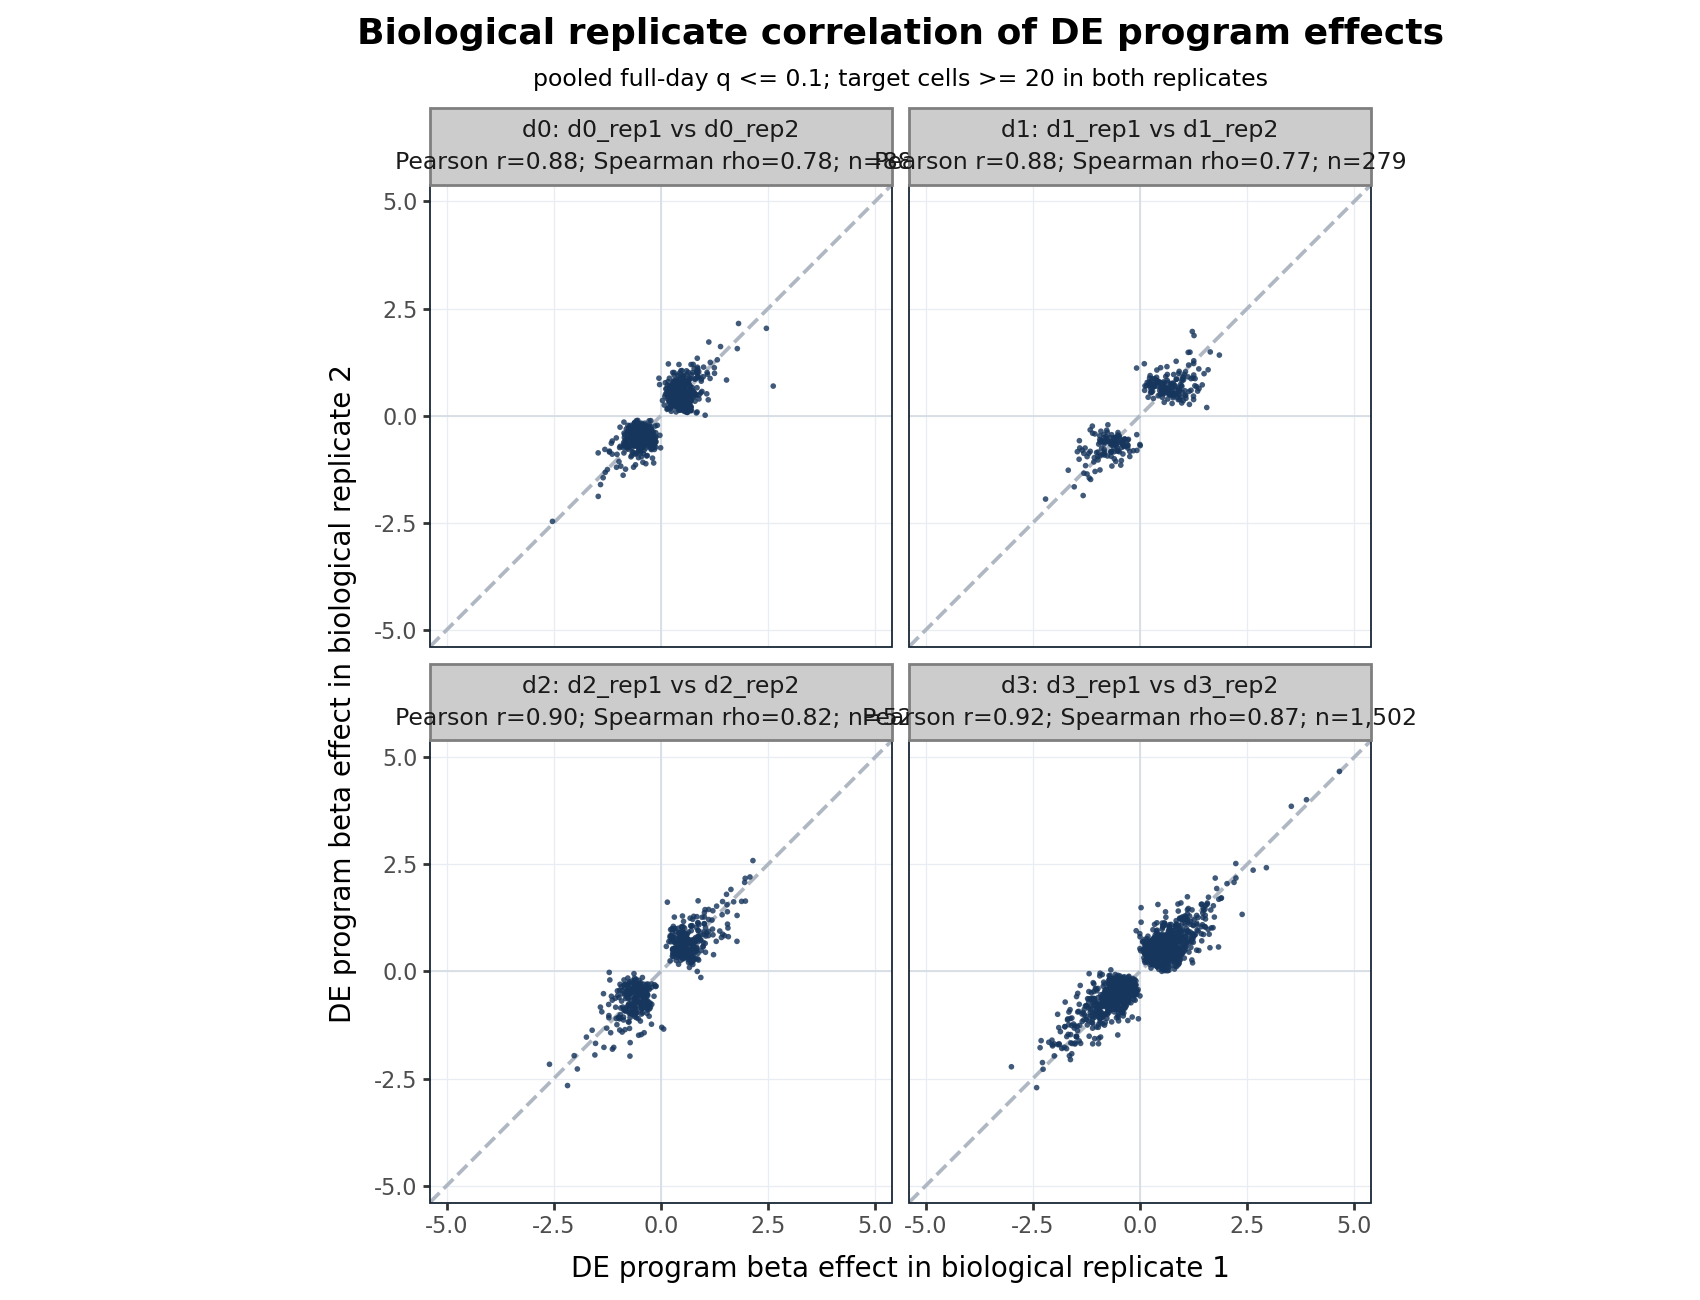

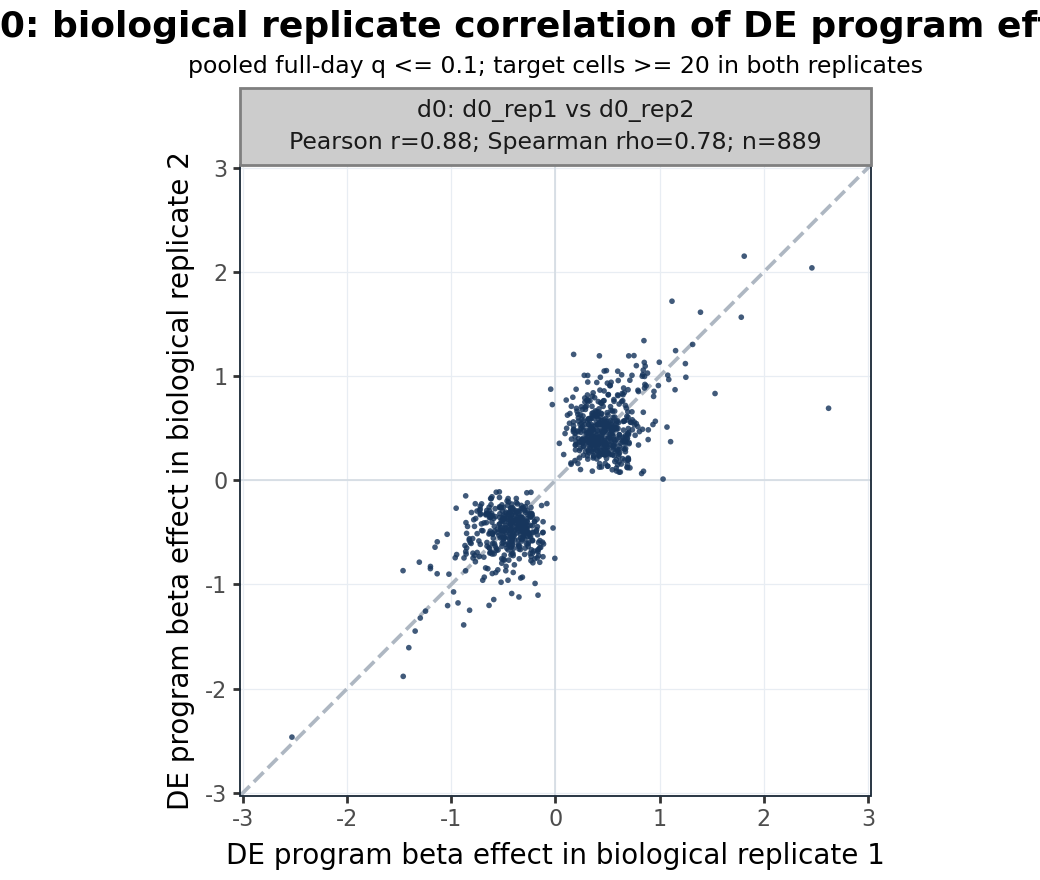

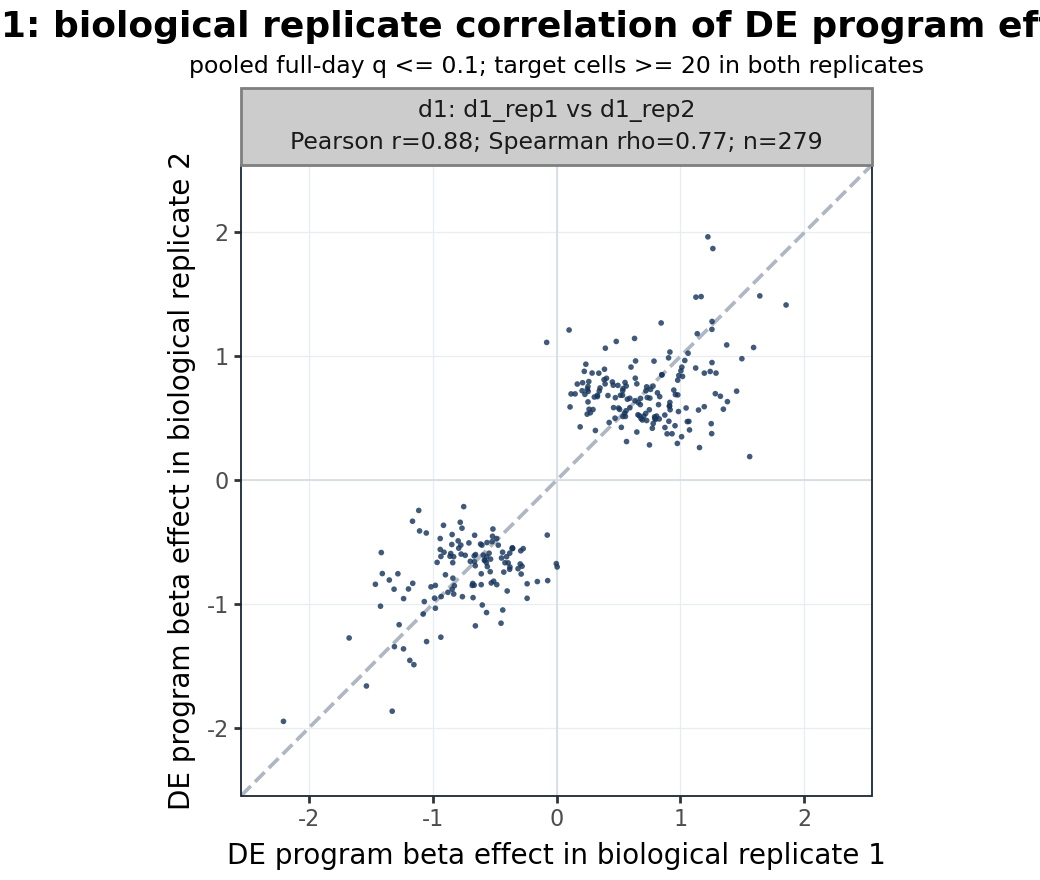

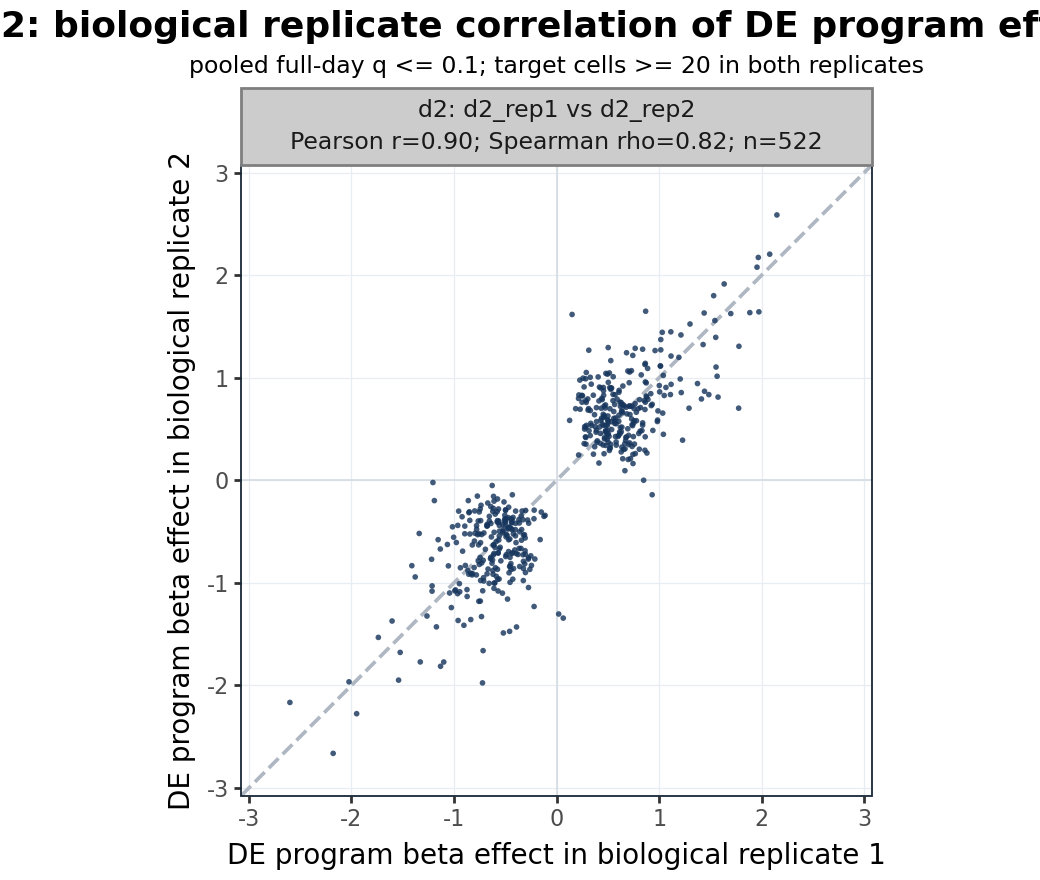

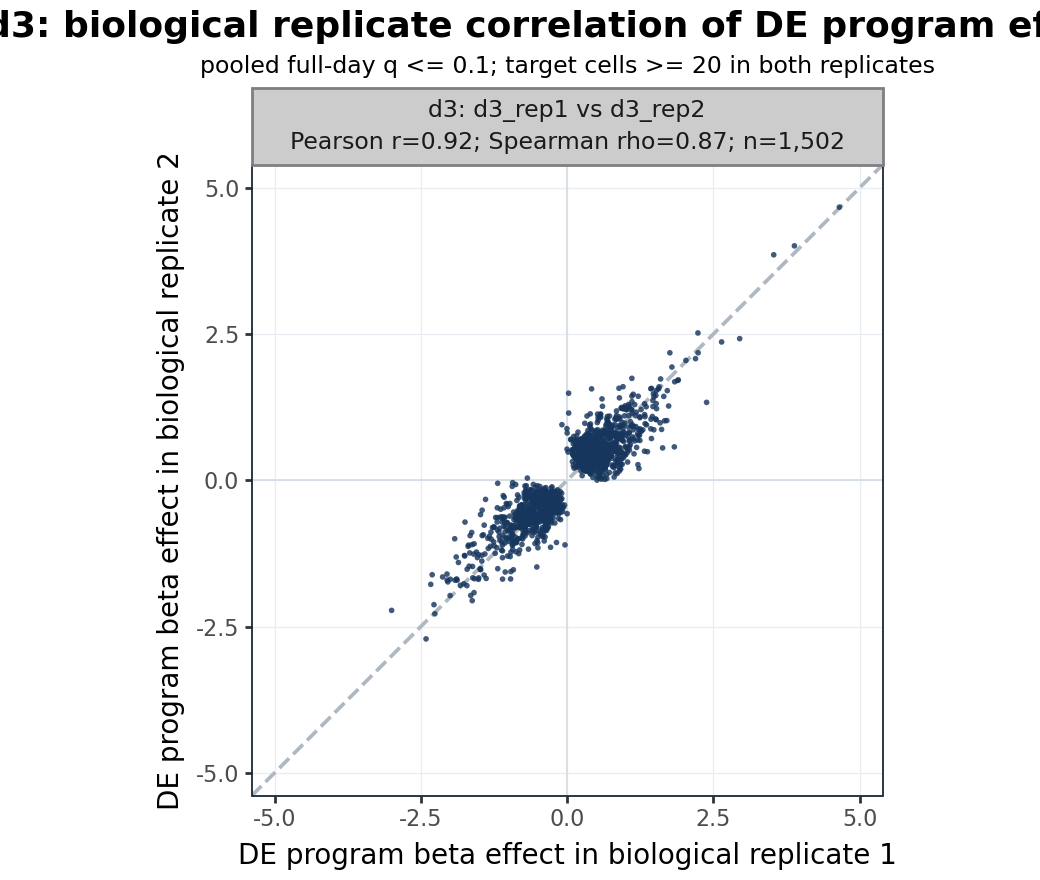


Saved data tables:
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/iPSC_EC_QQ_full_covariates_with_replicate_correlation_bundle/results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/biological_replicate_effects/plots/pooled_selected_replicate_effect_pairs_q_q0_1_top500_mincells20.csv
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/iPSC_EC_QQ_full_covariates_with_replicate_correlation_bundle/results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/biological_replicate_effects/plots/pooled_selected_replicate_effect_correlation_summary_q_q0_1_top500_mincells20.csv
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/iPSC_EC_QQ_full_covariates_with_replicate_correlation_bundle/results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/biological_replicate_effects/plots/pooled_selected_effect_counts_q_q0_1_top500_mincells20.csv

Saved combined plot files:
 PDF: /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/iP

,day,pdf,svg,png
0,d0,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,/oak/stanford/groups/engreitz/Users/tri/CodeBa...
1,d1,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,/oak/stanford/groups/engreitz/Users/tri/CodeBa...
2,d2,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,/oak/stanford/groups/engreitz/Users/tri/CodeBa...
3,d3,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,/oak/stanford/groups/engreitz/Users/tri/CodeBa...


In [27]:
from pathlib import Path
import itertools
import warnings

import numpy as np
import pandas as pd
import matplotlib as mpl
from IPython.display import display
from plotnine import (
    ggplot, aes,
    geom_abline, geom_hline, geom_vline, geom_point,
    facet_wrap,
    scale_x_continuous, scale_y_continuous,
    coord_equal,
    labs,
    theme_bw, theme,
    element_text, element_line, element_rect, element_blank,
)

# Keep text editable in Illustrator for PDF/SVG.
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42
mpl.rcParams["svg.fonttype"] = "none"


# ----------------------------
# User settings
# ----------------------------

MODEL_ROOT = Path("results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2").resolve()
REPL_ROOT = MODEL_ROOT / "biological_replicate_effects"
PLOT_DIR = REPL_ROOT / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

DAYS_FOR_PLOT = ["d0", "d1", "d2", "d3"]

# Prefer skew-calibrated p-values if present. Falls back to empirical.
POOLED_PVALUE_TYPE = "skew"   # "skew" or "empirical"

# Main selection mode.
# "q"        = use pooled q-value cutoff only
# "top_n"    = use top N pooled p-values per day/replicate-pair
# "q_or_top_n" = use q cutoff, but fall back to top N if too few points in a panel
SELECTION_MODE = "q"

POOLED_Q_CUTOFF = 0.10
TOP_N_PER_DAY_PAIR = 500
MIN_POINTS_BEFORE_TOP_N_FALLBACK = 50

# Independent QC filter. Set to 0 to disable.
MIN_TARGET_CELLS_PER_REP = 20

NTC_LABELS_FOR_PLOT = ["SAFE", "non-targeting", "NTC"]
NTC_KEY_SET = {str(x).strip().lower() for x in NTC_LABELS_FOR_PLOT}

POINT_COLOR = "#17365D"
GRID_COLOR = "#E8EDF3"
ZERO_LINE_COLOR = "#D5DCE3"
DIAGONAL_COLOR = "#AEB7C2"
BORDER_COLOR = "#182635"


# ----------------------------
# Helper functions
# ----------------------------

def normalize_program_name(x):
    s = str(x).strip()
    s = pd.Series([s]).str.replace(
        r"^(program|Program|usage|Usage|cnmf|cNMF)[_\s\-]*",
        "",
        regex=True,
    ).iloc[0]
    s = pd.Series([s]).str.replace(r"\.0$", "", regex=True).iloc[0]
    return s


def bh_qvalue(pvalues):
    p = pd.to_numeric(pd.Series(pvalues), errors="coerce").to_numpy(dtype=float)
    q = np.full(p.shape, np.nan, dtype=float)

    finite = np.isfinite(p)
    if finite.sum() == 0:
        return q

    pv = np.clip(p[finite], 0, 1)
    order = np.argsort(pv)
    ranked = pv[order] * len(pv) / np.arange(1, len(pv) + 1)
    ranked = np.minimum.accumulate(ranked[::-1])[::-1]

    q_finite = np.empty_like(pv)
    q_finite[order] = np.clip(ranked, 0, 1)
    q[finite] = q_finite
    return q


def read_pvalue_long_or_wide(path, day):
    path = Path(path)
    sep = "\t" if path.suffix.lower() in [".tsv", ".txt"] else ","

    header = pd.read_csv(path, sep=sep, nrows=0).columns.tolist()
    lower = {c.lower(): c for c in header}

    target_col = None
    for candidate in ["target_name", "target", "gene", "gene_name"]:
        if candidate in lower:
            target_col = lower[candidate]
            break

    program_col = None
    for candidate in ["program_name", "program", "cnmf_program", "component"]:
        if candidate in lower:
            program_col = lower[candidate]
            break

    pvalue_col = None
    for candidate in ["pvalue", "p_value", "pval", "p_val"]:
        if candidate in lower:
            pvalue_col = lower[candidate]
            break

    # Long format.
    if target_col is not None and program_col is not None and pvalue_col is not None:
        df = pd.read_csv(path, sep=sep)
        df = df[[target_col, program_col, pvalue_col]].copy()
        df = df.rename(
            columns={
                target_col: "target_name",
                program_col: "program_name",
                pvalue_col: "pooled_pvalue",
            }
        )

    # Wide target x program matrix.
    else:
        df_wide = pd.read_csv(path, sep=sep, index_col=0)
        df_wide.index = df_wide.index.astype(str)
        df_wide.columns = df_wide.columns.astype(str)
        df_wide.index.name = "target_name"

        df = (
            df_wide
            .reset_index()
            .melt(
                id_vars="target_name",
                var_name="program_name",
                value_name="pooled_pvalue",
            )
        )

    df["day"] = str(day)
    df["target_name"] = df["target_name"].astype(str).str.strip()
    df["program_name"] = df["program_name"].map(normalize_program_name)
    df["pooled_pvalue"] = pd.to_numeric(df["pooled_pvalue"], errors="coerce")
    df = df[np.isfinite(df["pooled_pvalue"])].copy()
    df["pooled_pvalue"] = df["pooled_pvalue"].clip(1e-300, 1.0)
    df["pooled_pvalue_source"] = path.name

    df = df[
        ~df["target_name"].str.strip().str.lower().isin(NTC_KEY_SET)
    ].copy()

    return df


def find_pooled_pvalue_file(day, preferred="skew"):
    day_dir = MODEL_ROOT / day

    type_order = []
    for ptype in [preferred, "skew", "empirical"]:
        if ptype not in type_order:
            type_order.append(ptype)

    exact_candidates = []
    for ptype in type_order:
        exact_candidates.extend([
            day_dir / f"{day}_target_pvalues_{ptype}_long.tsv",
            day_dir / f"{day}_target_pvalues_{ptype}_wide.tsv",
        ])

    for path in exact_candidates:
        if path.exists():
            return path

    # Fallback glob search.
    all_pvalue_files = sorted(day_dir.glob("*pvalue*"))
    usable = []
    for path in all_pvalue_files:
        name = path.name.lower()
        if "ntc" in name or "pseudo" in name or "qq" in name:
            continue
        if "target" not in name:
            continue
        usable.append(path)

    if not usable:
        raise FileNotFoundError(
            f"No pooled target p-value files found for {day} in {day_dir}."
        )

    def score(path):
        name = path.name.lower()
        score_value = 0
        if preferred in name:
            score_value -= 100
        if "long" in name:
            score_value -= 20
        if "wide" in name:
            score_value -= 10
        if "empirical" in name and preferred == "skew":
            score_value += 5
        return score_value

    usable = sorted(usable, key=score)
    return usable[0]


def find_effect_pairs_file():
    candidates = [
        PLOT_DIR / "DIAGNOSTIC_effect_pairs_with_target_cell_counts.csv",
        PLOT_DIR / "biological_replicate_DE_program_effect_pairs.csv",
        PLOT_DIR / "DIAGNOSTIC_recomputed_effect_pairs_from_current_beta_files.csv",
    ]

    for path in candidates:
        if path.exists():
            return path

    raise FileNotFoundError(
        "Could not find replicate beta effect-pair CSV in:\n"
        + "\n".join(str(p) for p in candidates)
    )


def summarize_replicate_correlations(df):
    rows = []

    for (day, pair), g in df.groupby(["day", "replicate_pair"], sort=False):
        signable = g[
            np.isfinite(g["beta_x"])
            & np.isfinite(g["beta_y"])
            & (g["beta_x"] != 0)
            & (g["beta_y"] != 0)
        ]

        sign_agreement = np.nan
        if len(signable) > 0:
            sign_agreement = (
                np.sign(signable["beta_x"].to_numpy())
                == np.sign(signable["beta_y"].to_numpy())
            ).mean()

        rows.append({
            "day": day,
            "replicate_pair": pair,
            "n_target_program_pairs": int(len(g)),
            "n_targets": int(g["target_name"].nunique()),
            "n_programs": int(g["program_name"].nunique()),
            "pearson_r": g["beta_x"].corr(g["beta_y"], method="pearson"),
            "spearman_r": g["beta_x"].corr(g["beta_y"], method="spearman"),
            "sign_agreement": sign_agreement,
            "min_pooled_pvalue": g["pooled_pvalue"].min(),
            "median_pooled_pvalue": g["pooled_pvalue"].median(),
            "max_pooled_pvalue": g["pooled_pvalue"].max(),
            "min_pooled_qvalue": g["pooled_qvalue"].min(),
            "median_pooled_qvalue": g["pooled_qvalue"].median(),
            "max_pooled_qvalue": g["pooled_qvalue"].max(),
        })

    return pd.DataFrame(rows)


def format_r(x):
    if pd.isna(x) or not np.isfinite(x):
        return "NA"
    return f"{x:.2f}"


def save_plotnine_vector_outputs(p, output_stem, width, height):
    output_stem = Path(output_stem)
    output_stem.parent.mkdir(parents=True, exist_ok=True)

    # PDF/SVG are Illustrator-editable. PNG is just a preview.
    p.save(output_stem.with_suffix(".pdf"), width=width, height=height, units="in", verbose=False)
    p.save(output_stem.with_suffix(".svg"), width=width, height=height, units="in", verbose=False)
    p.save(output_stem.with_suffix(".png"), width=width, height=height, units="in", dpi=300, verbose=False)


def make_replicate_scatter(plot_df, title, subtitle, width, height, ncol=2):
    axis_limit = float(
        np.nanmax(np.abs(plot_df[["beta_x", "beta_y"]].to_numpy(dtype=float)))
    )
    axis_limit = axis_limit * 1.05 if np.isfinite(axis_limit) and axis_limit > 0 else 1.0

    return (
        ggplot(plot_df, aes("beta_x", "beta_y"))
        + geom_hline(yintercept=0, color=ZERO_LINE_COLOR, size=0.35)
        + geom_vline(xintercept=0, color=ZERO_LINE_COLOR, size=0.35)
        + geom_abline(
            intercept=0,
            slope=1,
            linetype="dashed",
            color=DIAGONAL_COLOR,
            size=0.75,
        )
        + geom_point(
            size=1.15,
            alpha=0.82,
            color=POINT_COLOR,
            stroke=0,
        )
        + facet_wrap("~facet_label", ncol=ncol)
        + scale_x_continuous(limits=(-axis_limit, axis_limit))
        + scale_y_continuous(limits=(-axis_limit, axis_limit))
        + coord_equal()
        + labs(
            title=title,
            subtitle=subtitle,
            x="DE program beta effect in biological replicate 1",
            y="DE program beta effect in biological replicate 2",
        )
        + theme_bw(base_size=10)
        + theme(
            figure_size=(width, height),
            plot_title=element_text(size=13, weight="bold", ha="center"),
            plot_subtitle=element_text(size=8.5, ha="center"),
            strip_text=element_text(size=8.5),
            axis_title=element_text(size=10),
            axis_text=element_text(size=8),
            panel_grid_major=element_line(color=GRID_COLOR, size=0.45),
            panel_grid_minor=element_blank(),
            panel_border=element_rect(color=BORDER_COLOR, size=0.65),
        )
    )


# ----------------------------
# Load replicate-specific beta effect pairs
# ----------------------------

effect_pairs_path = find_effect_pairs_file()
effects = pd.read_csv(effect_pairs_path)

required_effect_cols = {
    "day",
    "target_name",
    "program_name",
    "beta_x",
    "beta_y",
    "replicate_x",
    "replicate_y",
    "replicate_pair",
}
missing_effect_cols = required_effect_cols.difference(effects.columns)
if missing_effect_cols:
    raise KeyError(
        f"{effect_pairs_path} is missing required columns: {sorted(missing_effect_cols)}"
    )

effects["day"] = effects["day"].astype(str)
effects["target_name"] = effects["target_name"].astype(str).str.strip()
effects["program_name"] = effects["program_name"].map(normalize_program_name)
effects["replicate_x"] = effects["replicate_x"].astype(str)
effects["replicate_y"] = effects["replicate_y"].astype(str)
effects["replicate_pair"] = effects["replicate_pair"].astype(str)
effects["beta_x"] = pd.to_numeric(effects["beta_x"], errors="coerce")
effects["beta_y"] = pd.to_numeric(effects["beta_y"], errors="coerce")

effects = effects[
    effects["day"].isin(DAYS_FOR_PLOT)
    & np.isfinite(effects["beta_x"])
    & np.isfinite(effects["beta_y"])
].copy()

effects = effects[
    ~effects["target_name"].str.strip().str.lower().isin(NTC_KEY_SET)
].copy()

print("Using replicate beta effect pairs from:")
print(" ", effect_pairs_path)
print("Effect-pair table shape:", effects.shape)


# ----------------------------
# Load pooled full-day p-values and compute q-values
# ----------------------------

pooled_tables = []
used_pvalue_files = []

for day in DAYS_FOR_PLOT:
    pvalue_path = find_pooled_pvalue_file(day, preferred=POOLED_PVALUE_TYPE)
    used_pvalue_files.append({"day": day, "pooled_pvalue_file": str(pvalue_path)})

    pvals_day = read_pvalue_long_or_wide(pvalue_path, day)
    pooled_tables.append(pvals_day)

pooled = pd.concat(pooled_tables, ignore_index=True, sort=False)

# BH correction within each day across all real target x program tests.
pooled["pooled_qvalue"] = np.nan
for day, idx in pooled.groupby("day").groups.items():
    pooled.loc[idx, "pooled_qvalue"] = bh_qvalue(pooled.loc[idx, "pooled_pvalue"])

used_pvalue_files = pd.DataFrame(used_pvalue_files)
print("\nUsing pooled full-day p-value files:")
display(used_pvalue_files)

print("\nPooled p-value table:")
display(
    pooled
    .groupby("day")
    .agg(
        n_target_program_pairs=("pooled_pvalue", "size"),
        n_targets=("target_name", "nunique"),
        n_programs=("program_name", "nunique"),
        min_p=("pooled_pvalue", "min"),
        min_q=("pooled_qvalue", "min"),
        n_q_le_0_10=("pooled_qvalue", lambda x: int((x <= 0.10).sum())),
        n_q_le_0_05=("pooled_qvalue", lambda x: int((x <= 0.05).sum())),
    )
    .reset_index()
)


# ----------------------------
# Merge pooled p-values onto replicate beta effects
# ----------------------------

merged = effects.merge(
    pooled[
        [
            "day",
            "target_name",
            "program_name",
            "pooled_pvalue",
            "pooled_qvalue",
            "pooled_pvalue_source",
        ]
    ],
    on=["day", "target_name", "program_name"],
    how="left",
    validate="many_to_one",
)

missing_p = merged["pooled_pvalue"].isna().mean()
print(f"\nFraction of replicate beta rows without matched pooled p-value: {missing_p:.3%}")

if missing_p > 0:
    print("Examples without pooled p-value match:")
    display(
        merged[merged["pooled_pvalue"].isna()]
        [["day", "target_name", "program_name"]]
        .drop_duplicates()
        .head(20)
    )

if missing_p > 0.05:
    warnings.warn(
        "More than 5% of rows did not match pooled p-values. "
        "Check target/program naming before interpreting the plot."
    )

merged = merged[np.isfinite(merged["pooled_pvalue"])].copy()


# ----------------------------
# Optional independent target-cell-count filter
# ----------------------------

base = merged.copy()

has_count_cols = {"n_target_cells_x", "n_target_cells_y"}.issubset(base.columns)

if MIN_TARGET_CELLS_PER_REP > 0 and has_count_cols:
    base["n_target_cells_x"] = pd.to_numeric(base["n_target_cells_x"], errors="coerce").fillna(0).astype(int)
    base["n_target_cells_y"] = pd.to_numeric(base["n_target_cells_y"], errors="coerce").fillna(0).astype(int)

    before = len(base)
    base = base[
        (base["n_target_cells_x"] >= MIN_TARGET_CELLS_PER_REP)
        & (base["n_target_cells_y"] >= MIN_TARGET_CELLS_PER_REP)
    ].copy()
    print(
        f"\nApplied target-cell filter: >= {MIN_TARGET_CELLS_PER_REP} cells in both reps. "
        f"Kept {len(base):,} / {before:,} rows."
    )

elif MIN_TARGET_CELLS_PER_REP > 0 and not has_count_cols:
    print(
        "\nTarget-cell count columns were not found, so MIN_TARGET_CELLS_PER_REP "
        "was not applied."
    )

else:
    print("\nTarget-cell count filter disabled.")


# ----------------------------
# Select effects using only full-day pooled p/q values
# ----------------------------

if SELECTION_MODE == "q":
    plot_df = base[base["pooled_qvalue"] <= POOLED_Q_CUTOFF].copy()
    plot_df["selection_rule"] = f"pooled q <= {POOLED_Q_CUTOFF}"
    selection_label = f"pooled full-day q <= {POOLED_Q_CUTOFF}"

elif SELECTION_MODE == "top_n":
    plot_df = (
        base
        .sort_values(["day", "replicate_pair", "pooled_pvalue"])
        .groupby(["day", "replicate_pair"], sort=False)
        .head(TOP_N_PER_DAY_PAIR)
        .copy()
    )
    plot_df["selection_rule"] = f"top {TOP_N_PER_DAY_PAIR} pooled p-values per panel"
    selection_label = f"top {TOP_N_PER_DAY_PAIR} full-day pooled p-values per panel"

elif SELECTION_MODE == "q_or_top_n":
    pieces = []
    for (day, pair), g in base.groupby(["day", "replicate_pair"], sort=False):
        q_sel = g[g["pooled_qvalue"] <= POOLED_Q_CUTOFF].copy()

        if len(q_sel) >= MIN_POINTS_BEFORE_TOP_N_FALLBACK:
            q_sel["selection_rule"] = f"pooled q <= {POOLED_Q_CUTOFF}"
            pieces.append(q_sel)
        else:
            top_sel = g.sort_values("pooled_pvalue").head(TOP_N_PER_DAY_PAIR).copy()
            top_sel["selection_rule"] = (
                f"fallback: top {TOP_N_PER_DAY_PAIR} pooled p-values "
                f"because q selection gave only {len(q_sel)} points"
            )
            pieces.append(top_sel)

    plot_df = pd.concat(pieces, ignore_index=True, sort=False)
    selection_label = (
        f"pooled full-day q <= {POOLED_Q_CUTOFF}; "
        f"fallback to top {TOP_N_PER_DAY_PAIR} pooled p-values if fewer than "
        f"{MIN_POINTS_BEFORE_TOP_N_FALLBACK} points"
    )

else:
    raise ValueError("SELECTION_MODE must be one of: 'q', 'top_n', 'q_or_top_n'.")

if plot_df.empty:
    raise ValueError(
        "No points selected. Try increasing POOLED_Q_CUTOFF, "
        "setting SELECTION_MODE='top_n', or lowering MIN_TARGET_CELLS_PER_REP."
    )

selection_counts = (
    plot_df
    .groupby(["day", "replicate_pair", "selection_rule"], dropna=False)
    .agg(
        n_points=("pooled_pvalue", "size"),
        n_targets=("target_name", "nunique"),
        n_programs=("program_name", "nunique"),
        min_pooled_pvalue=("pooled_pvalue", "min"),
        median_pooled_pvalue=("pooled_pvalue", "median"),
        max_pooled_pvalue=("pooled_pvalue", "max"),
        min_pooled_qvalue=("pooled_qvalue", "min"),
        median_pooled_qvalue=("pooled_qvalue", "median"),
        max_pooled_qvalue=("pooled_qvalue", "max"),
    )
    .reset_index()
)

print("\nSelected effects:")
display(selection_counts)


# ----------------------------
# Summarize and plot
# ----------------------------

summary = summarize_replicate_correlations(plot_df)

summary["facet_label"] = summary.apply(
    lambda r: (
        f"{r['day']}: {r['replicate_pair']}\n"
        f"Pearson r={format_r(r['pearson_r'])}; "
        f"Spearman rho={format_r(r['spearman_r'])}; "
        f"n={int(r['n_target_program_pairs']):,}"
    ),
    axis=1,
)

plot_df = plot_df.merge(
    summary[["day", "replicate_pair", "facet_label"]],
    on=["day", "replicate_pair"],
    how="left",
)

print("\nReplicate correlation after pooled full-day p/q selection:")
display(summary)

# Save data tables.
selection_tag = (
    f"{SELECTION_MODE}"
    f"_q{str(POOLED_Q_CUTOFF).replace('.', '_')}"
    f"_top{TOP_N_PER_DAY_PAIR}"
    f"_mincells{MIN_TARGET_CELLS_PER_REP}"
)

selected_pairs_path = PLOT_DIR / f"pooled_selected_replicate_effect_pairs_{selection_tag}.csv"
summary_path = PLOT_DIR / f"pooled_selected_replicate_effect_correlation_summary_{selection_tag}.csv"
selection_counts_path = PLOT_DIR / f"pooled_selected_effect_counts_{selection_tag}.csv"

plot_df.to_csv(selected_pairs_path, index=False)
summary.to_csv(summary_path, index=False)
selection_counts.to_csv(selection_counts_path, index=False)

# Combined all-day figure.
n_facets = int(plot_df["facet_label"].nunique())
ncol = 2 if n_facets > 1 else 1
combined_width = 8.5 if ncol == 2 else 5.2
combined_height = max(4.6, 3.25 * np.ceil(n_facets / ncol))

subtitle = selection_label
if MIN_TARGET_CELLS_PER_REP > 0 and has_count_cols:
    subtitle += f"; target cells >= {MIN_TARGET_CELLS_PER_REP} in both replicates"

p_combined = make_replicate_scatter(
    plot_df,
    title="Biological replicate correlation of DE program effects",
    subtitle=subtitle,
    width=combined_width,
    height=float(combined_height),
    ncol=ncol,
)

display(p_combined)

combined_stem = PLOT_DIR / f"pooled_selected_biological_replicate_DE_program_effect_correlation_all_days_{selection_tag}"
save_plotnine_vector_outputs(
    p_combined,
    combined_stem,
    width=combined_width,
    height=float(combined_height),
)

# Per-day figures.
per_day_saved = []

for day in DAYS_FOR_PLOT:
    day_df = plot_df[plot_df["day"].eq(day)].copy()
    if day_df.empty:
        continue

    day_n_facets = int(day_df["facet_label"].nunique())
    day_ncol = 1
    day_width = 5.2
    day_height = max(4.4, 3.6 * day_n_facets)

    p_day = make_replicate_scatter(
        day_df,
        title=f"{day}: biological replicate correlation of DE program effects",
        subtitle=subtitle,
        width=day_width,
        height=float(day_height),
        ncol=day_ncol,
    )

    display(p_day)

    day_stem = PLOT_DIR / f"{day}_pooled_selected_biological_replicate_DE_program_effect_correlation_{selection_tag}"
    save_plotnine_vector_outputs(
        p_day,
        day_stem,
        width=day_width,
        height=float(day_height),
    )

    per_day_saved.append({
        "day": day,
        "pdf": str(day_stem.with_suffix(".pdf")),
        "svg": str(day_stem.with_suffix(".svg")),
        "png": str(day_stem.with_suffix(".png")),
    })

print("\nSaved data tables:")
print(" ", selected_pairs_path)
print(" ", summary_path)
print(" ", selection_counts_path)

print("\nSaved combined plot files:")
print(" PDF:", combined_stem.with_suffix(".pdf"))
print(" SVG:", combined_stem.with_suffix(".svg"))
print(" PNG:", combined_stem.with_suffix(".png"))

print("\nSaved per-day plot files:")
display(pd.DataFrame(per_day_saved))